In [ ]:
try:
    spark.stop()
except Exception as e:
    print(e)

In [1]:
#!yarn application -status application_1782979140233_15545553
    # application_1782979140233_15429775
    
!yarn application -kill application_1782979140233_15545553

Application application_1782979140233_15545553 has already finished. 


In [1]:
from pathlib import Path
import sys
import os
import json
import math
import datetime
import warnings
from datetime import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
import joblib
import xgboost as xgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)
import findspark
findspark.init()

from pyspark.sql import SparkSession, DataFrame
from pyspark.sql import functions as func
from pyspark.sql.functions import col, desc, udf
from pyspark.sql.types import StructType, StructField, StringType

from ortools.linear_solver import pywraplp

warnings.filterwarnings("ignore")




# Backflow imports
from backflow import exp_setting
from backflow.programming import pgt
from backflow.calib import metrics as calib_metric
from backflow.calib import stats as calib_stats
from backflow.visualization import vis
from backflow.programming import simulation as pgtsimu
from backflow.utils import tools as bkfl_tools


# Matplotlib font

from pyspark.sql import SparkSession
spark3conf_best = {
    "spark.submit.deployMode": "client",
    "spark.yarn.queue": "root.growstrategy_group_prod",

    "spark.driver.memory": "24g",
    "spark.driver.memoryOverhead": "4g",

    "spark.dynamicAllocation.enabled": "true",
    "spark.dynamicAllocation.minExecutors": "80",
    "spark.dynamicAllocation.initialExecutors": "80",
    "spark.dynamicAllocation.maxExecutors": "120",
    "spark.dynamicAllocation.shuffleTracking.enabled": "true",

    "spark.executor.cores": "2",
    "spark.executor.memory": "12g",
    "spark.executor.memoryOverhead": "8g",

    "spark.default.parallelism": "1200",
    "spark.sql.shuffle.partitions": "1200",

    "spark.sql.adaptive.enabled": "true",
    "spark.sql.adaptive.coalescePartitions.enabled": "true",
    "spark.sql.adaptive.skewJoin.enabled": "true",
    "spark.sql.adaptive.advisoryPartitionSizeInBytes": "134217728",

    "spark.sql.autoBroadcastJoinThreshold": "104857600",
    "spark.sql.broadcastTimeout": "3000",

    "spark.network.timeout": "600s",
    "spark.executor.heartbeatInterval": "60s",

    "spark.memory.fraction": "0.8",
    "spark.memory.storageFraction": "0.3",

    "spark.sql.execution.arrow.pyspark.enabled": "true",
    "spark.sql.execution.arrow.maxRecordsPerBatch": "5000",

    "mapred.input.dir.recursive": "TRUE",
    "hive.mapred.supports.subdirectories": "TRUE",

    "spark.serializer": "org.apache.spark.serializer.KryoSerializer",
    "spark.kryoserializer.buffer.max": "1024m",

    "spark.yarn.dist.archives": "hdfs://difed/user/dm/ENV/dlflow/v2/py3.7.15_for_tfcluster_63.tgz",
    "spark.executorEnv.PYSPARK_PYTHON": "./py3.7.15_for_tfcluster_63.tgz/py3.7.15_for_tfcluster/bin/python3",

    "spark.extraListeners": "sparkmonitor.listener.JupyterSparkMonitorListener",

    "spark.sql.merge.mode": "FAST",
    "spark.sql.merge.enabled": "TRUE",
}

builder = (
    SparkSession
    .builder
    .appName("flowback_euen_v22")
    .master("yarn")
)

for k, v in spark3conf_best.items():
    builder = builder.config(k, v)

spark = builder.enableHiveSupport().getOrCreate()

print("[Info] Spark Version:", spark.version)
print("[Info] Spark Queue:", spark.conf.get("spark.yarn.queue"))
print("[Info] Spark App ID:", spark.sparkContext.applicationId)
print(spark.conf.get("spark.yarn.queue"))
print(spark.sparkContext.applicationId)

load metric func from causalml...


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Application Id: application_1782979140233_22360429, Tracking URL: http://bigdata-nmg-hdprm00.nmg01:8088/proxy/application_1782979140233_22360429/
INFO:SparkMonitorKernel:Client Connected ('127.0.0.1', 41034)


[Info] Spark Version: 3.2.0-101
[Info] Spark Queue: root.growstrategy_group_prod
[Info] Spark App ID: application_1782979140233_22360429
root.growstrategy_group_prod
application_1782979140233_22360429


In [2]:
plt.rcParams.update({
    # 按系统优先级填写中文字体
    "font.sans-serif": [
        "Microsoft YaHei",   # Windows 微软雅黑
        "SimHei",            # Windows 黑体
        "Arial Unicode MS",  # MacOS
        "PingFang SC",       # MacOS 苹方
        "WenQuanYi Zen Hei"  # Linux
    ],
    "axes.unicode_minus": False,  # 解决负号 '-' 变成方框
})

In [3]:
import datetime
from itertools import product

# 生成一段日期列表。从 start_dt 开始，一天一天往前或往后走，收集够 degree_days 天，最后排序并返回最后 degree_days 个日期
def smart_generate_dt_list(start_dt, degree_days, step=1, format="%Y-%m-%d", flag=1, 
                          ignore_dts=[]):
    
    strptime, strftime = datetime.datetime.strptime, datetime.datetime.strftime
    
    gen_dts = []
    curr_dt = start_dt
    
    while len(gen_dts)<degree_days:
        if curr_dt not in ignore_dts:
            gen_dts.append(curr_dt)
        
        __dt = strftime(strptime(curr_dt, format) - datetime.timedelta(1), format)
        if flag == 1:
            __dt = strftime(strptime(curr_dt, format) + datetime.timedelta(1), format)
            
        curr_dt = __dt
    
        
    gen_dts = sorted(gen_dts)
    if gen_dts[-1] != start_dt:
        gen_dts.append(start_dt)
    return sorted(gen_dts)[-degree_days:]

In [4]:
# delta_cac:每多带来1个增量完单，需要多花多少钱

def calculate_delta_metrics(df, group_name_1, group_name_2):
    # 计算通补delta cac、delta cvr函数
    # 取出当前 bucket 下的数据
    bucket_data = df

    # 分别取出 group_name_eve 为 group_name_1 和 group_name_2 的数据
    data_1 = bucket_data[bucket_data['group_name_eve'] == group_name_1]
    data_2 = bucket_data[bucket_data['group_name_eve'] == group_name_2]

    # 计算各自的总数量和 cost_7d 的总和
    total_count_1 = len(data_1)
    total_cost_1 = data_1['cost_7d'].sum()
    total_cvr_1 = data_1['pv_label_7d'].sum()

    total_count_2 = len(data_2)
    total_cost_2 = data_2['cost_7d'].sum()
    total_cvr_2 = data_2['pv_label_7d'].sum()

    # cac1，2:是人均成本; cvr1,2是人均7日完单。
    # 实验组每人平均成本 - 对照组每人平均成本 / 实验组每人平均订单 - 对照组每人平均订单
    cac_1 = total_cost_1 / total_count_1 if total_count_1 > 0 else 0
    cac_2 = total_cost_2 / total_count_2 if total_count_2 > 0 else 0

    cvr_1 = total_cvr_1 / total_count_1 if total_count_1 > 0 else 0
    cvr_2 = total_cvr_2 / total_count_2 if total_count_2 > 0 else 0

    delta_cost = cac_1 - cac_2
    delta_cvr = cvr_1 - cvr_2
    delta_cac = delta_cost / delta_cvr if delta_cvr != 0 else 0

    return delta_cac, delta_cvr

In [5]:
def calculate_percentile_thresholds(data, columns, quantiles):
    thresholds = {}
    for col in columns:
        if col in data.columns:
            # 使用 nvl 类似的功能，将 NaN 替换为 999
            filled_data = data[col].fillna(999)
            # 检查是否所有值都相同或为空
            if filled_data.nunique() > 1:  # 检查非空且唯一值的数量
                thresholds[col] = filled_data.quantile(quantiles).values
            else:
                # 如果所有值都相同，设置默认的阈值（这里设置为 None 或其他默认值）
                thresholds[col] = np.array([None] * len(quantiles))
    return thresholds # 一个字典，记录每个字段的 10 分位切分阈值。

In [6]:
def assign_quantile_buckets(data, quantile_thresholds, columns, quantiles):
    for col in columns:
        if col in data.columns:
            new_col_name = f"{col}_per"
            thresholds = quantile_thresholds[col]
            if thresholds is not None:
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                # 使用 pd.cut 将数据分到对应的区间中
                data[new_col_name] = pd.cut(data[col].fillna(999), bins=bins, labels=labels, include_lowest=True, duplicates='drop')
    return data

In [7]:
def move_threshold_main(data_pdf, group_name_list, columns, train_dates, val_dates):
    all_val_data = []
    quantile_thresholds_list = []
    # 滑动窗口处理
    for i in range(len(val_dates)):
        # 选取当前滑动窗口的train_dt和val_dt
        start_date = train_dates[i]
        train_dt = smart_generate_dt_list(start_dt=start_date, degree_days=7, flag=-1) # 基于smart_generate_dt_list对train日期向前扩展7天。
        val_dt = [val_dates[i]]
        print(train_dt)
        print(val_dt) # 验证 06-24 时，用 06-17~06-23 训练 ; 验证 06-25 时，也用 06-17~06-23 训练 ; 验证 06-26 时，也用 06-17~06-23 训练
        train_data = data_pdf[data_pdf['dt'].isin(train_dt)]
        quantiles = np.arange(0.1, 1.0, 0.1)  # 从0.1到0.9，9个分位点--10桶
        
        # 计算分位数阈值：quantile_thresholds
        '''
        {'cost_1':  [0.22, 0.35, ... , 0.88],
         'left65':  [left65的10%, left65的20%, ..., left65的90%],
         'left853': [left853的10%, left853的20%, ..., left853的90%] }
        '''
        quantile_thresholds = calculate_percentile_thresholds(train_data, columns, quantiles)
        quantile_thresholds_list.append(quantile_thresholds)
        
        
        # 对验证集数据进行分位数划分
        val_data = data_pdf[data_pdf['dt'].isin(val_dt)]

        for col in columns:
            if col in val_data.columns:
                new_col_name = f"{col}_per"
                thresholds = quantile_thresholds[col]
                # 使用训练集计算的阈值进行分位点划分
                bins = np.concatenate([[-np.inf], thresholds, [np.inf]])  # 包括 -inf 和 inf 的边界
                labels = [round(q, 1) for q in quantiles] + [1.0]  # 添加一个额外的标签 1.0
                val_data[new_col_name] = pd.cut(val_data[col].fillna(999), bins=bins, labels=labels, include_lowest=True)
        all_val_data.append(val_data)
        
    # 合并所有的val_data
    combined_val_data = pd.concat(all_val_data).reset_index(drop=True)    
    # 分配训练集
    quantiles = np.arange(0.1, 1.0, 0.1)
    use_train_all = assign_quantile_buckets(train_data, quantile_thresholds, columns, quantiles)
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    return quantile_thresholds_list, train_df, val_df



In [8]:
# cominbed_val_data
'''
pid   dt          group_name_eve   real_treatment   pv_label_7d   cost_7d     cost_1    left63   left853   left65   cost_1_per   left63_per   left853_per   left65_per   left65_minus_left63_per   left853_minus_left63_per
p001  2026-06-24  DS空白               0                   0          0.0       0.13     0.0021   0.0032    0.0040   0.3          0.4          0.5           0.6             0.7                      0.5
p002  2026-06-24  留存6张3元            1                   1          0.8       0.21     0.0065   0.0051    0.0072   0.5          0.8          0.7           0.9             0.8                      0.3
p003  2026-06-25  8元留存5张3           2                   2          1.4       0.44     0.0010   0.0044    0.0035   0.8          0.2          0.6           0.5             0.4                      0.9
p004  2026-06-30  10元留存5张3          4                   0          0.0       0.31     0.0080   0.0071    0.0095   0.7          0.9          0.8           1.0             0.9                      0.4
'''

'\npid   dt          group_name_eve   real_treatment   pv_label_7d   cost_7d     cost_1    left63   left853   left65   cost_1_per   left63_per   left853_per   left65_per   left65_minus_left63_per   left853_minus_left63_per\np001  2026-06-24  DS空白               0                   0          0.0       0.13     0.0021   0.0032    0.0040   0.3          0.4          0.5           0.6             0.7                      0.5\np002  2026-06-24  留存6张3元            1                   1          0.8       0.21     0.0065   0.0051    0.0072   0.5          0.8          0.7           0.9             0.8                      0.3\np003  2026-06-25  8元留存5张3           2                   2          1.4       0.44     0.0010   0.0044    0.0035   0.8          0.2          0.6           0.5             0.4                      0.9\np004  2026-06-30  10元留存5张3          4                   0          0.0       0.31     0.0080   0.0071    0.0095   0.7          0.9          0.8           1.0             0.9  

In [9]:
# 判断哪些分桶组合样本量足够，哪些组合样本量太小；样本够的先保留下来，样本不够的交给下一阶段继续合并。
# 在当前 stage 下，把组合分成“大样本组合”和“小样本组合”。


def split_small_data_debug(small_data, columns, all_columns, min_count):
    
    
    # 它不需要直接传 stage，因为调用时已经把当前 stage 拆成了columns, min_count = stage
    # 仅使用指定列进行分组和统计，但保留所有列, columns:当前 stage 用哪些字段判断样本量; all_columns:完整组合字段，用于后面生成映射
    combination_counts = small_data.groupby(columns)['pid'].count().reset_index(name='counts')
    print("step1.....")

    # 获取大于等于最小数量的组合
    large_combinations = combination_counts[combination_counts['counts'] >= min_count]
    small_combinations = combination_counts[combination_counts['counts'] < min_count]
    
    print("step2.....")


    # 根据组合数量大于等于最小数量的组合，拆出数据，并保留完整的列
    large_sample_data = small_data.merge(large_combinations[columns], on=columns, how='inner')
    large_sample_data = large_sample_data[all_columns]

    # 根据组合数量小于最小数量的组合，拆出数据，并保留完整的列
    small_sample_data = small_data.merge(small_combinations[columns], on=columns, how='inner')
    #small_sample_data = small_sample_data[all_columns]

    print("step3.....")

    # 计算大组合和小组合的数据统计
    large_use_combinations = large_sample_data.groupby(all_columns).size().reset_index(name='counts')
    small_use_combinations = small_sample_data.groupby(all_columns).size().reset_index(name='counts')
    large_use_combinations = large_use_combinations[large_use_combinations['counts'] > 0]
    small_use_combinations = small_use_combinations[small_use_combinations['counts'] > 0]
    
    print("step4.....")

    return large_sample_data, small_sample_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations

# large/small_sample_data        # 大样本/小样本 用户明细
# large/small_combinations        # 当前阶段字段组合统计
# large/small_use_combinations   # 完整字段组合统计，用于后面建立完整组合到 bucket_num 的映射。



In [10]:
# 生成“桶号 -> 完整组合列表

def generate_bucket_mapping_final(stage_combinations, all_columns, stage_columns):
    bucket_mapping = {}
    bucket_id = 0
    
    # 创建一个字典来存储每个组合的bucket_id，键为base_combination， 值为bucket_id
    combination_to_bucket = {}

    # 处理每个阶段的大样本数的组合
    for stage_idx, (large_combinations, small_combinations, columns) in enumerate(stage_combinations):
        if large_combinations is not None and not large_combinations.empty:
            for index, row in large_combinations.iterrows():
                # combination是完整组合值 (0.1 0.7 0.2 0.3)
                combination = tuple(row[col] for col in all_columns)
                # 对应于降级后的组合 如(0.8 0.2 8888 8888), (0.7, 8888, 8888, 8888), (0.6, 8888, 8888, 8888)
                base_combination = tuple(row[col] for col in columns) + (8888,) * (len(all_columns) - len(columns))
                # 如果此时字典没有这种base_combination，则为这种组合分配新桶号
                if base_combination not in combination_to_bucket:
                    combination_to_bucket[base_combination] = bucket_id
                    bucket_id += 1
                if combination_to_bucket[base_combination] not in bucket_mapping:
                    bucket_mapping[combination_to_bucket[base_combination]] = []
                bucket_mapping[combination_to_bucket[base_combination]].append(combination)
    
    # 处理最后一个阶段的小样本数的组合，归为一个桶
    if small_combinations is not None and not small_combinations.empty:
        final_bucket_id = bucket_id
        for index, row in small_combinations.iterrows():
            combination = tuple(row[col] for col in all_columns)
            if final_bucket_id not in bucket_mapping:
                bucket_mapping[final_bucket_id] = []
            bucket_mapping[final_bucket_id].append(combination)
    
    return bucket_mapping


In [11]:
# 给每一行用户数据打最终 bucket_num。

def assign_bucket_num(row, columns, reverse_mapping, train_flag=False):
    prob_tuple = tuple(row[col] for col in columns)
    if train_flag and reverse_mapping.get(prob_tuple) is None:
        print("训练集组合出现与mapping表不重合部分:" + str(prob_tuple))
        #raise ValueError("训练集组合出现与mapping表不重合部分")
    return reverse_mapping.get(prob_tuple, -1)  # -1 表示没有找到对应的 bucket

In [12]:
# 桶内实验组配平/放缩，然后计算桶内每个 treatment 相对 control 的增量效果。

def process_df(df, control_name, bucket_name = 'bucket_name'):
    """
    :param df: DataFrame, with columns ['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost']
    :param control_name: string, 控制组实验名称
    :return: DataFrame
    """
    new_df = pd.DataFrame()
    for name, group in df.groupby(['bucket_name']): # 将每个桶中不同折扣的数据进行放缩
        sample = group['in_uv'].sum() # 该分桶下的总人数，也即某一桶下所有treatment总和
        group['zoom_sample'] = sample 
        group['zoom_first'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_uv, axis=1)
        
        # 如果这个 bucket 里的全部人都走这个 treatment，按照该 treatment 观测到的人均完单/人均成本，预计会产生多少完单/成本？
        group['zoom_finish'] = group.apply(lambda row: row.zoom_sample/row.in_uv * row.finish_pv, axis=1) #桶级完单量
        group['zoom_cost'] = group.apply(lambda row: row.zoom_sample/row.in_uv * float(row.total_cost), axis=1)
        group['cvr_pv'] = group.apply(lambda row: row.zoom_finish/row.zoom_sample if row.zoom_sample != 0 else 0, axis=1)
        
        control_finish = group[group['exp_name'] == control_name]['zoom_finish'].sum()
        # control_first = group[group['exp_name'] == control_name]['zoom_first'].sum()
        control_cost = group[group['exp_name'] == control_name]['zoom_cost'].sum()
        group['zoom_delta_cost'] = group.apply(lambda row: row.zoom_cost - control_cost, axis=1)
        group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish, axis=1) # #桶级完单增量
        # group['zoom_delta_finish'] = group.apply(lambda row: row.zoom_finish - control_finish if row.zoom_finish - control_finish >= 0 else 0.1, axis=1)  #对于负弹的给一个较小的正值
        # group['zoom_delta_first'] = group.apply(lambda row: row.zoom_first - control_first, axis=1)
        new_df = new_df.append(group, ignore_index=True)
    return new_df


In [13]:

# 给后续的运筹定义基本的变量和编码
def data_prepare(df, para, bucket_col, group_name, control_name):
    """
    df: DataFrame, 数据源
    para: dict, 补贴形式
    bucket_col: string, 表示用户所在分桶的列
    group_name: string, 表示用户实际发券的分组
    control_name: string, Control组名称
    """
    dis_num = len(para)  # 补贴种类
    bucket_info = df[bucket_col].unique()  # 用户分桶信息
    bucket_num = len(bucket_info)  # 桶数量
    N = dis_num * bucket_num #决策量
    Y = np.ones((1, N))  # 目标人数最多 # 优化目标
    C = np.ones((1, N))  # 整体成本符合要求
    
    
    for i in range(bucket_num):  # 遍历桶
        bucket_id = bucket_info[i]  # 桶编码
        part_df = df[df[bucket_col] == bucket_id]  # 相应桶的数据
        sub = i * dis_num  # 索引位置。sub + para[row[group_name]]：就是当前桶、当前券型在 Y/C 数组里的位置
        used = set()
        if part_df[part_df[group_name] == control_name].empty:
            raise ValueError("出现空白为空的情况")
            
        # 把某一个桶里的每个券型，填到 OR-Tools 的 Y 和 C 数组里    
        for _, row in part_df.iterrows():
            if row[group_name] not in para:
                continue
            if row[group_name] == control_name:
                Y[0][sub + para[row[group_name]]] = row.zoom_delta_finish  # delta_CAC约束
                C[0][sub + para[row[group_name]]] = 0
            else:
                finish_uv = row.zoom_delta_finish  # delta_CAC约束
                coupon_cost = row.zoom_cost
                if finish_uv == 0 and coupon_cost == 0:
                    finish_uv = -100  # 保证不会被选择
                    coupon_cost = 0
                Y[0][sub + para[row[group_name]]] = finish_uv #相当于tao_ij，给这个bucket的用户发券j带来的增量。
                C[0][sub + para[row[group_name]]] = coupon_cost
            used.add(row[group_name])
        if len(used) != dis_num:
            raise ValueError("折扣数量不一致")

    C = C.reshape(-1)
    Y = Y.reshape(-1)
    return Y, C, bucket_info

In [14]:
def ortools_coupon(target, constraint, bucket_num, set_cost, para):
    """
    调用谷歌ortools包求解
    :param target: 目标表达式
    :param constraint: 约束表达式
    :param bucket_num: int, 桶数量
    :param set_cost: float, 成本信息
    :param para: dict, 补贴信息
    :return:
    """
    discount_num = len(para)
    N = len(target) # target：每个 bucket 每个券型的增量完单 PV
    st_exp_cost, obj_exp = None, None
    # 模型
    optimization_problem_type = 'SCIP'
    solver = pywraplp.Solver.CreateSolver(optimization_problem_type)
    
    # 创建N个二进制变量：每个 x[i] 表示：第 i 个“bucket + 券”方案是否被选中。
    x = [solver.IntVar(0, 1, 'x' + str(i)) for i in range(N)]
    
    # 优化目标：每个桶中不同券的delta_finish
    for i in range(N):
        if obj_exp is None:
            obj_exp = x[i] * target[i]
        else:
            obj_exp = obj_exp + x[i] * target[i] #累加成总增量完单
        #     print('obj_exp:')

    # 成本表达式: 每个桶中不同券的的cost 累加
    for i in range(N):
        if st_exp_cost is None:
            st_exp_cost = x[i] * constraint[i]
        else:
            st_exp_cost = st_exp_cost + x[i] * constraint[i] 
        #     print('st_exp_cost:')

    # 约束条件1: 每个桶只能选择一种折扣
    for i in range(bucket_num):
        bucket_vars = [x[j] for j in range(i * discount_num, (i + 1) * discount_num)]
        solver.Add(solver.Sum(bucket_vars) == 1)
        
    # 约束条件2: 成本约束 ：总成本 <= 目标CAC * 总增量完单
    solver.Add(st_exp_cost <= set_cost * obj_exp)   # st_exp_cost = 选中策略的总成本 ； obj_exp = 选中策略的总增量完单
    
    # 定义优化目标
    solver.Maximize(obj_exp) 
    # 调用求解器
    result_status = solver.Solve()
    res = []
    max_finish = 0
    if result_status == pywraplp.Solver.OPTIMAL:
        for i in range(len(x)):
            res.append(x[i].solution_value())
        max_finish = solver.Objective().Value()

    return (max_finish, res)

In [15]:
def or_convert(res, bucket_info, para):
    """
    :param res: 求解结果
    :param bucket_info: 桶信息
    :param para: 补贴信息
    :return: dict, 每个城市具体发券情况
    """
    new_para = dict((v, k) for k, v in para.items())
    discount_num = len(para)  # 补贴券数量
    coupon_ans = {}
    bucket_num = len(bucket_info) # 桶数量
    for i in range(bucket_num):
        tag = 0
        for j in range(i * discount_num, (i + 1) * discount_num):
            if res[j] == 1:
                index = j - i * discount_num
                coupon_ans[bucket_info[i]] = new_para[index]
                tag = 1
                break
        if tag == 0:
            try:
                coupon_ans[bucket_info[i]] = new_para[0]
            except:
                raise ValueError("未设置默认发券情况")
    return coupon_ans

In [16]:
def mock_use(df, coupon_ans, control_name, default_coupon, all_default_coupon_flag=False):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0
    
    # 处理传入的 coupon_ans 中的折扣
    for key, value in coupon_ans.items():
        treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
        control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    # 处理 bucket_name 为 -1 的情况
    default_keys = [-1]
    for key in default_keys:
        if key in df['bucket_name'].values:
            if all_default_coupon_flag:
                print("into all default & -1")
                value = coupon_ans[0] # 按通补指定的券来
                print(value)
            else:
                value = default_coupon # 为-1的桶分配线上的基线券
            treat_df = df[(df['bucket_name'] == key) & (df['exp_name'] == value)]
            control_df = df[(df['bucket_name'] == key) & (df['exp_name'] == control_name)]
            if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
                # 未匹配到数据，继续处理下一个 key
                continue
            treat_sample += treat_df['zoom_sample'].values[0]
            treat_finish_uv += treat_df['zoom_first'].values[0]
            treat_finish_pv += treat_df['zoom_finish'].values[0]
            treat_cost += treat_df['zoom_cost'].values[0]
            control_sample += control_df['zoom_sample'].values[0]
            control_finish_uv += control_df['zoom_first'].values[0]
            control_finish_pv += control_df['zoom_finish'].values[0]
            control_cost += control_df['zoom_cost'].values[0]
            if treat_sample != control_sample:
                raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost, 
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac] 

In [17]:
# 仿真时采用新聚合方式模拟
def mock_use_simulation(df, control_name):
    treat_sample, treat_finish_uv, treat_finish_pv, treat_cost = 0, 0, 0, 0
    control_sample, control_finish_uv, control_finish_pv, control_cost = 0, 0, 0, 0

    # 遍历每个桶，取桶名对应的干预动作作为treat的模拟数据
    for value in list(df['bucket_name'].unique()):
        treat_df = df[(df['bucket_name'] == value) & (df['exp_name'] == df['bucket_value'])] #取bucket_value的券对应的RCT数据
        control_df = df[(df['bucket_name'] == value) & (df['exp_name'] == control_name)]
        if treat_df.shape[0] == 0 or control_df.shape[0] == 0:
            # 未匹配到数据，继续处理下一个 key
            continue
        treat_sample += treat_df['zoom_sample'].values[0]
        treat_finish_uv += treat_df['zoom_first'].values[0]
        treat_finish_pv += treat_df['zoom_finish'].values[0]
        treat_cost += treat_df['zoom_cost'].values[0]
        control_sample += control_df['zoom_sample'].values[0]
        control_finish_uv += control_df['zoom_first'].values[0]
        control_finish_pv += control_df['zoom_finish'].values[0]
        control_cost += control_df['zoom_cost'].values[0]
        if treat_sample != control_sample:
            raise ValueError("数据源中，同一个桶下的人群未配平")

    delta_finish_uv = treat_finish_uv - control_finish_uv
    delta_finish_pv = treat_finish_pv - control_finish_pv
    delta_cost = treat_cost - control_cost
    delta_uv_cac = (treat_cost - control_cost) / delta_finish_uv
    delta_pv_cac = (treat_cost - control_cost) / delta_finish_pv
    delta_finish_ratio = delta_finish_uv / treat_sample
    delta_finish_pv_ratio = delta_finish_pv / treat_sample

    return [treat_sample, treat_finish_uv, treat_finish_pv, delta_finish_uv, delta_finish_pv, delta_cost,
            delta_finish_ratio, delta_finish_pv_ratio, delta_uv_cac, delta_pv_cac]

In [18]:
def simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para,
                          processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon,
                          mock_use_simulation, simulation_flag):
    """
    运行仿真并收集结果，绘制训练集和测试集结果曲线图。
    Parameters:
    Y:
    C:
    bucket_info: list, 桶信息
    group_name_list: 指定讨论干预组
    cost_list: list, 成本列表
    discount_para: dict, 折扣参数
    processed_data: DataFrame, 训练数据
    next_processed_data: DataFrame, 测试数据
    ortools_coupon: function, 计算优惠券的函数
    or_convert: function, 转换优惠券信息的函数
    mock_use: function, 模拟使用优惠券的函数
    mock_use_simulation: function, 新版模拟使用优惠券的函数
    simulation_flag: bool, 是否用新版模拟仿真效果
    """

    # 初始化结果列表
    train_x = []
    train_y = []
    test_x = []
    test_y = []
    discount_res_list = []
    discount_res_test_list = []
    discount_res = {}
    train_list = []
    test_list = []
    tongbu_list = []
    tongbu_all_list = []

    color_mapping = {
        '555': 'brown',
        '留存6张3元': 'darkgreen',
        '留存6张5元': 'darkorange',
        '8元留存5张3': 'purple',
        '8元留存5张5元': 'pink'
        # add others...
    }
    
    #basic_colors = ['red', 'blue', 'green', 'yellow', 
               #'orange', 'purple', 'black', 'gray']

    # 运行仿真并收集结果
    for cost_value in cost_list:
        max_finish, res = ortools_coupon(Y, C, len(bucket_info), cost_value, discount_para)
        print('max_finish', max_finish)
#         print('res', res)
        discount_res = or_convert(res, bucket_info, c)
#         print('discount_res', discount_res)
        discount_res[-1] = default_coupon  # 结果字典中添加关联不上的桶号-1发放兜底券
        discount_res_list.append(discount_res)

        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_res)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id #仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])

            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_res)
            discount_res_test = val_df.groupby('bucket_num')['bucket_num_discount'].first().to_dict()
            discount_res_test_list.append(discount_res_test)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = bucket_id  # 仿真合并时的新桶决策的是什么券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            # 计算训练集结果
            train_ans = mock_use(processed_data, discount_res, control_name='DS空白',
                                 default_coupon=default_coupon)  # '5折5折5折(cap5)'
            # 计算测试集结果
            test_ans = mock_use(next_processed_data, discount_res, control_name='DS空白', default_coupon=default_coupon)

        # 提取结果并添加到列表中
        train_x.append(train_ans[-1])
        train_y.append(train_ans[-3])
        test_x.append(test_ans[-1])
        test_y.append(test_ans[-3])
        train_list.append([cost_value, train_ans[-1], train_ans[-3], train_ans[-4], train_ans[-3]/train_ans[-4]])
        test_list.append([cost_value, test_ans[-1], test_ans[-3], test_ans[-4], test_ans[-3]/test_ans[-4]])

    use_group_name_list = [name for name in group_name_list if name != control_name]
    coordinates = {}
    coordinates_total = {}

    for group_name in use_group_name_list:
        # 计算遍历所有桶，指定发放同一种券的结果图
        mid = 5  # len(discount_res_list)//2
        discount_dict = discount_res_list[mid]
        if simulation_flag:
            # 仿真时基于决策的券类别进行二次合并
            # 计算训练集结果
            rct_pred_data = []
            train_df['bucket_num_discount'] = train_df['bucket_num'].map(discount_dict)
            for name, group in train_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            rct_pred_data = pd.DataFrame(rct_pred_data,
                                         columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                  'total_cost'])
            processed_data = process_df(rct_pred_data, control_name='DS空白')
            train_ans = mock_use_simulation(processed_data, control_name='DS空白')

            # 计算测试集结果
            next_rct_pred_data = []
            val_df['bucket_num_discount'] = val_df['bucket_num'].map(discount_dict)
            for name, group in val_df.groupby(['bucket_num_discount', 'group_name_eve']):
                bucket_id = name[0]
                bucket_value = group_name  # 仿真合并时的新桶决策的是什么券；通补时指定发放同一种券
                exp_name = name[1]
                in_uv = group['pid'].count()
                finish_uv = group['uv_label_7d'].sum()
                finish_pv = group['pv_label_7d'].sum()
                total_cost = group['cost_7d'].sum()
                next_rct_pred_data.append([bucket_id, bucket_value, exp_name, in_uv, finish_uv, finish_pv, total_cost])
            next_rct_pred_data = pd.DataFrame(next_rct_pred_data,
                                              columns=['bucket_name', 'bucket_value', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv',
                                                       'total_cost'])
            next_processed_data = process_df(next_rct_pred_data, control_name='DS空白')
            test_ans = mock_use_simulation(next_processed_data, control_name='DS空白')
        else:
            train_ans = mock_use(processed_data, discount_dict, control_name=control_name, default_coupon=group_name,
                                 all_default_coupon_flag=True)
            test_ans = mock_use(next_processed_data, discount_dict, control_name=control_name,
                                default_coupon=group_name, all_default_coupon_flag=True)
        # Extract coordinates
        train_x_single, train_y_single = train_ans[-1], train_ans[-3]
        test_x_single, test_y_single = test_ans[-1], test_ans[-3]
        tongbu_list.append([train_x_single, train_y_single, test_x_single, test_y_single])

        # Store the coordinates in the dictionary
        coordinates[group_name] = {
            'train': (train_x_single, train_y_single),
            'test': (test_x_single, test_y_single)
        }

        # 真正彻底的通补
        train_x_total, train_y_total = calculate_delta_metrics(train_df, group_name, control_name)
        test_x_total, test_y_total = calculate_delta_metrics(val_df, group_name, control_name)
        tongbu_all_list.append([train_x_total, train_y_total, test_x_total, test_y_total])

        coordinates_total[group_name] = {
            'train': (train_x_total, train_y_total),
            'test': (test_x_total, test_y_total)
        }

    # 绘制训练集结果曲线图
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 2, 1)
    plt.plot(train_x, train_y, marker='.', label='Train')
    for group_name, data in coordinates.items():
        train_x_single, train_y_single = data['train']
        plt.scatter([train_x_single], [train_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'train_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        train_x_total, train_y_total = data['train']
        plt.scatter([train_x_total], [train_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'train_{group_name}_total', marker='.')
    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Train Results')
    plt.legend()

    # 绘制测试集结果曲线图
    plt.subplot(1, 2, 2)
    plt.plot(test_x, test_y, marker='.', label='Test')

    # Plotting test data points
    for group_name, data in coordinates.items():
        test_x_single, test_y_single = data['test']
        plt.scatter([test_x_single], [test_y_single], color=color_mapping.get(group_name, 'blue'),
                    label=f'test_{group_name}_single', marker='.')

    for group_name, data in coordinates_total.items():
        test_x_total, test_y_total = data['test']
        plt.scatter([test_x_total], [test_y_total], color=color_mapping.get(group_name, 'red'),
                    label=f'test_{group_name}_total', marker='.')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('Test Results')
    plt.legend()

    plt.tight_layout()
    plt.show()

    return discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list

In [19]:

def plot_multi_results(train_list_1, test_list_1, tongbu_list_1, tongbu_all_list_1, 
    train_list_2, test_list_2, tongbu_list_2, tongbu_all_list_2, 
    group_name_list, control_name):
    
    # 根据 group_name_list 和 control_name 生成实际使用的组名列表
    use_group_name_list = [name for name in group_name_list if name != control_name]
    color_list = ['green', 'purple', 'orange', 'red', 'yellow']
    # 提取第一组数据的训练集 x 和 y
    train_x_1 = [x[1] for x in train_list_1]
    train_y_1 = [x[2] for x in train_list_1]

    # 提取第一组数据的测试集 x 和 y
    test_x_1 = [x[1] for x in test_list_1]
    test_y_1 = [x[2] for x in test_list_1]

    # 提取第二组数据的训练集 x 和 y
    train_x_2 = [x[1] for x in train_list_2]
    train_y_2 = [x[2] for x in train_list_2]

    # 提取第二组数据的测试集 x 和 y
    test_x_2 = [x[1] for x in test_list_2]
    test_y_2 = [x[2] for x in test_list_2]
    
    plt.figure(figsize=(12, 6))

    # 绘制第一组的训练集散点图
    plt.subplot(1, 2, 1)
    plt.plot(train_x_1, train_y_1, marker='.', color='blue', label='旧模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的训练集散点图
    plt.plot(train_x_2, train_y_2, marker='.', color='red', label='新模型训练')
    for (train_x_sync, train_y_sync, _, _), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([train_x_sync], [train_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (train_x_total, train_y_total, _, _), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([train_x_total], [train_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('训练集')
    plt.legend(fontsize=10)

    # 绘制第一组的测试集散点图
    plt.subplot(1, 2, 2)
    plt.plot(test_x_1, test_y_1, marker='.', color='blue', label='旧模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_1, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (旧)', marker='x')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_1, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 1)', marker='o')

    # 绘制第二组的测试集散点图
    plt.plot(test_x_2, test_y_2, marker='.', color='red', label='新模型预测')
    for (_, _, test_x_sync, test_y_sync), group_name, color in zip(tongbu_list_2, use_group_name_list, color_list):
        plt.scatter([test_x_sync], [test_y_sync], color=color, label=f'{group_name} (新)', marker='o')
#     for (_, _, test_x_total, test_y_total), group_name, color in zip(tongbu_all_list_2, use_group_name_list, color_list):
#         plt.scatter([test_x_total], [test_y_total], color=color, label=f'{group_name} (tongbu_all_way 2)', marker='o')

    plt.xlabel('delta_pv_cac')
    plt.ylabel('delta_finish_pv')
    plt.title('预测集')
    plt.legend(fontsize=10)

    plt.tight_layout()
    plt.show()

In [20]:
def main_try(use_train_all, combined_val_data, group_name_list, control_name,cost_list,
              all_columns, stages, discount_para, method=0,read_directly=True, show_tongbu=True, combinations=True, default_coupon='留存6张3元', simulation_flag =True):
    """
    调用函数，执行规划
    :param sql1: 查询规划训练数据
    :param sql2: 查询规划验证数据
    :param train_dt: 规划依赖数据 查询时间段
    :param val_dt: 规划验证数据依赖 时间段
    :param group_name_list: 指定讨论干预组
    :param control_name: 指定控制组名称，如'DS空白'
    :param cost_list: 规划的折扣范围—-定义成本
    :param all_columns: 规划的折扣范围—-定义成本
    :param stage_params: 规划的折扣范围—-定义成本
    :param method: 暂未使用, 指定不同规划方式。当method为1时, 选择根据分桶桶合并来进行规划、method为2时，选择聚类合并
    :return:
    """
    train_df = use_train_all[use_train_all['group_name_eve'].isin(group_name_list)]
    val_df = combined_val_data[combined_val_data['group_name_eve'].isin(group_name_list)]
    print(train_df.shape,val_df.shape)
    
    if stages:
        # 执行多阶段分层拆分
        use_data_input = train_df.copy()
        stage_results = []
        if combinations:
            # 使用全部分桶字段定义枚举值列表
            lists = []
            for i in all_columns:
                if i == 'fin_order_mini_28d':
                    lists.append([0.0, 1.0])
                else:
                    lists.append(pd.Categorical([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]))

            # 使用itertools.product生成所有组合
            all_combinations = pd.DataFrame(list(product(*lists)), columns = all_columns)

            # 基于所有组合创建和use_data_input字段一致的dataframe，其余字段置为none
            for column in use_data_input.columns:
                if column not in all_combinations.columns:
                    all_combinations[column] = np.nan #pd.NA
            all_combinations = all_combinations[use_data_input.columns.tolist()]
            use_data_input = use_data_input.append(all_combinations, ignore_index=True)
        current_data = use_data_input

        for i,stage in enumerate(stages):
            columns, min_count = stage
            print(columns,min_count)
            large_data, small_data, large_combinations, small_combinations, large_use_combinations, small_use_combinations = split_small_data_debug(current_data, columns, all_columns, min_count)
            current_data = small_data
            stage_results.append((large_use_combinations, small_use_combinations, columns))
            
            # add place 1 start.
            print(f"\n{'='*30} Stage {i} {'='*30}")
            if not large_combinations.empty:
                display(pd.DataFrame(large_combinations))
            else:
                print("\nNo Large Combinations in this stage")
            
            # 最后阶段显示分数打分的小频次组合
            if i == len(stages) - 1:
                print(f"\n{'='*30} Final Small Combinations {'='*30}")
                if not small_combinations.empty:
                    print(f"Small Combinations (<{min_count} samples):")
                    display(pd.DataFrame(small_combinations))
                else:
                    print("\nNo Small Combinations in final stage")
            # add place 1 end.
                    
        # 获取最后阶段的组合数据
        large_use_combinations = stage_results[-1][0]
        small_use_combinations = stage_results[-1][1]

        # 准备传入generate_bucket_mapping_final的组合数据
        stage_combinations = [(res[0], None, res[2]) for res in stage_results[:-1]] + [(large_use_combinations, small_use_combinations, stages[-1][0])]

        # 生成桶号映射
        bucket_mapping = generate_bucket_mapping_final(stage_combinations, all_columns, [stage[0] for stage in stages])
        reverse_mapping = {}
        mapping = bucket_mapping
        for bucket_num, combinations in mapping.items():
            for combination in combinations:
                reverse_mapping[combination] = bucket_num
    else:
        raise ValueError("未能匹配到数据")
        
    # 训练集分桶指定
    train_df['bucket_num'] = train_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping, train_flag=True)
    print(train_df['bucket_num'].unique())
    
    # 用新的分桶实现：用真实 RCT 数据计算每个桶里每种券的真实表现。也就是从“用户明细表”变成“桶 × 实验组”的聚合表。（train_df）
    rct_pred_data = []
    for name, group in train_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        rct_pred_data.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    rct_pred_data = pd.DataFrame(rct_pred_data,
                                 columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv',
                                          'finish_pv', 'total_cost'])
    '''
    bucket_name   exp_name      in_uv   finish_uv   finish_pv   total_cost
        0          DS空白        ...
        0         留存6张3        ...
        0        8元留存5张3      ...
    '''
    
    ## add place 2 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = rct_pred_data[rct_pred_data['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0])

    # 将对照值映射到原始数据
    rct_pred_data = rct_pred_data.merge(control_ratio.rename('control_ratio'), how='left', on='bucket_name')

    # 计算实验组数据：每个 bucket 内，每个 treatment 分别相对 control 的增量
    # delta_cvr:这个桶里，发这张券相比不发券，平均每个用户多带来多少 7 日完单。
    # delta_cac: 每多一个增量完单，需要多花多少钱(bucket+treatemnt粒度)
    rct_pred_data['delta_cvr'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['finish_pv'] / rct_pred_data['in_uv']) - rct_pred_data['control_ratio'],
        np.nan  # 对照组保持空值
    )
    rct_pred_data['delta_cac'] = np.where(
        rct_pred_data['exp_name'] != 'DS空白',
        (rct_pred_data['total_cost'] / rct_pred_data['in_uv']) / rct_pred_data['delta_cvr'],
        np.nan  # 对照组保持空值
    )
    

    # 删除临时列
    rct_pred_data.drop('control_ratio', axis=1, inplace=True)
    ## add place 2 end.

    print('rct_pred_data:', rct_pred_data)

    processed_data = process_df(rct_pred_data, control_name='DS空白')
    print('processed_data', processed_data)
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cost']/processed_data['zoom_delta_finish']
    processed_data['zoom_delta_cac'] = processed_data['zoom_delta_cac'].fillna(0)
    
    # print('processed_data', processed_data)
    # 基于 zoom_delta_cac 和 zoom_delta_finish 绘制分桶散点图
    # draw_data_plot(processed_data)

    print(discount_para)
    Y, C, bucket_info = data_prepare(processed_data, discount_para, bucket_col='bucket_name', group_name='exp_name', control_name='DS空白')
    print('Y',Y)
    print('C',C)
    print('bucket_info', bucket_info)
    # 为预测集添加 bucket_num 列
    val_df['bucket_num'] = val_df.apply(assign_bucket_num, axis=1, columns=all_columns, reverse_mapping=reverse_mapping)
    val_df['bucket_num'].unique()
    print(val_df['bucket_num'].unique())

    next_rct_pred = []
    for name, group in val_df.groupby(['bucket_num', 'group_name_eve']):
        bucket_id = name[0]
        exp_name = name[1]
        in_uv = group['pid'].count()
        finish_uv = group['uv_label_7d'].sum()
        finish_pv = group['pv_label_7d'].sum()
        total_cost = group['cost_7d'].sum()
        next_rct_pred.append([bucket_id, exp_name, in_uv, finish_uv, finish_pv, total_cost])
    next_rct_pred = pd.DataFrame(next_rct_pred, columns=['bucket_name', 'exp_name', 'in_uv', 'finish_uv', 'finish_pv', 'total_cost'])

    ## add place 3 start.
    # 计算各分桶且各RCT组下后验delta_cvr值
    control_ratio = next_rct_pred[next_rct_pred['exp_name'] == 'DS空白'].groupby('bucket_name').apply(
        lambda x: x['finish_pv'].iloc[0] / x['in_uv'].iloc[0]
    )

    # 将对照值映射到原始数据
    next_rct_pred = next_rct_pred.merge(
        control_ratio.rename('control_ratio'), 
        how='left', 
        on='bucket_name'
    )

    # 计算实验组数据
    next_rct_pred['delta_cvr'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['finish_pv'] / next_rct_pred['in_uv']) - next_rct_pred['control_ratio'],
        np.nan  # 对照组保持空值
    )
    next_rct_pred['delta_cac'] = np.where(
        next_rct_pred['exp_name'] != 'DS空白',
        (next_rct_pred['total_cost'] / next_rct_pred['in_uv']) / next_rct_pred['delta_cvr'],
        np.nan  # 对照组保持空值
    )

    # 删除临时列
    next_rct_pred.drop('control_ratio', axis=1, inplace=True)
    print('next_rct_pred_data:', next_rct_pred)
    ## add place 3 end.

    next_processed_data = process_df(next_rct_pred, control_name='DS空白')


    # 绘制仿真结果
    discount_res_list = []
    discount_res_test_list = []
    tongbu_all_list = []
    if show_tongbu:
        discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list = simulate_and_plot_all(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon, mock_use_simulation, simulation_flag) 
    else:
        discount_res_list, train_list, test_list, tongbu_list = simulate_and_plot(train_df, val_df, Y, C, bucket_info, group_name_list, control_name, cost_list, discount_para, processed_data, next_processed_data, ortools_coupon, or_convert, mock_use, default_coupon)    
    return train_df, val_df, bucket_mapping, reverse_mapping, processed_data, next_processed_data, discount_res_list, discount_res_test_list, train_list, test_list, tongbu_list, tongbu_all_list


In [21]:
EXE_DT = '2026-07-24'
__val_days = 14 #连续评估7日，截止 EXE_DT
CHECK_DTS = smart_generate_dt_list(start_dt=EXE_DT, degree_days=__val_days, flag=-1)
# VALDTS = CHECK_DTS[-__val_days:]
# VALDTS = sorted(VALDTS)
# CHECK_DTS = CHECK_DTS[-len(VALDTS)-1:]

CHECK_DTS = sorted(CHECK_DTS[-__val_days:])
CHECK_DTS

['2026-07-11',
 '2026-07-12',
 '2026-07-13',
 '2026-07-14',
 '2026-07-15',
 '2026-07-16',
 '2026-07-17',
 '2026-07-18',
 '2026-07-19',
 '2026-07-20',
 '2026-07-21',
 '2026-07-22',
 '2026-07-23',
 '2026-07-24']

In [22]:
# 样本日期：用于 base.dt 和预测表 label_dt
SEED_DTS = tuple(CHECK_DTS)
# 微信订单特征日期：base 日期前一天
WX_DTS = tuple(CHECK_DTS[:-1])
# 因果森林两期预测写入的分区 dt
UPLIFT_PRED_DTS = ('2026-07-17', '2026-07-24')

print("SEED_DTS:", SEED_DTS)
print("UPLIFT_PRED_DTS:", UPLIFT_PRED_DTS)

SEED_DTS: ('2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17', '2026-07-18', '2026-07-19', '2026-07-20', '2026-07-21', '2026-07-22', '2026-07-23', '2026-07-24')
UPLIFT_PRED_DTS: ('2026-07-17', '2026-07-24')


In [23]:
QUERY_ALL_FMT = """
with base as (
    select
        if(flowtree_group_name = 'DS空白', 'DS空白', group_name_eve) as group_name_eve,
        pid, oneid,
        flowtree_group_name,
        send_cnt, send_success_cnt, send_cost, send_remind_cost, outcall_cost, remind_cost, msg_coupon_cost as coupon_cost,outcall_coupon_cost,outcall_coupon2_cost, 
        cast(if(finish_cnt > 0, 1.0, 0.0) as double) as uv_label,
        finish_cnt as pv_label,
        cast(if(finish_cnt_7d > 0, 1.0, 0.0) as double) as uv_label_7d,
        finish_cnt_7d as pv_label_7d,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost, 0.0)+ nvl(outcall_coupon_cost, 0.0)+ nvl(outcall_coupon2_cost, 0.0)) as double) as cost,
        cast((nvl(send_cost, 0.0) + nvl(send_remind_cost, 0.0)+ nvl(outcall_cost, 0.0)+ nvl(remind_cost, 0.0)+ nvl(msg_coupon_cost_7d, 0.0)+ nvl(outcall_coupon_cost_7d, 0.0)+ nvl(outcall_coupon2_cost_7d, 0.0)) as double) as cost_7d,
        dt,
        if(fin_order_mini_28d >= 5, 1, 0.72) as weight, 
        if(fin_order_mini_28d >= 5, 1, 0) as fin_order_mini_28d
    from {traindata_tbname_via_growstrategy}
    where dt in {seed_dts}
    and new_exp = '迭代流量'
    and ((flowtree_group_name = '探索' and group_name_eve in ('8元留存5张3', '留存6张5元', '留存6张3元', '10元留存5张3')) or (flowtree_group_name = 'DS空白' and group_name_eve = 'control_group'))
),
prediction_agg as (
    select
        bs.*
        ,case when bs.group_name_eve = '10元留存5张3' then 4
              when bs.group_name_eve = '留存6张5元' then 3
              when bs.group_name_eve = '8元留存5张3' then 2
              when bs.group_name_eve = '留存6张3元' then 1
              when bs.group_name_eve = 'DS空白' then 0
              else null
         end as real_treatment
        ,mapping_data.model_treatment

        ,nvl(left63, 999) as left63
        ,nvl(left853, 999) as left853
        ,nvl(left65, 999) as left65
        ,nvl(left1053, 999) as left1053

     
        -- 兼容原运筹 notebook: 原来用 cost_1_per 分桶，这里用 coupon_prob 临时作为成本/核销倾向分数
        , nvl(mapping_data2.coupon_prob, 999) as coupon_prob

        ,case
            when nvl(left853, 999) = 999 or nvl(left63, 999) = 999 then 999
            else left853 - left63
        end as left853_minus_left63

        -- Note: 在这添加其余所需的 T 与 left63 的打分
        ,case
            when nvl(left65, 999) = 999 or nvl(left63, 999) = 999 then 999
            else left65 - left63
        end as left65_minus_left63

        ,case
            when nvl(left65, 999) = 999 or nvl(left853, 999) = 999 then 999
            else left65 - left853
        end as left65_minus_left853

        ,case
            when nvl(left1053, 999) = 999 or nvl(left63, 999) = 999 then 999
            else left1053 - left63
        end as left1053_minus_left63

        ,case
            when nvl(left1053, 999) = 999 or nvl(left853, 999) = 999 then 999
            else left1053 - left853
        end as left1053_minus_left853

        ,case
            when nvl(left1053, 999) = 999 or nvl(left65, 999) = 999 then 999
            else left1053 - left65
        end as left1053_minus_left65

    from base bs
    left join (
        select 
            pid 
            ,label_dt as dt
            ,treatment as model_treatment
            ,prediction[0] as left63
            ,prediction[1] as left853
            ,prediction[2] as left65
            ,prediction[3] as left1053
        from {mapping_data}
        where dt in {uplift_pred_dts}
        and label_dt in {seed_dts}
        and model = '{uplift_model}'
        and size(prediction) >= 4
    ) mapping_data on bs.pid = mapping_data.pid and bs.dt = mapping_data.dt
    left join (
        select 
            pid as oneid
            ,label_dt as dt
            ,weighted_prob as coupon_prob
        from {mapping_data}
        where 
            label_dt in {seed_dts}
            and model = '{coupon_model}'
    ) mapping_data2 on bs.oneid = mapping_data2.oneid and bs.dt = mapping_data2.dt
)

select *
from prediction_agg
"""



In [24]:
# 看 uplift 分区里到底有没有数据
spark.sql("""
select
    dt,
    model,
    count(*) as cnt,
    min(label_dt) as min_label_dt,
    max(label_dt) as max_label_dt,
    count(distinct label_dt) as label_dt_cnt
from dm.ut_mkt_backflow_model_inference_di
where model in (
    'feature_select_v2_causal_forest_test',
    'feature_select_v5_causal_forest_test'
)
group by dt, model
order by model, dt
""").show(100, False)

+----------+------------------------------------+------+------------+------------+------------+
|dt        |model                               |cnt   |min_label_dt|max_label_dt|label_dt_cnt|
+----------+------------------------------------+------+------------+------------+------------+
|2026-07-17|feature_select_v2_causal_forest_test|923446|2026-07-11  |2026-07-17  |7           |
|2026-07-24|feature_select_v2_causal_forest_test|933116|2026-07-18  |2026-07-24  |7           |
|2026-07-17|feature_select_v5_causal_forest_test|923446|2026-07-11  |2026-07-17  |7           |
|2026-07-24|feature_select_v5_causal_forest_test|933116|2026-07-18  |2026-07-24  |7           |
+----------+------------------------------------+------+------------+------------+------------+



In [25]:
all_rct_data_fmt_v2 = QUERY_ALL_FMT.format(
    seed_dts=SEED_DTS,
    uplift_pred_dts=UPLIFT_PRED_DTS,
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_v2_di',
    mapping_data='dm.ut_mkt_backflow_model_inference_di',
    uplift_model='feature_select_v2_causal_forest_test',
    coupon_model='bkfl_group_to_coupon_26_v2'
)

all_rct_data_df_v2 = spark.sql(all_rct_data_fmt_v2)
v2 = all_rct_data_df_v2.toPandas()
v2.head(10)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,left853,left65,left1053,coupon_prob,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65
0,DS空白,109200605,v1_00b16ac0b22941a37ed1c54136cd19e6,DS空白,0.0,0.0,0.000,0.0,0.0,0.0,...,0.008705,0.009016,0.011999,0.002480,0.000897,0.001208,0.000311,0.004191,0.003293,0.002982
1,8元留存5张3,70368796741421,v1_00bba4d630a1c72bd167ba594cd165d1,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.014926,0.013007,0.020143,0.005036,0.005156,0.003237,-0.001920,0.010373,0.005217,0.007136
2,留存6张3元,17594641311651,v1_00c701bb0e767d9d6c416ad8c4bd4717,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.002296,0.002993,0.009047,0.001405,-0.000787,-0.000090,0.000696,0.005964,0.006751,0.006054
3,10元留存5张3,3076800578159,v1_00ce85c283b1c942ba98db0ee25603ed,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.058041,0.073850,0.101661,0.064988,0.003470,0.019279,0.015810,0.047090,0.043620,0.027811
4,DS空白,17594823959348,v1_0161f0622fa5147f0440bb316e17a005,DS空白,0.0,0.0,0.000,0.0,0.0,0.0,...,0.057825,0.063021,0.050482,0.024930,0.011281,0.016477,0.005196,0.003939,-0.007342,-0.012539
5,留存6张3元,17593408186005,v1_01a98356f2e609d6e90c08acc99579d1,探索,2.0,1.0,0.021,0.0,0.0,0.0,...,0.007304,0.008587,0.017909,0.011735,-0.000694,0.000589,0.001283,0.009911,0.010604,0.009322
6,留存6张5元,35186030174034,v1_01c816ec4f2521a2ce8d6d33edb4fb25,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.004967,0.004086,0.008491,0.002087,0.002167,0.001286,-0.000881,0.005691,0.003524,0.004405
7,DS空白,17595457009933,v1_028800c4d3158aee8c2728f9ad4892da,DS空白,0.0,0.0,0.000,0.0,0.0,0.0,...,0.002923,0.003371,0.005521,0.001666,0.000478,0.000926,0.000447,0.003076,0.002597,0.002150
8,留存6张5元,17600373418206,v1_0337270d4e504889e9c25653c24debc2,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.029382,0.022459,0.032549,0.003568,0.003236,-0.003686,-0.006922,0.006404,0.003167,0.010090
9,10元留存5张3,17599646946161,v1_03aefc69245ab45dec6b715660ae3edc,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.020881,0.019169,0.027447,0.014963,0.008869,0.007158,-0.001712,0.015435,0.006566,0.008278


In [28]:
all_rct_data_fmt_v5 = QUERY_ALL_FMT.format(
    seed_dts=SEED_DTS,
    uplift_pred_dts=UPLIFT_PRED_DTS,
    traindata_tbname_via_growstrategy='dm.ut_alg_flowback_msg_outcall_label_v2_di',
    mapping_data='dm.ut_mkt_backflow_model_inference_di',
    uplift_model='feature_select_v5_causal_forest_test',
    coupon_model='bkfl_group_to_coupon_26_v2'
)

all_rct_data_df_v5 = spark.sql(all_rct_data_fmt_v5)
v5 = all_rct_data_df_v5.toPandas()
v5.head(10)

,group_name_eve,pid,oneid,flowtree_group_name,send_cnt,send_success_cnt,send_cost,send_remind_cost,outcall_cost,remind_cost,...,left853,left65,left1053,coupon_prob,left853_minus_left63,left65_minus_left63,left65_minus_left853,left1053_minus_left63,left1053_minus_left853,left1053_minus_left65
0,DS空白,109200605,v1_00b16ac0b22941a37ed1c54136cd19e6,DS空白,0.0,0.0,0.000,0.0,0.0,0.0,...,0.009227,0.009596,0.012108,0.002480,0.000771,0.001140,0.000369,0.003652,0.002881,0.002512
1,8元留存5张3,70368796741421,v1_00bba4d630a1c72bd167ba594cd165d1,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.015284,0.009131,0.018363,0.005036,0.004843,-0.001309,-0.006152,0.007922,0.003079,0.009232
2,留存6张3元,17594641311651,v1_00c701bb0e767d9d6c416ad8c4bd4717,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.003255,0.004408,0.006855,0.001405,0.001328,0.002482,0.001153,0.004928,0.003600,0.002447
3,10元留存5张3,3076800578159,v1_00ce85c283b1c942ba98db0ee25603ed,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.070386,0.070240,0.089453,0.064988,0.014802,0.014656,-0.000147,0.033869,0.019067,0.019214
4,DS空白,17594823959348,v1_0161f0622fa5147f0440bb316e17a005,DS空白,0.0,0.0,0.000,0.0,0.0,0.0,...,0.059429,0.052745,0.060731,0.024930,0.016423,0.009739,-0.006684,0.017725,0.001302,0.007986
5,留存6张3元,17593408186005,v1_01a98356f2e609d6e90c08acc99579d1,探索,2.0,1.0,0.021,0.0,0.0,0.0,...,0.014496,0.009513,0.017323,0.011735,0.003332,-0.001652,-0.004984,0.006158,0.002826,0.007810
6,留存6张5元,35186030174034,v1_01c816ec4f2521a2ce8d6d33edb4fb25,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.002840,0.005440,0.007377,0.002087,-0.000650,0.001950,0.002600,0.003888,0.004537,0.001937
7,DS空白,17595457009933,v1_028800c4d3158aee8c2728f9ad4892da,DS空白,0.0,0.0,0.000,0.0,0.0,0.0,...,0.004140,0.003839,0.006737,0.001666,0.001220,0.000918,-0.000302,0.003816,0.002597,0.002898
8,留存6张5元,17600373418206,v1_0337270d4e504889e9c25653c24debc2,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.025283,0.022825,0.023430,0.003568,0.002838,0.000380,-0.002458,0.000986,-0.001852,0.000606
9,10元留存5张3,17599646946161,v1_03aefc69245ab45dec6b715660ae3edc,探索,0.0,0.0,0.000,0.0,0.0,0.0,...,0.024330,0.021173,0.025720,0.014963,0.008146,0.004988,-0.003158,0.009536,0.001390,0.004547


In [27]:
scheme_name = 'v2'
data_df = v2.copy()

train_dates = ['2026-07-17']*7
val_dates = ['2026-07-18','2026-07-19','2026-07-20','2026-07-21','2026-07-22','2026-07-23','2026-07-24']
group_name_list = ['DS空白', '8元留存5张3', '留存6张3元', '留存6张5元','10元留存5张3']

# 分桶规则：columns 用来从原始模型分数生成 _per，all_columns 指定：后面组合桶到底用哪些 _per 字段，
# 比如 多加入 probcap8_minus_left63, 原始列值要在sql中计算好

columns = ['coupon_prob', 'left1053','left853', 'left63','left1053_minus_left63','left853_minus_left63']

# 对应这里的 all_columns和stages使用上 与上方使用的用于分桶的columns保持对应关系，并加上_per， 如: 'probcap8_minus_left65_per'
all_columns = ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per', 'left1053_minus_left63_per','left853_minus_left63_per'] 



In [28]:
# train_move_bucketing3[train_move_bucketing3['group_name_eve']=='10元留存5张3'].head(10)
# train_dates
# quantile_thresholds_list3

In [29]:
# 定义stages
group_name_list = ['DS空白', '留存6张3元','8元留存5张3','10元留存5张3'] #决定参与运筹的实验组/券型。

cost_list = np.arange(6.5, 9.0, 0.1) # 成本约束阈值
 
#discount_para = {'DS空白':0, '留存6张3元':1, '10元留存5张3':2, '留存6张5元':3}
discount_para = {'DS空白':0, '留存6张3元':1, '8元留存5张3':2, '10元留存5张3':3} # 券型编号


# 按照stage字段统计样本量，

'''
stages = [
    (['coupon_prob_per', 'left65_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['coupon_prob_per','left65_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] # 63,853,1053
'''

stages = [
    (['coupon_prob_per', 'left1053_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['coupon_prob_per','left1053_minus_left63_per','left63_per'], 15000),
    (['coupon_prob_per','left63_per'], 15000),
    (['coupon_prob_per'], 20000)
] 


In [30]:
# quantile_thresholds_list3, train_move_bucketing3, val_move_bucketing3 = move_threshold_main(v1, group_name_list, columns, train_dates, val_dates)

quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
    data_df,
    group_name_list,
    columns,
    train_dates,
    val_dates)

['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-23']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-24']


In [31]:
# quantile_thresholds
quantile_labels = [f"p{int(q * 100)}" for q in np.arange(0.1, 1.0, 0.1)]

threshold_df = pd.DataFrame(
    quantile_thresholds[0],
    index=quantile_labels
).T

threshold_df

,p10,p20,p30,p40,p50,p60,p70,p80,p90
coupon_prob,0.001548,0.002265,0.002993,0.004160,0.005949,0.007480,0.010251,0.021114,0.159388
left1053,0.006330,0.007984,0.009722,0.012210,0.016673,0.021514,0.030543,0.045116,0.067686
left853,0.002812,0.004124,0.005422,0.007110,0.010069,0.015259,0.023105,0.035747,0.052814
left63,0.002960,0.004074,0.005252,0.007041,0.009844,0.014532,0.021657,0.032264,0.047960
left1053_minus_left63,0.002157,0.003086,0.003840,0.004643,0.005630,0.007240,0.009569,0.012821,0.020774
left853_minus_left63,-0.002524,-0.001174,-0.000439,0.000105,0.000614,0.001198,0.002055,0.003534,0.006473


(838150, 41) (846981, 41)
['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 0 ==============================

No Large Combinations in this stage
['coupon_prob_per', 'left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,coupon_prob_per,left1053_minus_left63_per,left63_per,counts
899,0.9,1.0,1.0,21382


['coupon_prob_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,coupon_prob_per,left63_per,counts
0,0.1,0.1,24943
1,0.1,0.2,20570
2,0.1,0.3,16575
10,0.2,0.1,15057
11,0.2,0.2,16185
12,0.2,0.3,16838
34,0.4,0.5,15410
45,0.5,0.6,15760
46,0.5,0.7,17224
67,0.7,0.8,15146


['coupon_prob_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,coupon_prob_per,counts
0,0.1,21615
1,0.2,35682
2,0.3,83868
3,0.4,68501
4,0.5,51122
5,0.6,83900
6,0.7,53262
8,0.9,73921
9,1.0,71925



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,coupon_prob_per,counts
7,0.8,18628


[17  2  0  4 23 13 20 14 11 21  3 24 19  5  9 18 16  8  6  1 22 10 15 12
  7]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   2805      378.0     1083.0    4644.989   0.202515   
1             0   8元留存5张3   3055      365.0     1048.0    3873.270   0.159463   
2             0      DS空白  11036      700.0     2026.0     100.141        NaN   
3             0    留存6张3元   4486      522.0     1430.0    3858.295   0.135188   
4             1  10元留存5张3   3224        3.0       10.0      54.489   0.000596   
..          ...       ...    ...        ...        ...         ...        ...   
95           23    留存6张3元  14153      393.0     1158.0    3093.196   0.034263   
96           24  10元留存5张3   2512      108.0      323.0    1155.903   0.033610   
97           24   8元留存5张3   2388       76.0      258.0     614.702   0.013067   
98           24      DS空白  10066      256.0      956.0      65.324        NaN   
99           24 

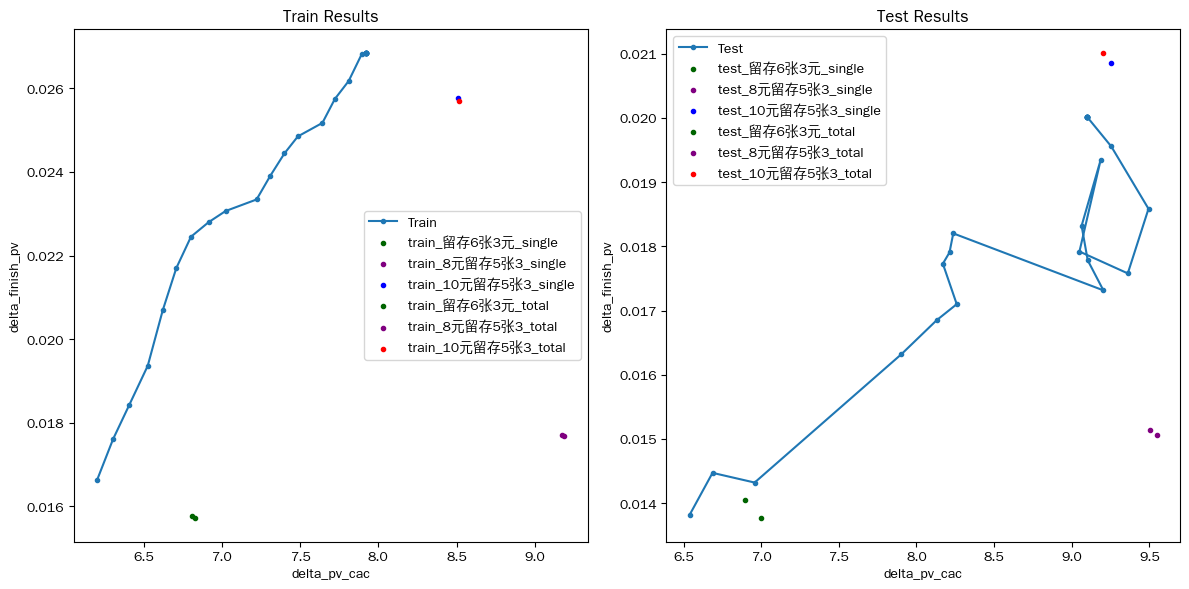

In [32]:
# 不使用笛卡尔积
# train_df3, val_df3, bucket_mapping13, reverse_mapping3, processed_data3, next_processed_data3, discount_res_list3, discount_res_test_list3,train_list1, test_list3, tongbu_list3, tongbu_all_list3 = main_try(train_move_bucketing3, val_move_bucketing3, group_name_list, control_name='DS空白',cost_list=cost_list, all_columns=all_columns, stages=stages, discount_para=discount_para, method=0,read_directly=False,show_tongbu=True,combinations=False)
outputs = main_try(
    train_bucketing,
    val_bucketing,
    group_name_list,
    control_name='DS空白',
    cost_list=cost_list,
    all_columns=all_columns,
    stages=stages,
    discount_para=discount_para,
    method=0,
    read_directly=False,
    show_tongbu=True,
    combinations=False,
    simulation_flag=True,
)
(train_df,val_df,bucket_mapping,reverse_mapping,processed_data,next_processed_data,discount_res_list,
 discount_res_test_list,train_list,test_list,tongbu_list,tongbu_all_list,) = outputs

In [33]:
test_result_df = pd.DataFrame(
    test_list,
    columns=[
        'set_cac', # OR-Tools 输入的 CAC 约束
        'sim_delta_pv_cac', # 验证集仿真出来的实际增量 PV CAC
        'sim_delta_pv_per_user', # 验证集仿真人均增量完单 PV
        'sim_delta_uv_per_user', # 验证集仿真人均增量完单 UV
        'pv_uv_ratio',
    ]
)

test_result_df

,set_cac,sim_delta_pv_cac,sim_delta_pv_per_user,sim_delta_uv_per_user,pv_uv_ratio
0,6.5,6.539817,0.013822,0.005534,2.497571
1,6.6,6.686619,0.014472,0.005768,2.509275
2,6.7,6.957764,0.014321,0.005823,2.459349
3,6.8,7.903449,0.016321,0.006007,2.716941
4,6.9,8.130400,0.016849,0.006288,2.679442
5,7.0,8.259432,0.017099,0.006426,2.660858
6,7.1,8.170055,0.017729,0.006571,2.697938
7,7.2,8.212887,0.017904,0.006618,2.705472
8,7.3,8.237050,0.018201,0.006700,2.716756
9,7.4,9.203936,0.017314,0.006492,2.667034


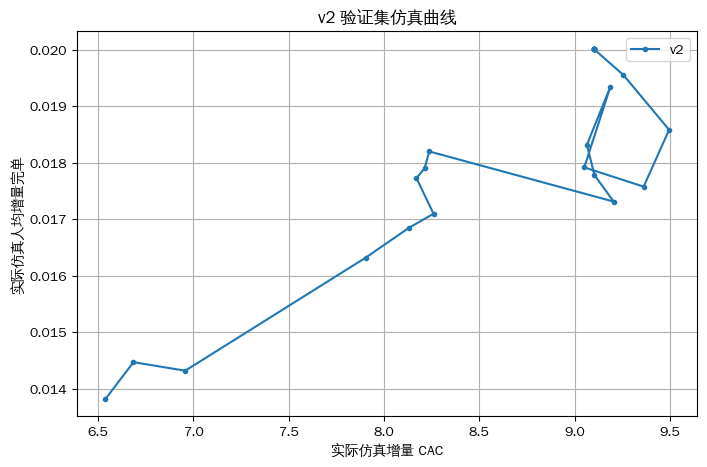

In [34]:
plt.figure(figsize=(8, 5))
plt.plot(
    test_result_df['sim_delta_pv_cac'],
    test_result_df['sim_delta_pv_per_user'],
    marker='.',
    label=scheme_name
)

plt.xlabel('实际仿真增量 CAC')
plt.ylabel('实际仿真人均增量完单')
plt.title(f'{scheme_name} 验证集仿真曲线')
plt.legend()
plt.grid(True)
plt.show()

In [34]:
# 两方案对比

In [35]:
scheme_dfs = {
    'feature_select_v2': v2,
    'feature_select_v5': v5,
}

train_dates = ['2026-07-17'] * 7
val_dates = ['2026-07-18', '2026-07-19', '2026-07-20', '2026-07-21', '2026-07-22', '2026-07-23', '2026-07-24']

# 分桶字段：65 可以只参与分桶，不参与运筹
columns = ['coupon_prob', 'left1053','left853', 'left63','left1053_minus_left63','left853_minus_left63']
all_columns = ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per', 'left1053_minus_left63_per','left853_minus_left63_per'] 

# 运筹候选动作
opt_group_name_list = ['DS空白', '留存6张3元', '8元留存5张3', '10元留存5张3']

discount_para = {
    'DS空白': 0,
    '留存6张3元': 1,
    '8元留存5张3': 2,
    '10元留存5张3': 3,
}

# cost_list = np.arange(6.5, 9.0, 0.1)
cost_list = np.arange(3.5, 6.5, 0.1)

stages = [
    (['coupon_prob_per', 'left1053_minus_left63_per','left853_minus_left63_per','left63_per'], 15000),
    (['coupon_prob_per','left1053_minus_left63_per','left63_per'], 15000),
    (['left853_minus_left63_per','left63_per'], 15000),
    (['left63_per'], 20000)
] 




========== running feature_select_v2 ==========
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-23']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-24']
(838150, 41) (846981, 41)
['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3...

,coupon_prob_per,left1053_minus_left63_per,left63_per,counts
899,0.9,1.0,1.0,21382


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left853_minus_left63_per,left63_per,counts
21,0.3,0.2,17409
30,0.4,0.1,17075
40,0.5,0.1,17741
42,0.5,0.3,15614
52,0.6,0.3,15607
87,0.9,0.8,16625
88,0.9,0.9,17628
97,1.0,0.8,16601
98,1.0,0.9,27240
99,1.0,1.0,17207


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,48906
1,0.2,66525
2,0.3,52549
3,0.4,84019
4,0.5,83944
5,0.6,84010
6,0.7,83816
7,0.8,50569
8,0.9,38825
9,1.0,44858



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[15  3  0  2 19 13  1 10 14 17  5 12 18  8  4 20  7 16 11  6  9]
rct_pred_data:     bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  delta_cvr  \
0             0  10元留存5张3   2805      378.0     1083.0    3548.989   0.202515   
1             0   8元留存5张3   3055      365.0     1048.0    2922.270   0.159463   
2             0      DS空白  11036      700.0     2026.0      50.141        NaN   
3             0    留存6张3元   4486      522.0     1430.0    2400.295   0.135188   
4             1  10元留存5张3   2241        5.0       38.0      50.564   0.009011   
..          ...       ...    ...        ...        ...         ...        ...   
79           19    留存6张3元   7745      169.0      406.0     751.734   0.006552   
80           20  10元留存5张3   5819      255.0      883.0    2964.985   0.102981   
81           20   8元留存5张3   5909      230.0      740.0    2349.62

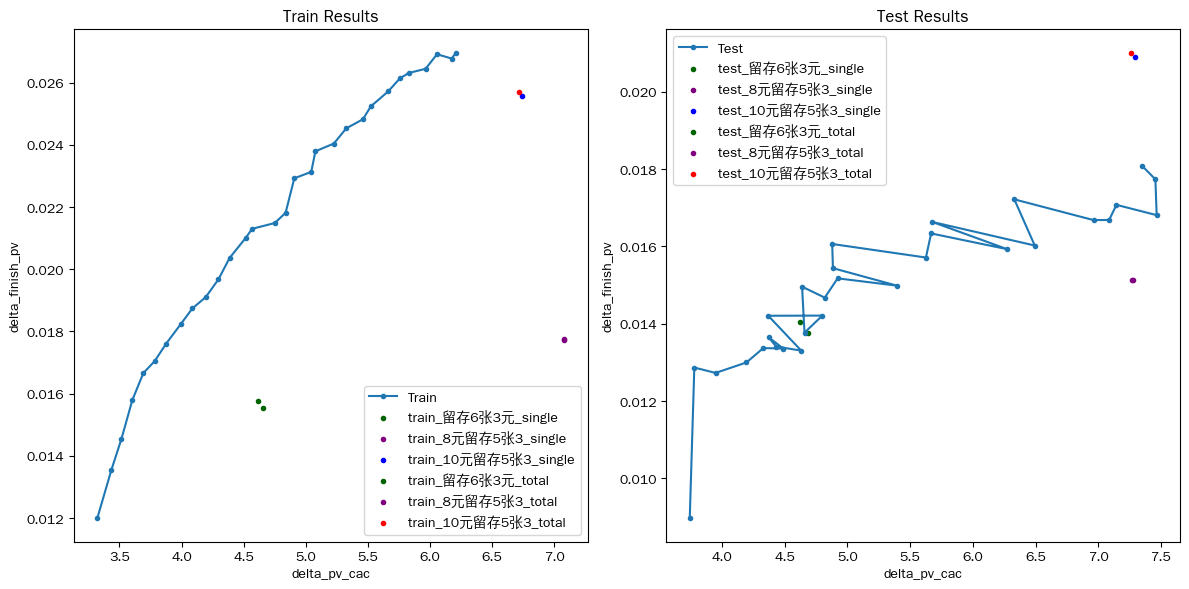


========== running feature_select_v5 ==========
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-23']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-24']
(838150, 41) (846981, 41)
['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3...

,coupon_prob_per,left1053_minus_left63_per,left63_per,counts
899,0.9,1.0,1.0,17277


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left853_minus_left63_per,left63_per,counts
5,0.1,0.6,16895
6,0.1,0.7,15597
13,0.2,0.4,16992
14,0.2,0.5,17989
22,0.3,0.3,18737
23,0.3,0.4,17787
31,0.4,0.2,19275
32,0.4,0.3,20266
41,0.5,0.2,21899
42,0.5,0.3,15512


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,42227
1,0.2,42506
2,0.3,29572
3,0.4,49066
4,0.5,65986
5,0.6,66925
6,0.7,52148
7,0.8,62562
8,0.9,31960



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
9,1.0,18668


[23 19  0  5  2 26  4  3 18 27  7 25  8 12 22  9 14 21 24 20 15 16  6 28
 13  1 11 10 17]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2265      299.0      802.0    2737.636   
1              0   8元留存5张3   2430      293.0      784.0    2175.333   
2              0      DS空白   8929      568.0     1505.0      50.141   
3              0    留存6张3元   3653      424.0     1103.0    1973.302   
4              1  10元留存5张3   2572       11.0       46.0     114.363   
..           ...       ...    ...        ...        ...         ...   
111           27    留存6张3元   6394      164.0      341.0     503.673   
112           28  10元留存5张3   2480      148.0      438.0    1443.428   
113           28   8元留存5张3   2654      133.0      410.0    1071.324   
114           28      DS空白   9665      259.0      785.0       0.000   
115           28    留存6张3元   3869      187.0      465.0     774.012   

     delta_cvr  delta_cac  
0     0.185532

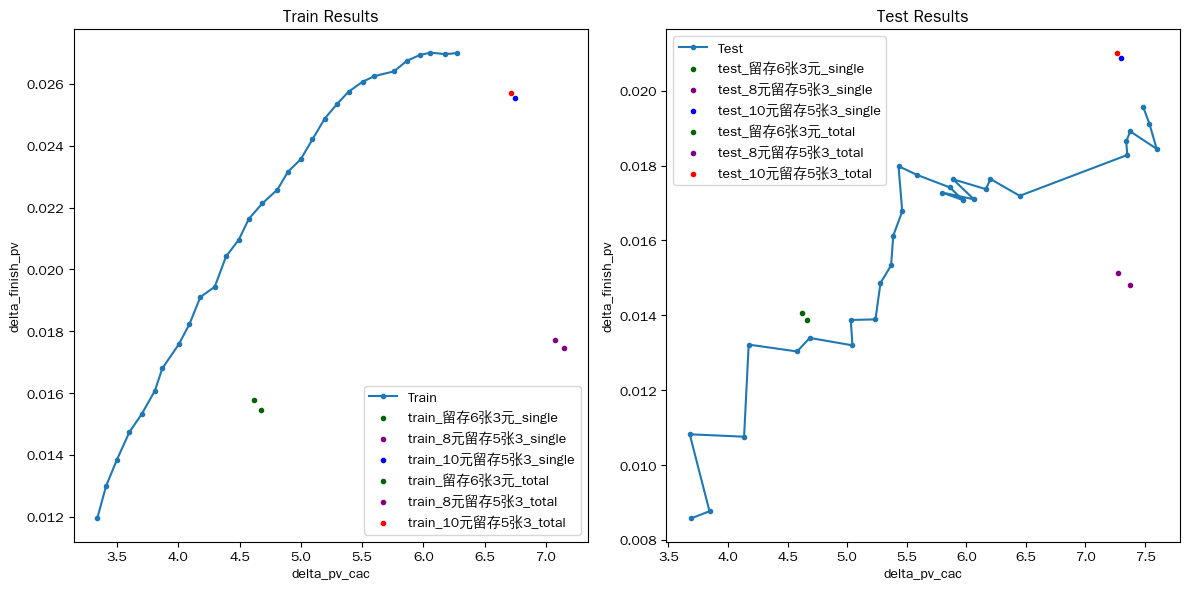

In [36]:
results = {}

for scheme_name, data_df in scheme_dfs.items():
    print(f'\n========== running {scheme_name} ==========')

    quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
        data_df.copy(),
        opt_group_name_list,
        columns,
        train_dates,
        val_dates
    )

    outputs = main_try(
        train_bucketing,
        val_bucketing,
        opt_group_name_list,
        control_name='DS空白',
        cost_list=cost_list,
        all_columns=all_columns,
        stages=stages,
        discount_para=discount_para,
        method=0,
        read_directly=False,
        show_tongbu=True,
        combinations=False,
        simulation_flag=True,
    )

    results[scheme_name] = {
        'quantile_thresholds': quantile_thresholds,
        'train_df': outputs[0],
        'val_df': outputs[1],
        'bucket_mapping': outputs[2],
        'reverse_mapping': outputs[3],
        'processed_data': outputs[4],
        'next_processed_data': outputs[5],
        'discount_res_list': outputs[6],
        'discount_res_test_list': outputs[7],
        'train_list': outputs[8],
        'test_list': outputs[9],
        'tongbu_list': outputs[10],
        'tongbu_all_list': outputs[11],
    }

In [37]:
def build_result_df(result_list, scheme_name, data_type):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr', # 人均增量完单 PV = 增量完单量 / 仿真人数
            '实际增量首单cvr',# 人均增量完单 UV = 增量完单用户数 / 仿真人数,“是否有首个完单/是否转化”的用户数
            '留存频次',
        ]
    )
    df['scheme'] = scheme_name
    df['data_type'] = data_type
    return df


summary_list = []

for scheme_name, res in results.items():
    summary_list.append(build_result_df(res['train_list'], scheme_name, 'train'))
    summary_list.append(build_result_df(res['test_list'], scheme_name, 'test'))

summary_df = pd.concat(summary_list, ignore_index=True)

summary_df[
    ['scheme', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,scheme,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,feature_select_v2,train,3.5,3.321041,0.011990,0.004267,2.810164
1,feature_select_v2,train,3.6,3.434755,0.013550,0.005116,2.648598
2,feature_select_v2,train,3.7,3.515678,0.014545,0.005308,2.740419
3,feature_select_v2,train,3.8,3.603586,0.015797,0.005873,2.689840
4,feature_select_v2,train,3.9,3.691960,0.016662,0.006191,2.691498
...,...,...,...,...,...,...,...
115,feature_select_v5,test,6.0,7.341998,0.018647,0.007223,2.581612
116,feature_select_v5,test,6.1,7.375911,0.018911,0.007279,2.598063
117,feature_select_v5,test,6.2,7.597456,0.018446,0.007241,2.547287
118,feature_select_v5,test,6.3,7.537326,0.019111,0.007352,2.599546


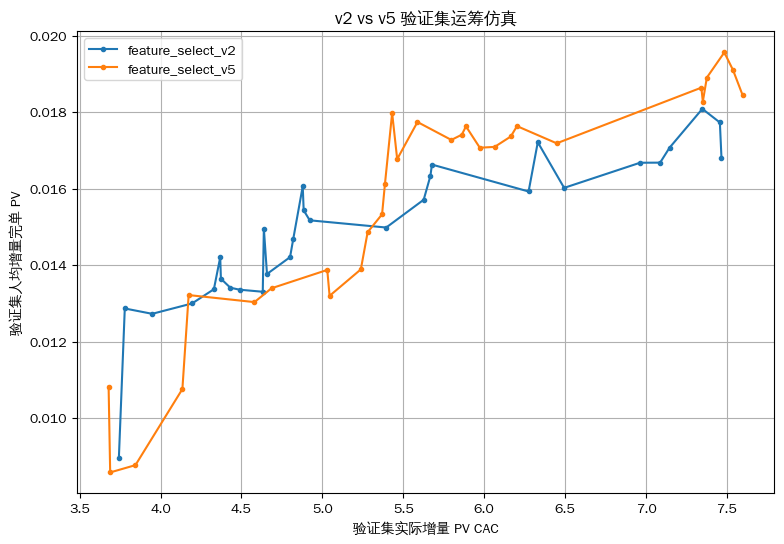

In [38]:
plt.figure(figsize=(9, 6))

for scheme_name in results.keys():
    plot_df = summary_df[
        (summary_df['scheme'] == scheme_name) &
        (summary_df['data_type'] == 'test')
     ].sort_values('实际增量cac')
   #   ].sort_values('约束cac')   # 按约束 cac 顺序连线

    plt.plot(
        plot_df['实际增量cac'],
        plot_df['实际增量cvr'],
        marker='.',
        label=scheme_name
    )

plt.xlabel('验证集实际增量 PV CAC')
plt.ylabel('验证集人均增量完单 PV')
plt.title('v2 vs v5 验证集运筹仿真')
plt.legend()
plt.grid(True)
plt.show()

In [39]:
v2_test_summary = (
    summary_df[
        (summary_df['scheme'] == 'feature_select_v2') &
        (summary_df['data_type'] == 'test')
    ]
    .sort_values('约束cac')
    .reset_index(drop=True)
)

v2_test_summary[
    ['约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,3.5,3.742407,0.008962,0.003318,2.701369
1,3.6,3.778890,0.012867,0.004966,2.590788
2,3.7,3.948241,0.012727,0.005006,2.542367
3,3.8,4.194414,0.012998,0.005248,2.476912
4,3.9,4.329527,0.013370,0.005384,2.483427
5,4.0,4.488300,0.013358,0.005369,2.487880
6,4.1,4.372892,0.013645,0.005502,2.480065
7,4.2,4.431067,0.013410,0.005444,2.463213
8,4.3,4.631531,0.013304,0.005418,2.455557
9,4.4,4.368638,0.014206,0.005676,2.502989


In [40]:
v5_test_summary = (
    summary_df[
        (summary_df['scheme'] == 'feature_select_v5') &
        (summary_df['data_type'] == 'test')
    ]
    .sort_values('约束cac')
    .reset_index(drop=True)
)

v5_test_summary[
    ['约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,3.5,3.688618,0.008575,0.003398,2.523395
1,3.6,3.844719,0.008766,0.003540,2.476521
2,3.7,3.678901,0.010822,0.004184,2.586405
3,3.8,4.134882,0.010758,0.004257,2.526848
4,3.9,4.173600,0.013218,0.005084,2.599901
5,4.0,4.580241,0.013034,0.005133,2.539146
6,4.1,4.685749,0.013396,0.005247,2.552875
7,4.2,5.044532,0.013198,0.005338,2.472233
8,4.3,5.030159,0.013876,0.005569,2.491750
9,4.4,5.237646,0.013890,0.005788,2.399721


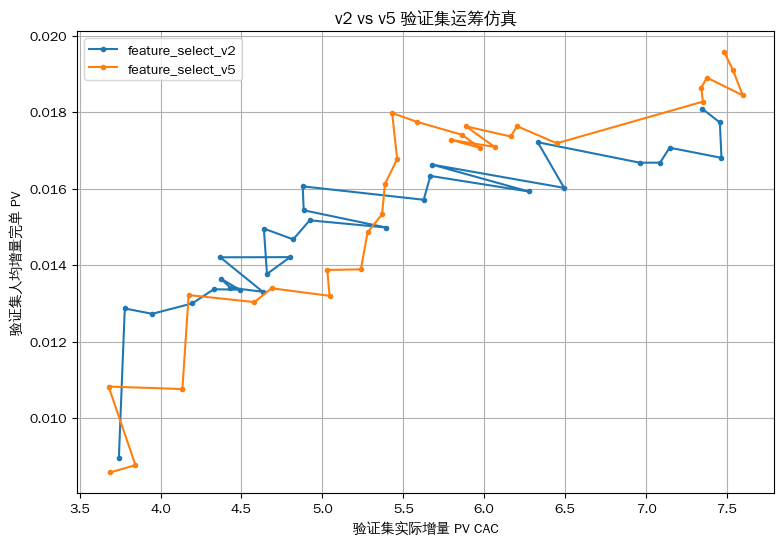

In [46]:
plt.figure(figsize=(9, 6))

for scheme_name in results.keys():
    plot_df = summary_df[
        (summary_df['scheme'] == scheme_name) &
        (summary_df['data_type'] == 'test')
   #  ].sort_values('实际增量cac')
      ].sort_values('约束cac')   # 按约束 cac 顺序连线

    plt.plot(
        plot_df['实际增量cac'],
        plot_df['实际增量cvr'],
        marker='.',
        label=scheme_name
    )

plt.xlabel('验证集实际增量 PV CAC')
plt.ylabel('验证集人均增量完单 PV')
plt.title('v2 vs v5 验证集运筹仿真')
plt.legend()
plt.grid(True)
plt.show()

In [29]:
# 多个stage参数

In [30]:
scheme_dfs = {
    'feature_select_v2': v2,
    'feature_select_v5': v5,
}

train_dates = ['2026-07-17'] * 7

val_dates = ['2026-07-18','2026-07-19','2026-07-20','2026-07-21', '2026-07-22','2026-07-23','2026-07-24']

# 1053 参与决策
opt_group_name_list = [
    'DS空白',
    '留存6张3元',
    '8元留存5张3',
    '10元留存5张3',
]

discount_para = {
    'DS空白': 0,
    '留存6张3元': 1,
    '8元留存5张3': 2,
    '10元留存5张3': 3,
}

cost_list = np.arange(3.5, 6.5, 0.1)

In [31]:

# 2. 自动从 stage 推导 columns / all_columns

def get_all_columns_from_stages(stages):
    all_cols = []
    for stage_cols, _ in stages:
        for col in stage_cols:
            if col not in all_cols:
                all_cols.append(col)
    return all_cols


def get_raw_columns_from_all_columns(all_columns):
    raw_cols = []
    for col in all_columns:
        if col.endswith('_per'):
            raw_cols.append(col[:-4])
        else:
            raw_cols.append(col)
    return raw_cols


def to_per_cols(raw_cols):
    return [f'{col}_per' for col in raw_cols]

In [32]:
stage_configs = {
    's1': [
        (['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 20000),
    ],

    
    's2': [
        (['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000),
        (['left1053_per', 'left853_per'], 15000),
        (['left63_per'], 15000),
    ],
    
    's3': [
        (['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 15000),
        (['left1053_minus_left63_per', 'left853_minus_left63_per'], 15000),
        (['left63_per'], 20000),
    ],

    's4': [
        (['coupon_prob_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per'], 10000),
        (['left1053_minus_left63_per', 'left63_per'], 10000),
        (['left1053_minus_left63_per', 'left853_per'], 10000),
        (['left63_per'], 20000),
    ],

    's5': [
        (['coupon_prob_per', 'left1053_per', 'left63_per'], 10000),
        (['left1053_per', 'left63_per'], 10000),
        (['left63_per'], 10000),
    ],

  
}

In [ ]:

# 3. 多套 stage 方案
# 只从你列出的字段中选：
# left853_minus_left63, left65_minus_left63, left65_minus_left853,
# left1053_minus_left63, left1053_minus_left853, left1053_minus_left65,
# cost_1, cost_2, cost_3, cost_4
'''

'''


========== running feature_select_v2 | s1 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['left853_per', 'left63_per'], 10000), (['left63_per'], 20000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,10282
7888,0.8,0.9,0.9,0.9,12983
7999,0.8,1.0,1.0,1.0,19256
8999,0.9,1.0,1.0,1.0,24053
9999,1.0,1.0,1.0,1.0,11056


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,36455
1,0.1,0.2,24557
10,0.2,0.1,29699
11,0.2,0.2,30876
12,0.2,0.3,14990
21,0.3,0.2,20739
22,0.3,0.3,34532
23,0.3,0.4,16566
32,0.4,0.3,22805
33,0.4,0.4,33613


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,7286
1,0.2,7762
2,0.3,11443
3,0.4,11719
4,0.5,8789
5,0.6,4952
6,0.7,1539
7,0.8,177
8,0.9,8350
9,1.0,8350


[16  5  3  6 14  1 31 17  2 29 15 23  4 12 22  7 13 26 11 28 30 21 19 20
 27 25 10  8  9 18 24  0]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1403        2.0        9.0      30.167   
1              0   8元留存5张3   1425        0.0        0.0       3.042   
2              0      DS空白   5579        3.0       28.0       0.000   
3              0    留存6张3元   1875        0.0        0.0       5.550   
4              1  10元留存5张3   1732       57.0      137.0     479.195   
..           ...       ...    ...        ...        ...         ...   
123           30    留存6张3元   4173       87.0      240.0     453.609   
124           31  10元留存5张3   9015      133.0      390.0    1204.270   
125           31   8元留存5张3   9135      117.0      306.0     953.043   
126           31      DS空白  38614      315.0     1147.0      20.021   
127           31    留存6张3元  13603      195.0      523.0     725.445   

     delta_cvr  delta_cac  
0    

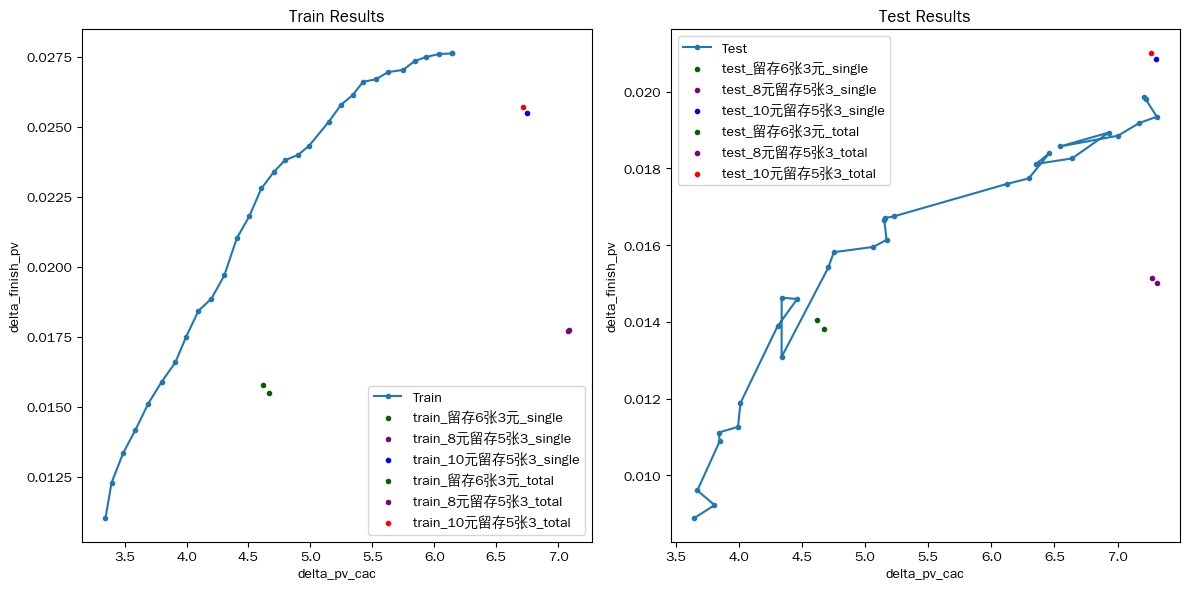


========== running feature_select_v2 | s2 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['left1053_per', 'left853_per'], 15000), (['left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '202

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,10282
7888,0.8,0.9,0.9,0.9,12983
7999,0.8,1.0,1.0,1.0,19256
8999,0.9,1.0,1.0,1.0,24053
9999,1.0,1.0,1.0,1.0,11056


['left1053_per', 'left853_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left853_per,counts
0,0.1,0.1,38066
1,0.1,0.2,28978
10,0.2,0.1,24366
11,0.2,0.2,32232
12,0.2,0.3,18432
22,0.3,0.3,34943
23,0.3,0.4,21107
32,0.4,0.3,19339
33,0.4,0.4,34014
34,0.4,0.5,17725


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
2,0.3,15479



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,9692
1,0.2,14973
3,0.4,14039
4,0.5,11249
5,0.6,8374
6,0.7,6212
7,0.8,2679
8,0.9,14017
9,1.0,11115


[14 31  3  6 13  1  7  5  2 28 16 22  4 17 20 11  8 23 10 26 18 29 21 27
 19 25 15 24 30 12  9  0]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1403        2.0        9.0      30.167   
1              0   8元留存5张3   1425        0.0        0.0       3.042   
2              0      DS空白   5579        3.0       28.0       0.000   
3              0    留存6张3元   1875        0.0        0.0       5.550   
4              1  10元留存5张3   1732       57.0      137.0     479.195   
..           ...       ...    ...        ...        ...         ...   
123           30    留存6张3元   3030       16.0       59.0      64.032   
124           31  10元留存5张3  11677      200.0      537.0    1663.778   
125           31   8元留存5张3  11899      195.0      551.0    1366.667   
126           31      DS空白  50713      513.0     1614.0       0.261   
127           31    留存6张3元  18061      258.0      693.0    1049.898   

     delta_cvr  delta_cac  
0    

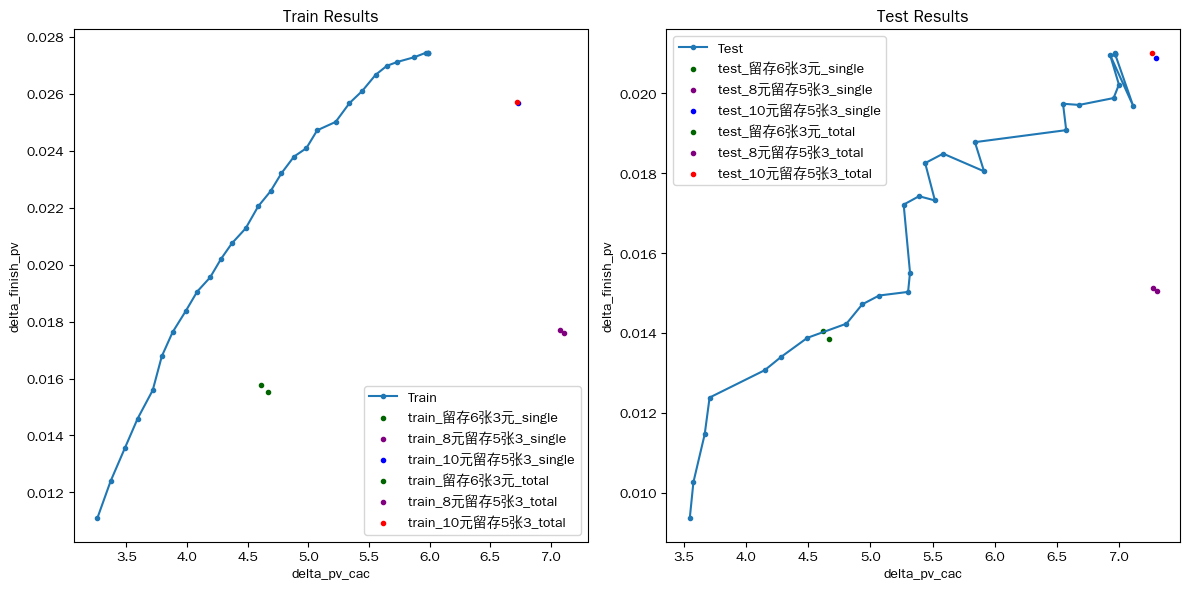


========== running feature_select_v2 | s3 ==========
columns: ['coupon_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000), (['left1053_minus_left63_per', 'left853_minus_left63_per'], 10000), (['left63_per'], 20000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']


,coupon_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
8999,0.9,1.0,1.0,1.0,13999


['left1053_minus_left63_per', 'left853_minus_left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left853_minus_left63_per,counts
0,0.1,0.1,20990
1,0.1,0.2,19323
2,0.1,0.3,11628
11,0.2,0.2,12303
12,0.2,0.3,17238
13,0.2,0.4,16103
22,0.3,0.3,12239
23,0.3,0.4,14933
24,0.3,0.5,14717
25,0.3,0.6,10613


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,31524
1,0.2,26091
2,0.3,27312
3,0.4,37382
4,0.5,45896
5,0.6,47891
6,0.7,46961
7,0.8,43840
8,0.9,37545
9,1.0,34363



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[13 34 42 33 37 41  2  3 32 24 21 39 18 22  6 36 14 40  5 16 11  4 12  8
 26 38 31  7 25 23 10 20  0  1 27 19 35 17 30 29 15 28  9]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1805      258.0      693.0    2387.337   
1              0   8元留存5张3   2018      250.0      690.0    1850.144   
2              0      DS空白   7146      507.0     1396.0      50.141   
3              0    留存6张3元   3030      377.0      936.0    1560.871   
4              1  10元留存5张3   2600       21.0       45.0     185.469   
..           ...       ...    ...        ...        ...         ...   
167           41    留存6张3元   7604      173.0      407.0     783.039   
168           42  10元留存5张3   4490      227.0      827.0    2634.806   
169           42   8元留存5张3   4530      219.0      764.0    2258.063   
170           42 

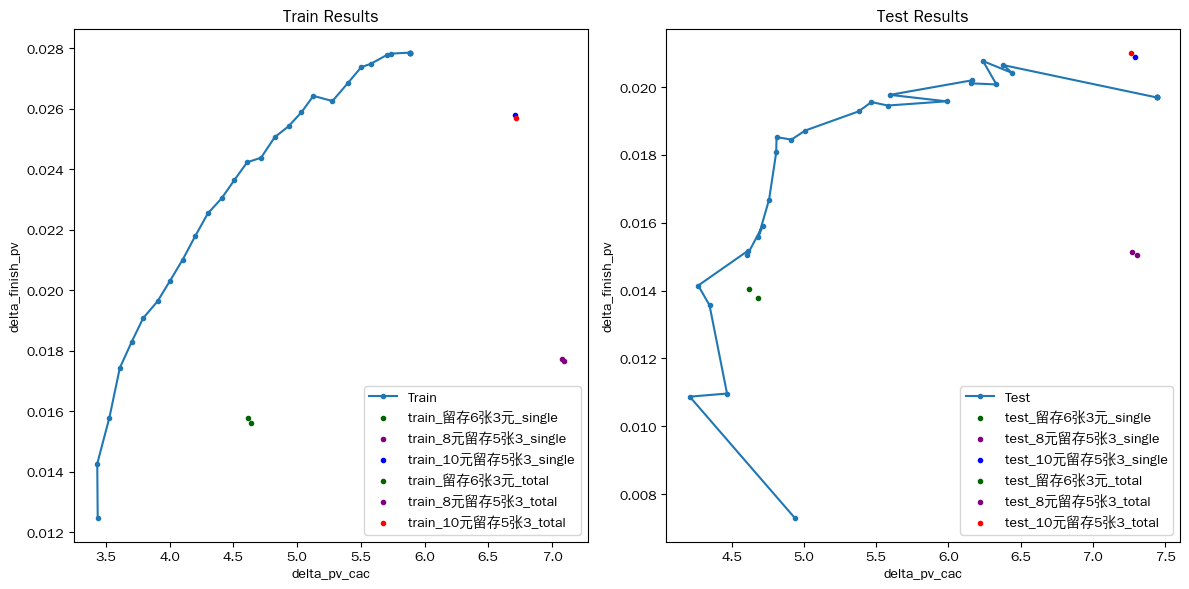


========== running feature_select_v2 | s4 ==========
columns: ['coupon_prob', 'left1053_minus_left63', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per'], 10000), (['left1053_minus_left63_per', 'left63_per'], 10000), (['left1053_minus_left63_per', 'left853_per'], 10000), (['left63_per'], 20000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17'

,coupon_prob_per,left1053_minus_left63_per,left853_per,left63_per,counts
7999,0.8,1.0,1.0,1.0,11035
8999,0.9,1.0,1.0,1.0,20819


['left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left63_per,counts
5,0.1,0.6,11031
6,0.1,0.7,15109
7,0.1,0.8,13132
10,0.2,0.1,21086
11,0.2,0.2,21713
12,0.2,0.3,10484
20,0.3,0.1,21698
21,0.3,0.2,17442
22,0.3,0.3,14297
30,0.4,0.1,16634


['left1053_minus_left63_per', 'left853_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
3,0.4,42799
4,0.5,42544
5,0.6,29026
6,0.7,27404
7,0.8,30949



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,9866
1,0.2,12832
2,0.3,9557
8,0.9,18149
9,1.0,17540


[41 45  1  5 34 39 15  0 31 40 43 38 19  3 16 21  6 14 44 17 29  9 11 12
 37 13 26 35  8 42 20 24 27 25 10 22 18 30 32 36 28  4  2 33 23  7]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1354       58.0      168.0     513.000   
1              0   8元留存5张3   1498       62.0      207.0     531.396   
2              0      DS空白   5978      129.0      420.0      55.000   
3              0    留存6张3元   2205      101.0      232.0     417.363   
4              1  10元留存5张3   2728      370.0     1070.0    3501.931   
..           ...       ...    ...        ...        ...         ...   
179           44    留存6张3元   6049       81.0      215.0     507.903   
180           45  10元留存5张3   8770      149.0      536.0    1549.791   
181           45   8元留存5张3   8755      114.0      382.0    1117.528   
182           45      DS空白  36862      262.0      887.0       0.000   
183           45    留存6张3元  13557      196.0      661.0     987

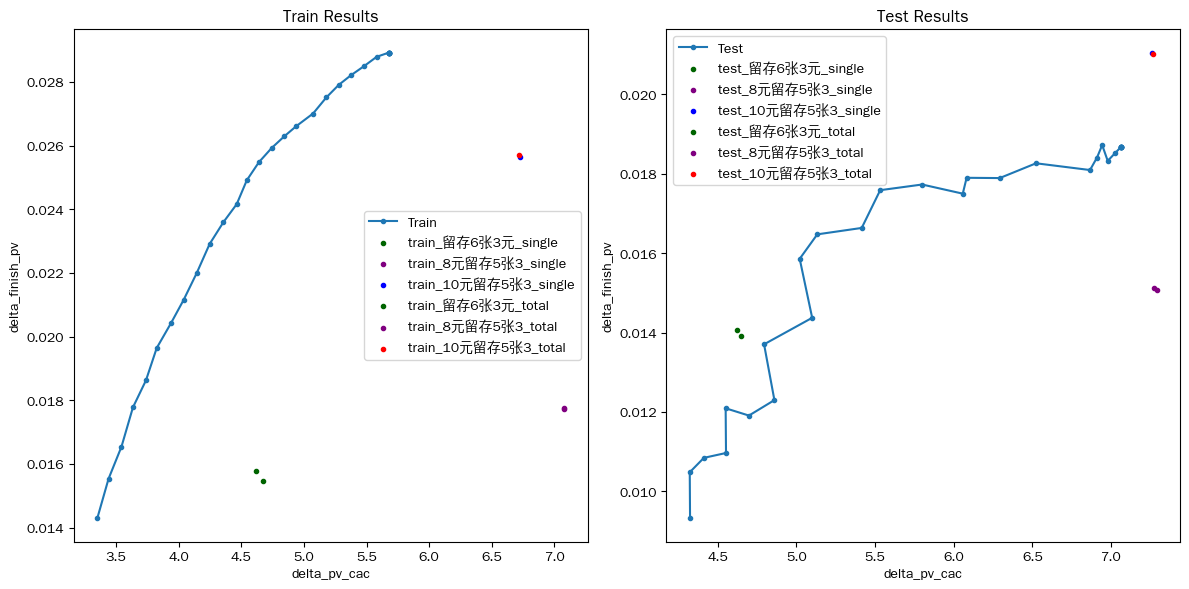


========== running feature_select_v2 | s5 ==========
columns: ['coupon_prob', 'left1053', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left63_per'], 10000), (['left1053_per', 'left63_per'], 10000), (['left63_per'], 10000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-23']
['2026-07-11', '2

,coupon_prob_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,16400
688,0.7,0.9,0.9,10597
788,0.8,0.9,0.9,16167
799,0.8,1.0,1.0,20192
899,0.9,1.0,1.0,24758
999,1.0,1.0,1.0,11495


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,34397
1,0.1,0.2,25418
10,0.2,0.1,25250
11,0.2,0.2,32426
12,0.2,0.3,18819
21,0.3,0.2,19795
22,0.3,0.3,34444
23,0.3,0.4,18250
32,0.4,0.3,20969
33,0.4,0.4,32803


['left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
3,0.4,14483



============================== Final Small Combinations ==============================
Small Combinations (<10000 samples):


,left63_per,counts
0,0.1,7675
1,0.2,6295
2,0.3,9538
4,0.5,8315
5,0.6,5537
6,0.7,6739
7,0.8,2776
8,0.9,207
9,1.0,2


[15 10  4 33  2  9  7  6  3  1 16 23  5 13 35 21 17  8 14 12 24 11 27 29
 31 26 34 32 30 18 20 22 25 28 19  0]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2141        3.0       10.0      43.887   
1              0   8元留存5张3   2223        0.0        0.0       5.673   
2              0      DS空白   8941        4.0       30.0       0.000   
3              0    留存6张3元   3095        0.0        0.0       9.333   
4              1  10元留存5张3   1357       22.0       67.0     283.292   
..           ...       ...    ...        ...        ...         ...   
139           34    留存6张3元   2712       11.0       30.0      67.143   
140           35  10元留存5张3   5962       49.0      194.0     401.214   
141           35   8元留存5张3   5989       45.0      150.0     286.983   
142           35      DS空白  25833      156.0      535.0       0.000   
143           35    留存6张3元   9300       80.0      289.0     300.663   

     delta_cvr  delta

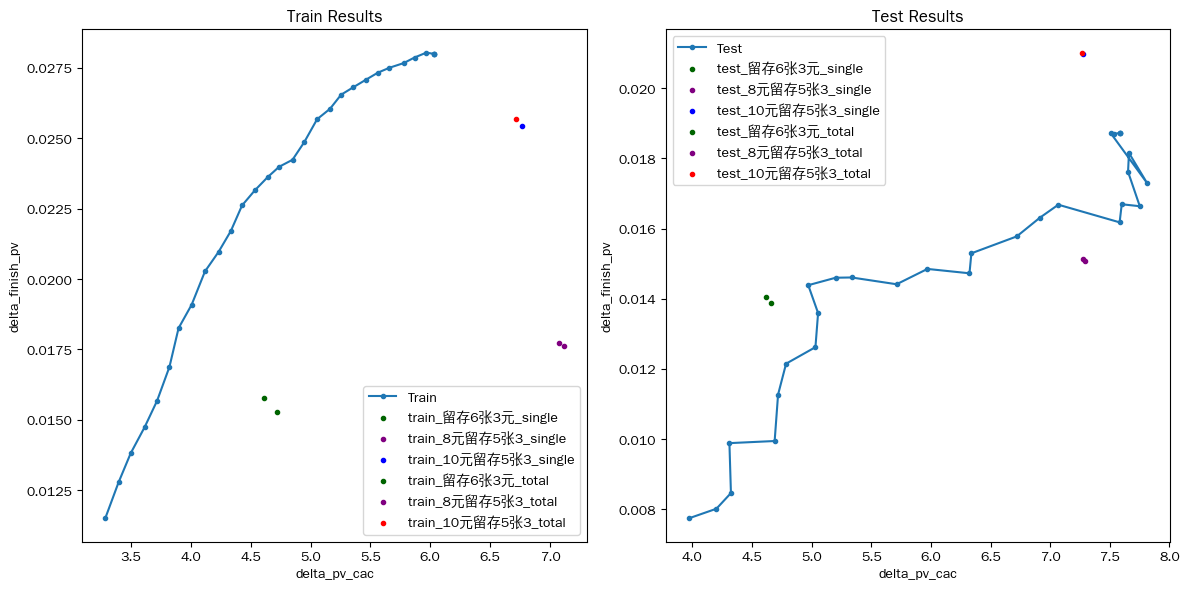


========== running feature_select_v5 | s1 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['left853_per', 'left63_per'], 10000), (['left63_per'], 20000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
7888,0.8,0.9,0.9,0.9,11244
7999,0.8,1.0,1.0,1.0,18398
8999,0.9,1.0,1.0,1.0,22922
9999,1.0,1.0,1.0,1.0,10387


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,48450
1,0.1,0.2,21838
2,0.1,0.3,10013
10,0.2,0.1,22261
11,0.2,0.2,33485
12,0.2,0.3,20930
21,0.3,0.2,21779
22,0.3,0.3,32810
23,0.3,0.4,16842
32,0.4,0.3,17628


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,13229
1,0.2,6578
2,0.3,2706
3,0.4,10996
4,0.5,4997
5,0.6,1909
6,0.7,762
7,0.8,401
8,0.9,276
9,1.0,49


[17  4  2  8 29  9 33  1 28 14 22 13 21 11 16 15 23 26 12 20 10  0 32 31
 19 30 18  7  5 25 27  6 24  3]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1482       49.0      104.0     425.001   
1              0   8元留存5张3   1455       37.0       79.0     321.804   
2              0      DS空白   6031       71.0      211.0       0.141   
3              0    留存6张3元   2276       56.0      154.0     313.728   
4              1  10元留存5张3   2329       98.0      293.0     958.558   
..           ...       ...    ...        ...        ...         ...   
131           32    留存6张3元   4049       98.0      288.0     497.265   
132           33  10元留存5张3   5321       25.0       65.0     201.372   
133           33   8元留存5张3   5216       27.0       98.0     175.406   
134           33      DS空白  23179      142.0      557.0      25.000   
135           33    留存6张3元   8187       45.0      159.0     187.638   

     delta_cvr  delta_cac  

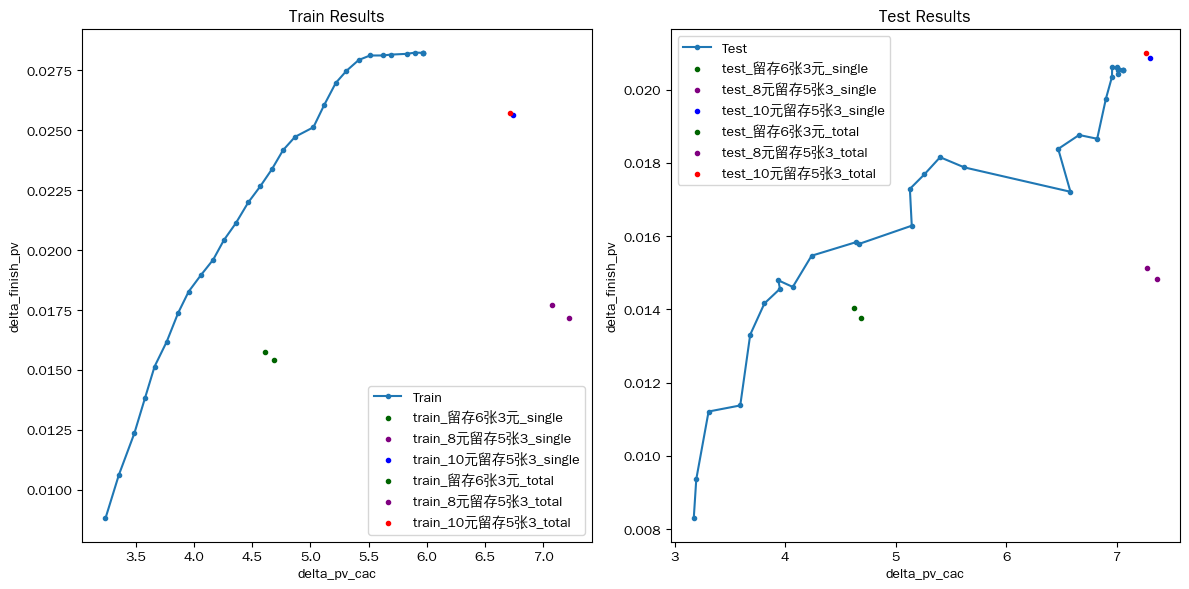


========== running feature_select_v5 | s2 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['left1053_per', 'left853_per'], 15000), (['left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '202

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
7888,0.8,0.9,0.9,0.9,11244
7999,0.8,1.0,1.0,1.0,18398
8999,0.9,1.0,1.0,1.0,22922
9999,1.0,1.0,1.0,1.0,10387


['left1053_per', 'left853_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left853_per,counts
0,0.1,0.1,45522
1,0.1,0.2,20608
10,0.2,0.1,25723
11,0.2,0.2,27909
12,0.2,0.3,18682
21,0.3,0.2,24568
22,0.3,0.3,28345
32,0.4,0.3,21580
33,0.4,0.4,29943
34,0.4,0.5,16008


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
1,0.2,16422
2,0.3,20953
3,0.4,19329
7,0.8,15176
8,0.9,16131



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,11308
4,0.5,13076
5,0.6,8654
6,0.7,13815
9,1.0,6490


[15  6  2  7  4 24  8  1 25 14 21 32 19  9 18 11 10 17 12 23 29 33 31  0
  5 27 26 22 20 16 13 28 30  3]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1482       49.0      104.0     425.001   
1              0   8元留存5张3   1455       37.0       79.0     321.804   
2              0      DS空白   6031       71.0      211.0       0.141   
3              0    留存6张3元   2276       56.0      154.0     313.728   
4              1  10元留存5张3   2329       98.0      293.0     958.558   
..           ...       ...    ...        ...        ...         ...   
131           32    留存6张3元   3312      119.0      277.0     330.540   
132           33  10元留存5张3   6881      117.0      396.0    1132.719   
133           33   8元留存5张3   6928       97.0      233.0     516.144   
134           33      DS空白  29146      329.0      958.0      45.564   
135           33    留存6张3元  10388      158.0      397.0     628.923   

     delta_cvr  delta_cac  

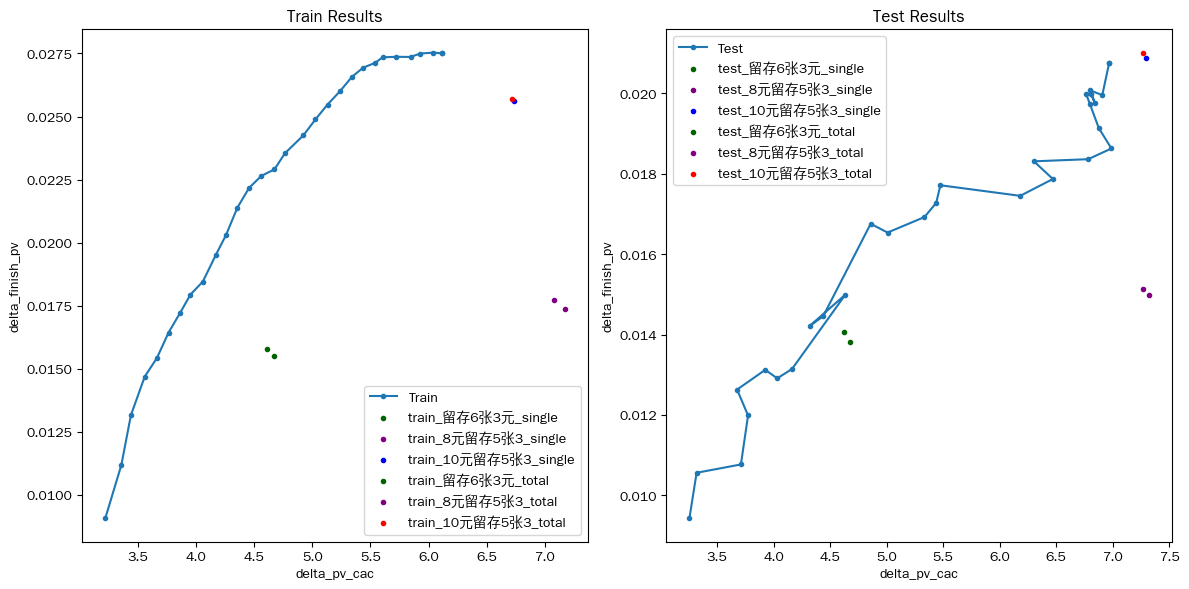


========== running feature_select_v5 | s3 ==========
columns: ['coupon_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63']
all_columns: ['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000), (['left1053_minus_left63_per', 'left853_minus_left63_per'], 10000), (['left63_per'], 20000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']


,coupon_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
8999,0.9,1.0,1.0,1.0,10070


['left1053_minus_left63_per', 'left853_minus_left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left853_minus_left63_per,counts
0,0.1,0.1,27011
10,0.2,0.1,16114
11,0.2,0.2,12774
21,0.3,0.2,13098
22,0.3,0.3,11242
25,0.3,0.6,10479
31,0.4,0.2,11924
32,0.4,0.3,13706
33,0.4,0.4,12517
34,0.4,0.5,11467


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
0,0.1,46994
1,0.2,22059
2,0.3,22563
3,0.4,32078
4,0.5,42245
5,0.6,43966
6,0.7,42377
7,0.8,41528
8,0.9,45736
9,1.0,46813



============================== Final Small Combinations ==============================

No Small Combinations in final stage
[37 15  0 34 33 40  5 32 41 36 39 35  1 18  2 17 14 27  4 10  3 23 16  8
 42 21  7 31 30 26 28 20 11 38 13 19 25  6 12 22 29  9 24]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1250      186.0      521.0    1673.709   
1              0   8元留存5张3   1401      186.0      516.0    1515.784   
2              0      DS空白   5284      346.0      914.0       0.000   
3              0    留存6张3元   2135      262.0      680.0    1256.826   
4              1  10元留存5张3   3346       35.0      115.0     319.669   
..           ...       ...    ...        ...        ...         ...   
167           41    留存6张3元   9199      216.0      580.0     980.313   
168           42  10元留存5张3   6306      348.0     1147.0    3833.286   
169           42   8元留存5张3   6404      329.0     1024.0    2974.798   
170           42 

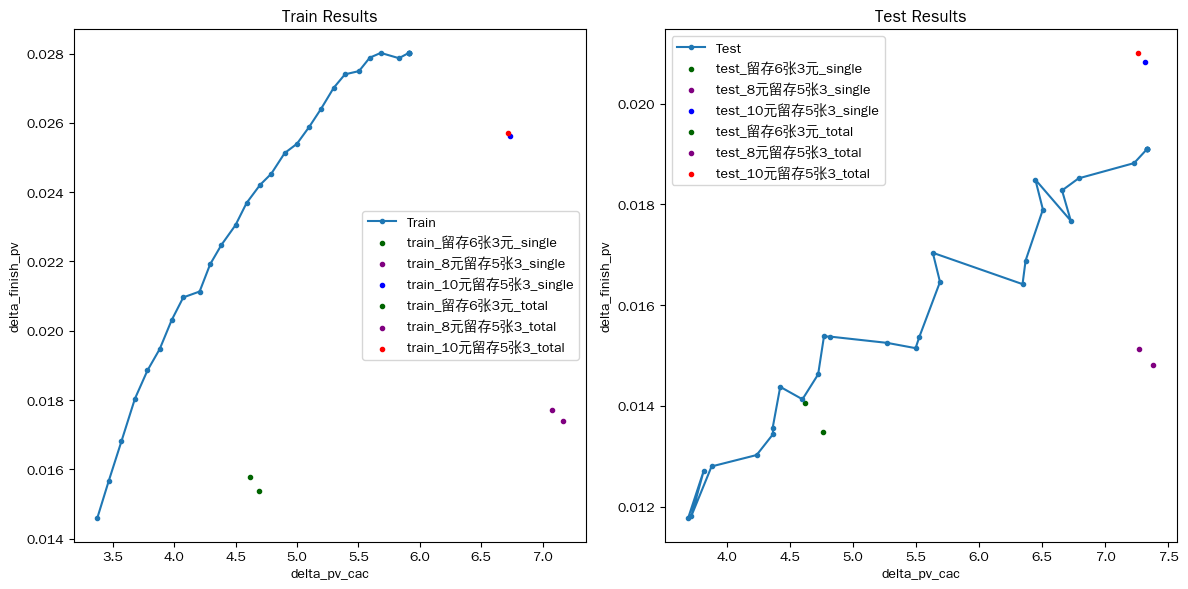


========== running feature_select_v5 | s4 ==========
columns: ['coupon_prob', 'left1053_minus_left63', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_minus_left63_per', 'left853_per', 'left63_per'], 10000), (['left1053_minus_left63_per', 'left63_per'], 10000), (['left1053_minus_left63_per', 'left853_per'], 10000), (['left63_per'], 20000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17'

,coupon_prob_per,left1053_minus_left63_per,left853_per,left63_per,counts
8999,0.9,1.0,1.0,1.0,15863


['left1053_minus_left63_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left63_per,counts
5,0.1,0.6,10412
6,0.1,0.7,13090
7,0.1,0.8,13469
8,0.1,0.9,12303
9,0.1,1.0,19300
10,0.2,0.1,15007
15,0.2,0.6,11818
20,0.3,0.1,18419
21,0.3,0.2,12371
22,0.3,0.3,11081


['left1053_minus_left63_per', 'left853_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage
['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
3,0.4,23929
4,0.5,59731
5,0.6,38700
6,0.7,44196
7,0.8,26178
8,0.9,30879
9,1.0,20237



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,12295
1,0.2,12120
2,0.3,13839


[41 15  0  9 19 43 10 39 44 25 42 38 47  2 20 24 40 22  3 31  4 46 23 16
  8 37 13  5  6 14 17 34 28 33 11 30  7 21 35 18 45 29 26 27  1 32 12 36]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2067      283.0      747.0    2536.533   
1              0   8元留存5张3   2240      282.0      770.0    2126.939   
2              0      DS空白   8202      527.0     1411.0      30.141   
3              0    留存6张3元   3354      396.0     1032.0    1829.374   
4              1  10元留存5张3   1292       12.0       47.0     105.618   
..           ...       ...    ...        ...        ...         ...   
187           46    留存6张3元   7358       61.0      170.0     389.124   
188           47  10元留存5张3   5004       24.0      110.0     249.168   
189           47   8元留存5张3   4742       27.0       86.0     107.532   
190           47      DS空白  21086      118.0      523.0       0.000   
191           47    留存6张3元   7422       34.0      142.0  

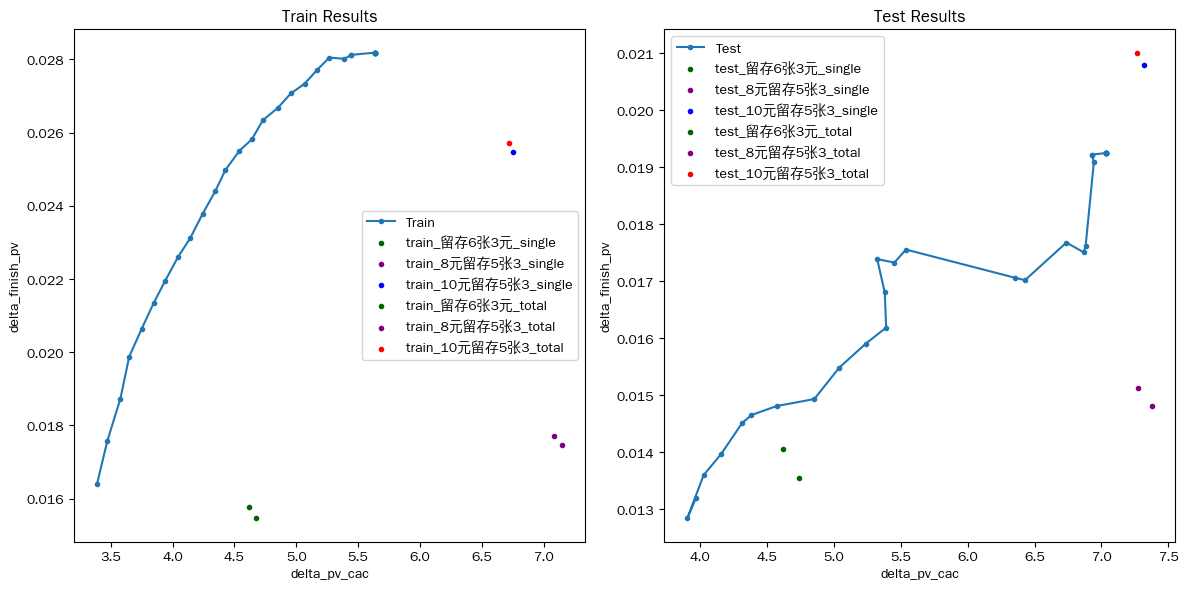


========== running feature_select_v5 | s5 ==========
columns: ['coupon_prob', 'left1053', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left63_per'], 10000), (['left1053_per', 'left63_per'], 10000), (['left63_per'], 10000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-23']
['2026-07-11', '2

,coupon_prob_per,left1053_per,left63_per,counts
0,0.1,0.1,0.1,15456
11,0.1,0.2,0.2,10665
100,0.2,0.1,0.1,10521
688,0.7,0.9,0.9,10729
788,0.8,0.9,0.9,15145
799,0.8,1.0,1.0,20561
899,0.9,1.0,1.0,24768
999,1.0,1.0,1.0,11410


['left1053_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left63_per,counts
0,0.1,0.1,33400
1,0.1,0.2,13354
10,0.2,0.1,19440
11,0.2,0.2,24215
12,0.2,0.3,18932
21,0.3,0.2,26214
22,0.3,0.3,32578
23,0.3,0.4,14729
32,0.4,0.3,22901
33,0.4,0.4,31322


['left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
3,0.4,14316
4,0.5,12596



============================== Final Small Combinations ==============================
Small Combinations (<10000 samples):


,left63_per,counts
0,0.1,5123
1,0.2,9232
2,0.3,9676
5,0.6,9402
6,0.7,5986
7,0.8,3555
8,0.9,2379
9,1.0,1034


[18  9  6 34 35 27 10  1  5  3 17 24 32 38 22 11 14 37 36 16 13 28 21 30
  2 29  4  8 33 19 20 15 12 26 25  0 23 31  7]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   2027        2.0        6.0      31.145   
1              0   8元留存5张3   2016        1.0        2.0      12.378   
2              0      DS空白   8440        6.0       26.0       0.000   
3              0    留存6张3元   2973        1.0        1.0      10.686   
4              1  10元留存5张3   1327        2.0        7.0      14.079   
..           ...       ...    ...        ...        ...         ...   
151           37    留存6张3元   2324       16.0       36.0      62.241   
152           38  10元留存5张3   5924       41.0      170.0     385.062   
153           38   8元留存5张3   5779       47.0      173.0     334.007   
154           38      DS空白  25582      172.0      734.0       0.000   
155           38    留存6张3元   9102       73.0      224.0     253.485   

     delta_c

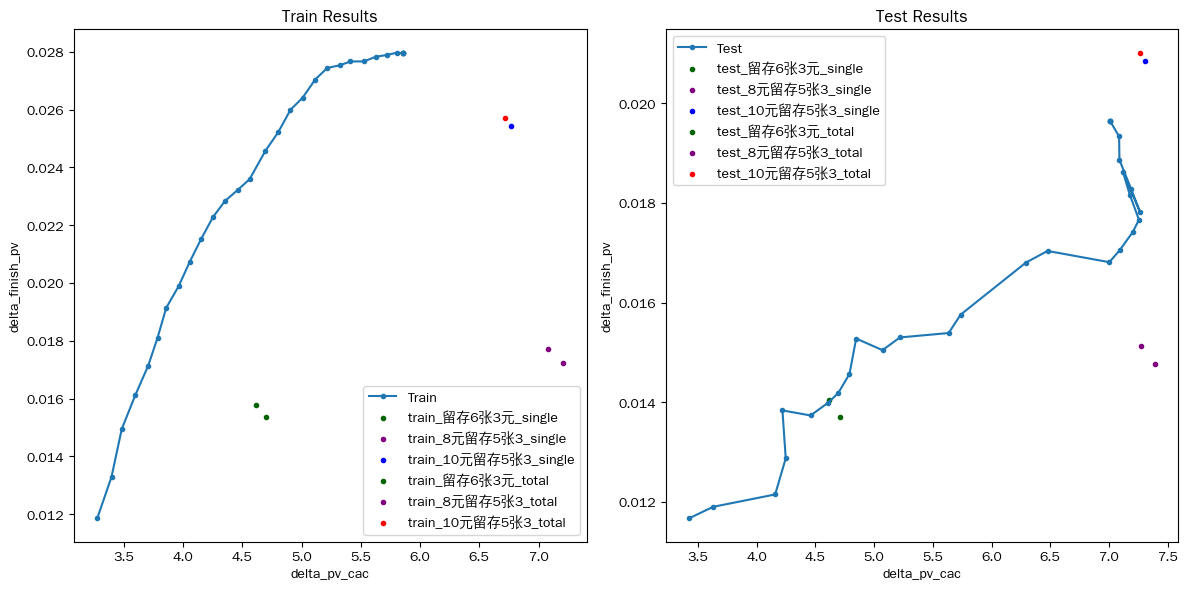

In [33]:

# 4. 多方案 × 多stage 运行
# 注意：main_try(show_tongbu=True) 会每次自动画 Train/Test 图
# 如果你跑 3 * 8 = 24 次，会输出很多图


stage_results = {}

for scheme_name, data_df in scheme_dfs.items():
    for stage_name, stages in stage_configs.items():
        print(f'\n========== running {scheme_name} | {stage_name} ==========')

        all_columns = get_all_columns_from_stages(stages)
        columns = get_raw_columns_from_all_columns(all_columns)

        print('columns:', columns)
        print('all_columns:', all_columns)
        print('stages:', stages)

        quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
            data_df.copy(),
            opt_group_name_list,
            columns,
            train_dates,
            val_dates
        )

        outputs = main_try(
            train_bucketing.copy(),
            val_bucketing.copy(),
            opt_group_name_list,
            control_name='DS空白',
            cost_list=cost_list,
            all_columns=all_columns,
            stages=stages,
            discount_para=discount_para,
            method=0,
            read_directly=False,
            show_tongbu=True,
            combinations=False,
            simulation_flag=True,
        )

        stage_results[(scheme_name, stage_name)] = {
            'scheme': scheme_name,
            'stage_name': stage_name,
            'columns': columns,
            'all_columns': all_columns,
            'stages': stages,
            'quantile_thresholds': quantile_thresholds,
            'train_df': outputs[0],
            'val_df': outputs[1],
            'bucket_mapping': outputs[2],
            'reverse_mapping': outputs[3],
            'processed_data': outputs[4],
            'next_processed_data': outputs[5],
            'discount_res_list': outputs[6],
            'discount_res_test_list': outputs[7],
            'train_list': outputs[8],
            'test_list': outputs[9],
            'tongbu_list': outputs[10],
            'tongbu_all_list': outputs[11],
        }

In [34]:

# 5. 汇总 train/test 仿真结果


def build_stage_result_df(result_list, scheme_name, stage_name, data_type):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr',
            '实际增量首单cvr',
            '留存频次',
        ]
    )
    df['scheme'] = scheme_name
    df['stage_name'] = stage_name
    df['data_type'] = data_type
    return df


summary_list = []

for (scheme_name, stage_name), res in stage_results.items():
    summary_list.append(build_stage_result_df(res['train_list'], scheme_name, stage_name, 'train'))
    summary_list.append(build_stage_result_df(res['test_list'], scheme_name, stage_name, 'test'))

stage_summary_df = pd.concat(summary_list, ignore_index=True)

stage_summary_df[
    ['scheme', 'stage_name', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,feature_select_v2,s1,train,3.5,3.345437,0.011013,0.003970,2.774122
1,feature_select_v2,s1,train,3.6,3.394589,0.012283,0.004435,2.769328
2,feature_select_v2,s1,train,3.7,3.488666,0.013351,0.004770,2.798752
3,feature_select_v2,s1,train,3.8,3.587985,0.014176,0.005157,2.748917
4,feature_select_v2,s1,train,3.9,3.690976,0.015114,0.005490,2.752824
...,...,...,...,...,...,...,...,...
595,feature_select_v5,s5,test,6.0,7.086597,0.019333,0.007078,2.731373
596,feature_select_v5,s5,test,6.1,7.007216,0.019651,0.007198,2.730048
597,feature_select_v5,s5,test,6.2,7.007216,0.019651,0.007198,2.730048
598,feature_select_v5,s5,test,6.3,7.007216,0.019651,0.007198,2.730048


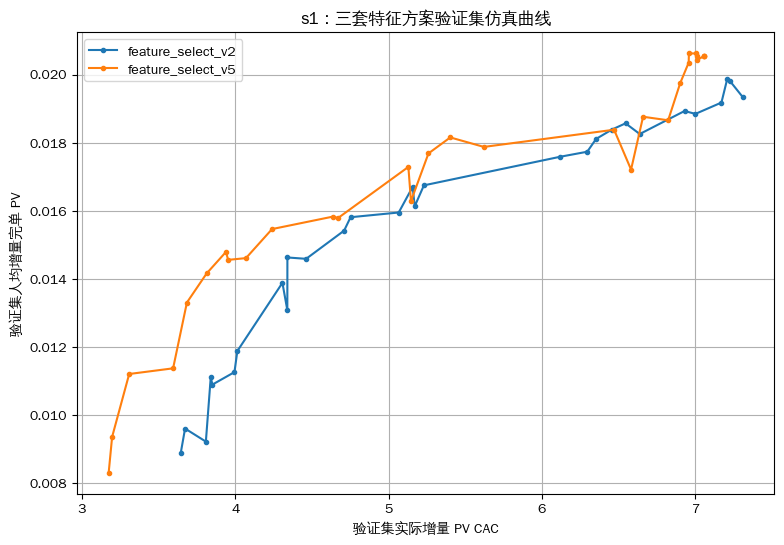

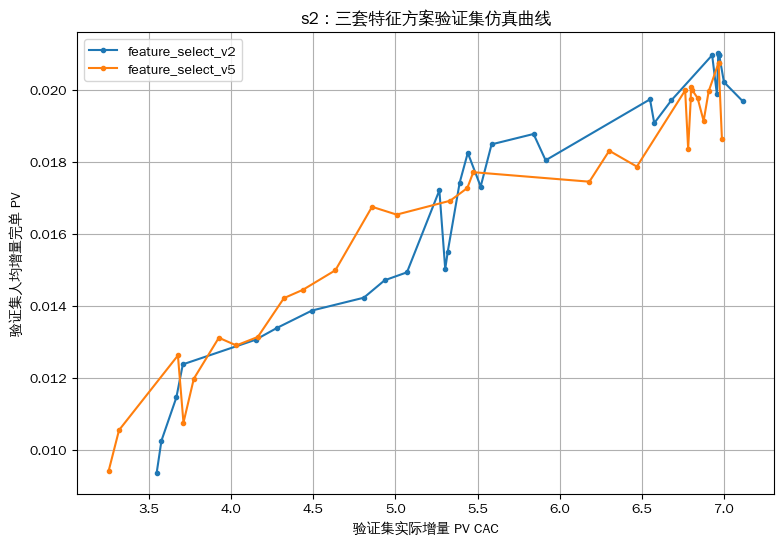

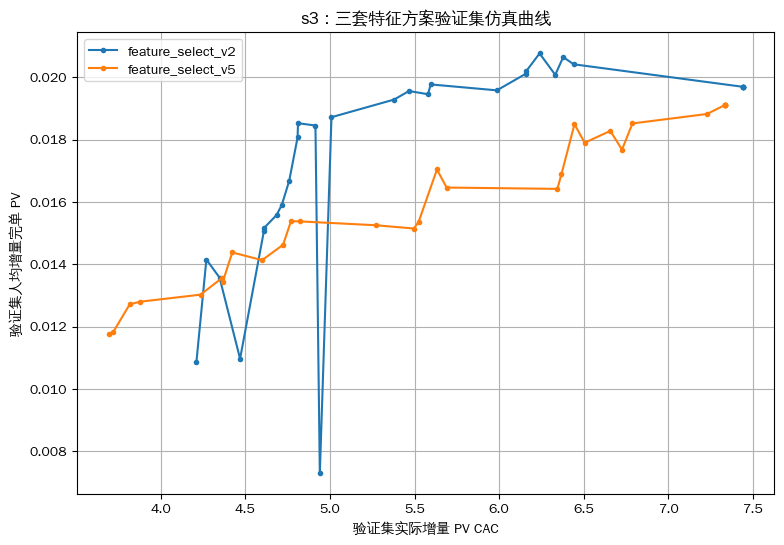

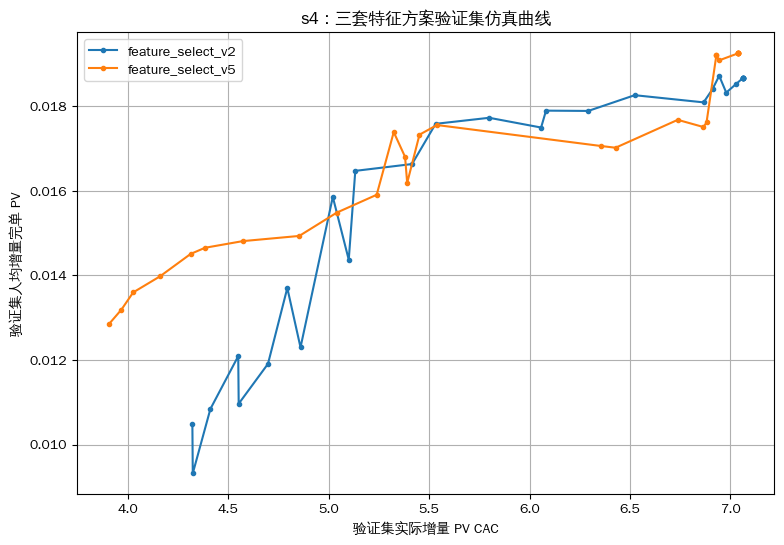

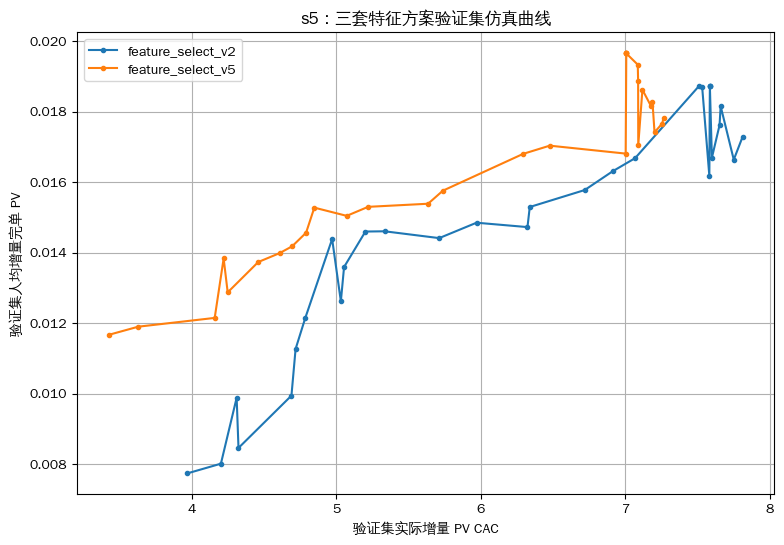

In [35]:

# 6. 一个图对应一个 stage，图里放三个特征方案


for stage_name in stage_configs.keys():
    plt.figure(figsize=(9, 6))

    for scheme_name in scheme_dfs.keys():
        plot_df = stage_summary_df[
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['data_type'] == 'test')
       #  ].sort_values('约束cac')
        ].sort_values('实际增量cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=scheme_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{stage_name}：三套特征方案验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

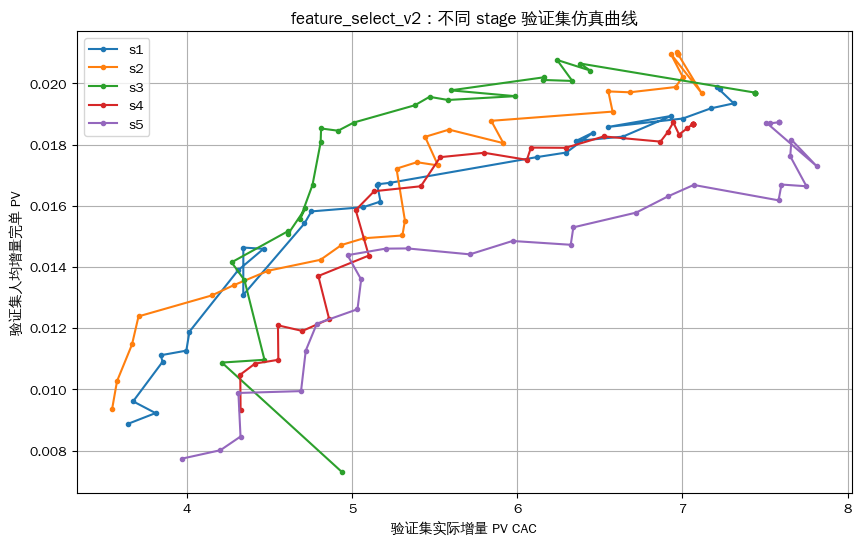

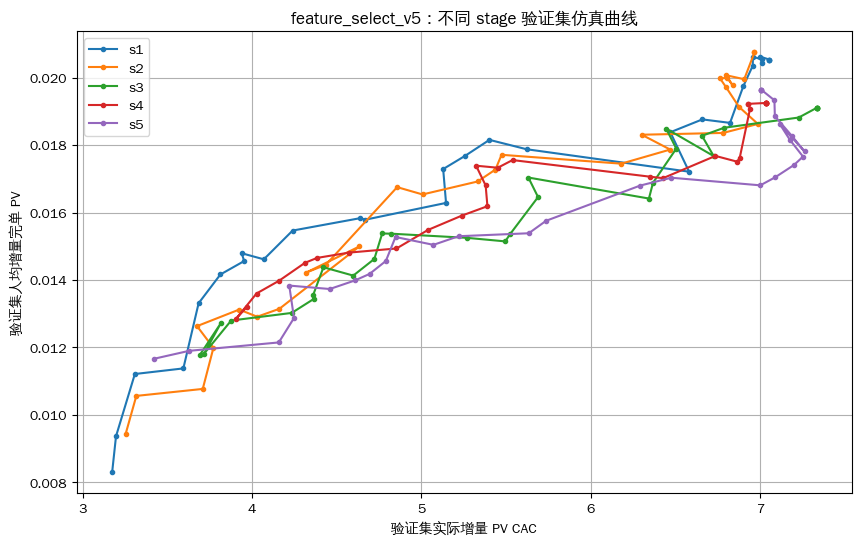

In [36]:

#7. 一个图对应一个方案，图里放不同 stage
for scheme_name in scheme_dfs.keys():
    plt.figure(figsize=(10, 6))

    for stage_name in stage_configs.keys():
        plot_df = stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['data_type'] == 'test')
        ].sort_values('约束cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=stage_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{scheme_name}：不同 stage 验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

In [100]:
stage_configs = {
    's1': [
        (['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 15000),
    ],
    
    's2': [
        (['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000),
        (['coupon_prob_per', 'left853_per','left63_per'], 10000),
        (['left65_per', 'left853_per', 'left63_per'], 10000),
        (['left63_per'], 15000),
    ],

    
    's3': [
        (['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000),
        (['left1053_per', 'left853_per'], 15000),
        (['left63_per'], 20000),
    ],
    
    's4': [
        (['coupon_prob_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['left1053_minus_left63_per', 'left63_per'], 15000),
        (['left853_minus_left63_per','left63_per'], 15000),
    ],

    's5': [
        (['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000),
        (['left853_per', 'left63_per'], 10000),
        (['left63_per'], 15000),
    ],
    
  
}


========== running feature_select_v2 | s1 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['left853_per', 'left63_per'], 10000), (['left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,10282
7888,0.8,0.9,0.9,0.9,12983
7999,0.8,1.0,1.0,1.0,19256
8999,0.9,1.0,1.0,1.0,24053
9999,1.0,1.0,1.0,1.0,11056


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,36455
1,0.1,0.2,24557
10,0.2,0.1,29699
11,0.2,0.2,30876
12,0.2,0.3,14990
21,0.3,0.2,20739
22,0.3,0.3,34532
23,0.3,0.4,16566
32,0.4,0.3,22805
33,0.4,0.4,33613


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,7286
1,0.2,7762
2,0.3,11443
3,0.4,11719
4,0.5,8789
5,0.6,4952
6,0.7,1539
7,0.8,177
8,0.9,8350
9,1.0,8350


[16  5  3  6 14  1 31 17  2 29 15 23  4 12 22  7 13 26 11 28 30 21 19 20
 27 25 10  8  9 18 24  0]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1403        2.0        9.0      30.167   
1              0   8元留存5张3   1425        0.0        0.0       3.042   
2              0      DS空白   5579        3.0       28.0       0.000   
3              0    留存6张3元   1875        0.0        0.0       5.550   
4              1  10元留存5张3   1732       57.0      137.0     479.195   
..           ...       ...    ...        ...        ...         ...   
123           30    留存6张3元   4173       87.0      240.0     453.609   
124           31  10元留存5张3   9015      133.0      390.0    1204.270   
125           31   8元留存5张3   9135      117.0      306.0     953.043   
126           31      DS空白  38614      315.0     1147.0      20.021   
127           31    留存6张3元  13603      195.0      523.0     725.445   

     delta_cvr  delta_cac  
0    

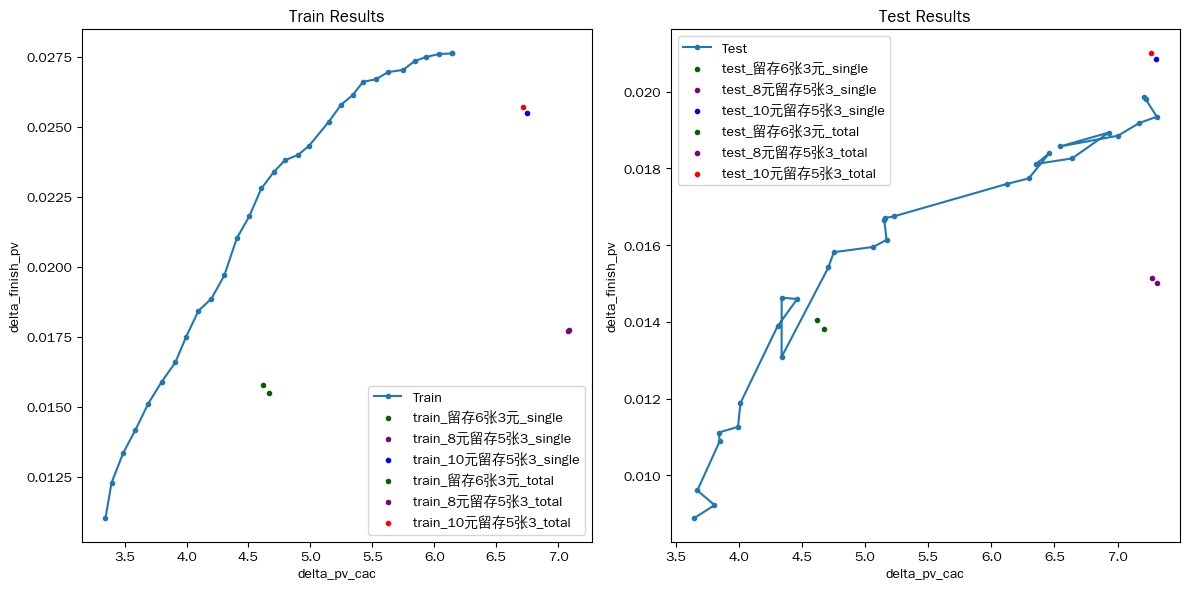


========== running feature_select_v2 | s2 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63', 'left65']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per', 'left65_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['coupon_prob_per', 'left853_per', 'left63_per'], 10000), (['left65_per', 'left853_per', 'left63_per'], 10000), (['left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,10282
7888,0.8,0.9,0.9,0.9,12983
7999,0.8,1.0,1.0,1.0,19256
8999,0.9,1.0,1.0,1.0,24053
9999,1.0,1.0,1.0,1.0,11056


['coupon_prob_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,coupon_prob_per,left853_per,left63_per,counts
466,0.5,0.7,0.7,11305
677,0.7,0.8,0.8,10450
688,0.7,0.9,0.9,12001
777,0.8,0.8,0.8,11850


['left65_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,17444
1,0.2,58109
2,0.3,67025
3,0.4,69108
4,0.5,53710
5,0.6,58874
6,0.7,44777
7,0.8,34726
8,0.9,28613



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
9,1.0,12019


[17  9  3 11 27  1 24 16  2  7 25 20  4 29 23 12 14 30 21  5 15 22 28 31
 19 26  8  6 32 13 18 10  0]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1403        2.0        9.0      30.167   
1              0   8元留存5张3   1425        0.0        0.0       3.042   
2              0      DS空白   5579        3.0       28.0       0.000   
3              0    留存6张3元   1875        0.0        0.0       5.550   
4              1  10元留存5张3   1732       57.0      137.0     479.195   
..           ...       ...    ...        ...        ...         ...   
127           31    留存6张3元   5756      181.0      406.0     684.996   
128           32  10元留存5张3   1565       51.0      143.0     511.413   
129           32   8元留存5张3   1531       44.0      111.0     405.391   
130           32      DS空白   6525       81.0      219.0       0.000   
131           32    留存6张3元   2398       52.0      149.0     305.139   

     delta_cvr  delta_cac  
0 

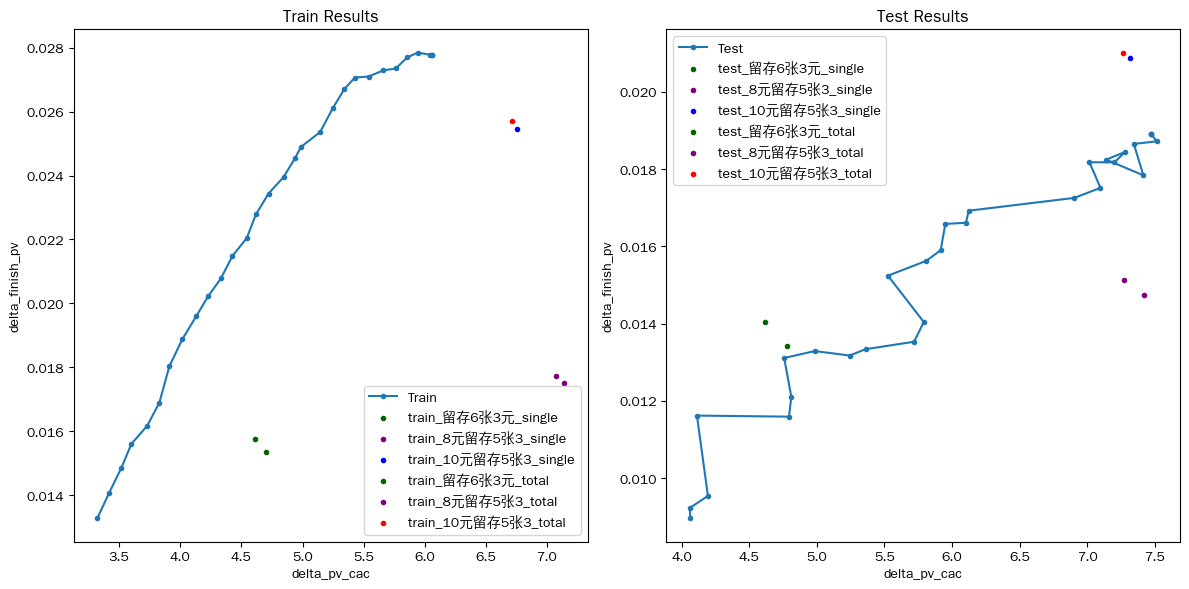


========== running feature_select_v2 | s3 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['left1053_per', 'left853_per'], 15000), (['left63_per'], 20000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '202

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,0.1,10282
7888,0.8,0.9,0.9,0.9,12983
7999,0.8,1.0,1.0,1.0,19256
8999,0.9,1.0,1.0,1.0,24053
9999,1.0,1.0,1.0,1.0,11056


['left1053_per', 'left853_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left853_per,counts
0,0.1,0.1,38066
1,0.1,0.2,28978
10,0.2,0.1,24366
11,0.2,0.2,32232
12,0.2,0.3,18432
22,0.3,0.3,34943
23,0.3,0.4,21107
32,0.4,0.3,19339
33,0.4,0.4,34014
34,0.4,0.5,17725


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,9692
1,0.2,14973
2,0.3,15479
3,0.4,14039
4,0.5,11249
5,0.6,8374
6,0.7,6212
7,0.8,2679
8,0.9,14017
9,1.0,11115


[14 30  3  6 13  1  7  5  2 28 16 22  4 17 20 11  8 23 10 26 18 29 21 27
 19 25 15 24 12  9  0]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1403        2.0        9.0      30.167   
1              0   8元留存5张3   1425        0.0        0.0       3.042   
2              0      DS空白   5579        3.0       28.0       0.000   
3              0    留存6张3元   1875        0.0        0.0       5.550   
4              1  10元留存5张3   1732       57.0      137.0     479.195   
..           ...       ...    ...        ...        ...         ...   
119           29    留存6张3元   3224       96.0      221.0     338.130   
120           30  10元留存5张3  13559      213.0      600.0    1816.582   
121           30   8元留存5张3  13914      203.0      570.0    1405.139   
122           30      DS空白  59265      545.0     1716.0       0.261   
123           30    留存6张3元  21091      274.0      752.0    1113.930   

     delta_cvr  delta_cac  
0     0.

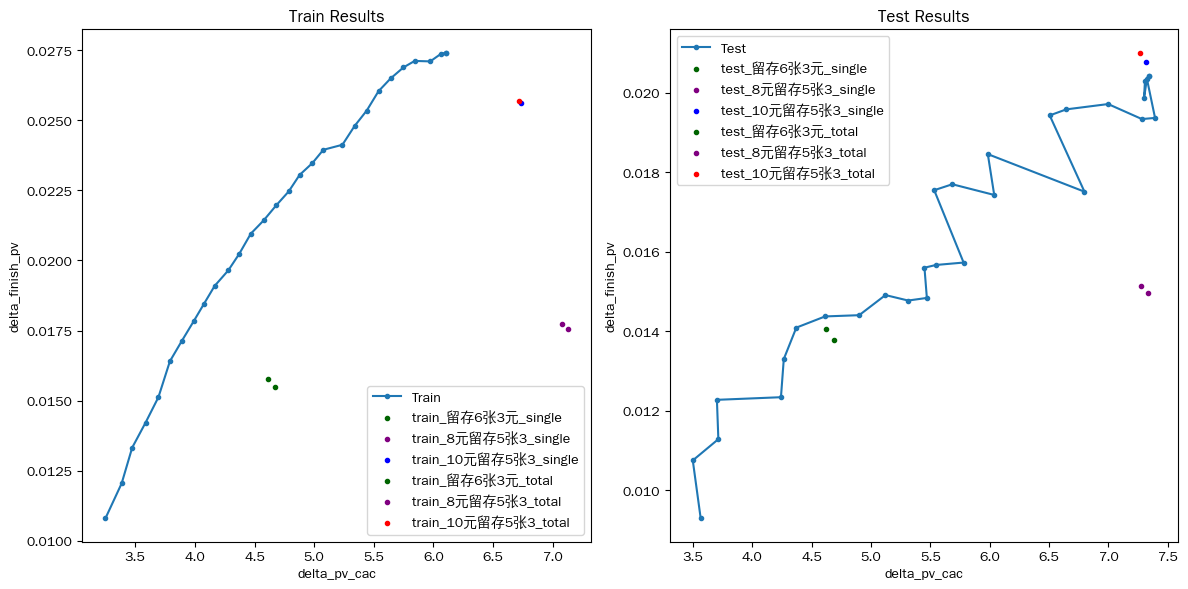


========== running feature_select_v2 | s4 ==========
columns: ['coupon_prob', 'left1053_minus_left853', 'left853_minus_left63', 'left63', 'left1053_minus_left63']
all_columns: ['coupon_prob_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per', 'left1053_minus_left63_per']
stages: [(['coupon_prob_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per'], 10000), (['left1053_minus_left63_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12',

,coupon_prob_per,left1053_minus_left853_per,left853_minus_left63_per,left63_per,counts
8999,0.9,1.0,1.0,1.0,13077


['left1053_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_minus_left63_per,left63_per,counts
6,0.1,0.7,15109
10,0.2,0.1,21086
11,0.2,0.2,21713
20,0.3,0.1,21698
21,0.3,0.2,17442
30,0.4,0.1,16634
32,0.4,0.3,17451
42,0.5,0.3,17001
64,0.7,0.5,15569
65,0.7,0.6,17351


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,119
1,0.1,0.2,706
2,0.1,0.3,2960
3,0.1,0.4,6275
4,0.1,0.5,9333
...,...,...,...
95,1.0,0.6,1561
96,1.0,0.7,3599
97,1.0,0.8,12530
98,1.0,0.9,10458


[17 16  2 14  1  3  8  5  6 15  7 13  4  9  0 11 12 10]
rct_pred_data:     bucket_name  exp_name   in_uv  finish_uv  finish_pv  total_cost  \
0             0  10元留存5张3    1677      243.0      636.0    2227.939   
1             0   8元留存5张3    1892      236.0      659.0    1741.667   
2             0      DS空白    6642      476.0     1320.0      50.141   
3             0    留存6张3元    2866      356.0      893.0    1509.853   
4             1  10元留存5张3    1894       19.0       50.0     211.410   
..          ...       ...     ...        ...        ...         ...   
67           16    留存6张3元    6423      462.0     1334.0    2177.244   
68           17  10元留存5张3   66382      726.0     2280.0    7784.512   
69           17   8元留存5张3   66451      582.0     1700.0    5110.641   
70           17      DS空白  284514     1475.0     5047.0     107.346   
71           17    留存6张3元   99890      914.0     2603.0    5008.301   

    delta_cvr  delta_cac  
0    0.180513   7.359714  
1    0.149573   6.1544

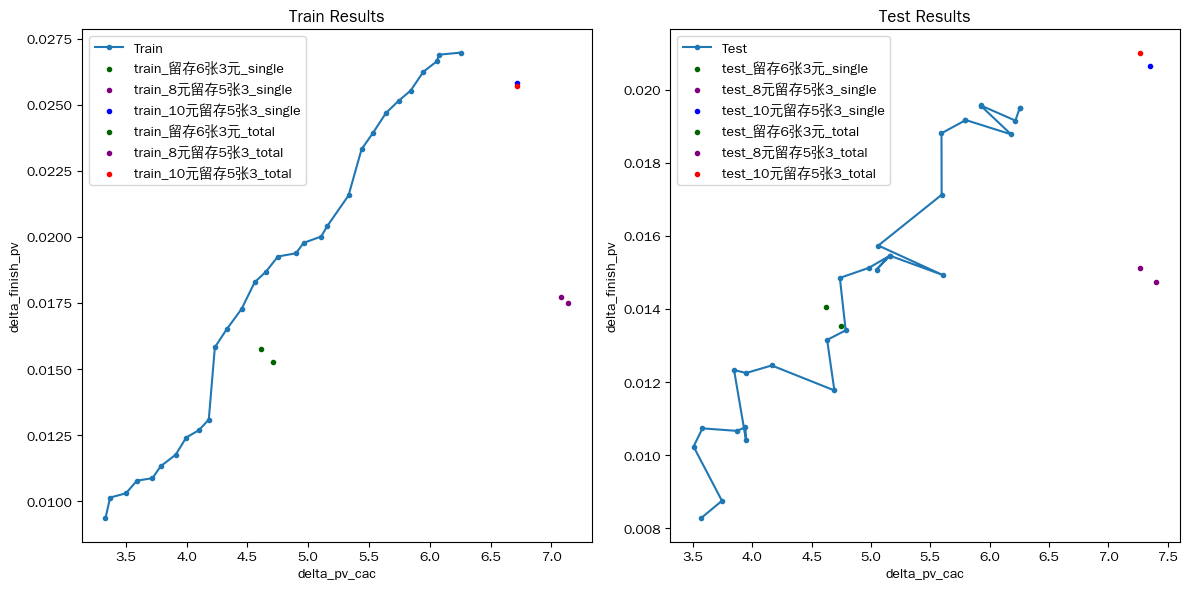


========== running feature_select_v2 | s5 ==========
columns: ['coupon_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'left853']
all_columns: ['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'left853_per']
stages: [(['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000), (['left853_per', 'left63_per'], 10000), (['left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['

,coupon_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
8999,0.9,1.0,1.0,1.0,13999


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,46737
1,0.1,0.2,24557
10,0.2,0.1,29699
11,0.2,0.2,30876
12,0.2,0.3,14990
21,0.3,0.2,20739
22,0.3,0.3,34532
23,0.3,0.4,16566
32,0.4,0.3,22805
33,0.4,0.4,33613


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,7286
1,0.2,7762
2,0.3,11443
3,0.4,11719
4,0.5,8789
5,0.6,4952
6,0.7,1539
7,0.8,177
8,0.9,8350
9,1.0,8350


[15  2 25 17  4 24 27  1 20  8 19  7 12 14 10  3 26 22  5  6 11 23 16  0
 13 18 21  9]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1805      258.0      693.0    2387.337   
1              0   8元留存5张3   2018      250.0      690.0    1850.144   
2              0      DS空白   7146      507.0     1396.0      50.141   
3              0    留存6张3元   3030      377.0      936.0    1560.871   
4              1  10元留存5张3   6225       11.0       62.0     131.690   
..           ...       ...    ...        ...        ...         ...   
107           26    留存6张3元   2393       67.0      147.0     292.950   
108           27  10元留存5张3   9015      133.0      390.0    1204.270   
109           27   8元留存5张3   9135      117.0      306.0     953.043   
110           27      DS空白  38614      315.0     1147.0      20.021   
111           27    留存6张3元  13603      195.0      523.0     725.445   

     delta_cvr  delta_cac  
0     0.188579   

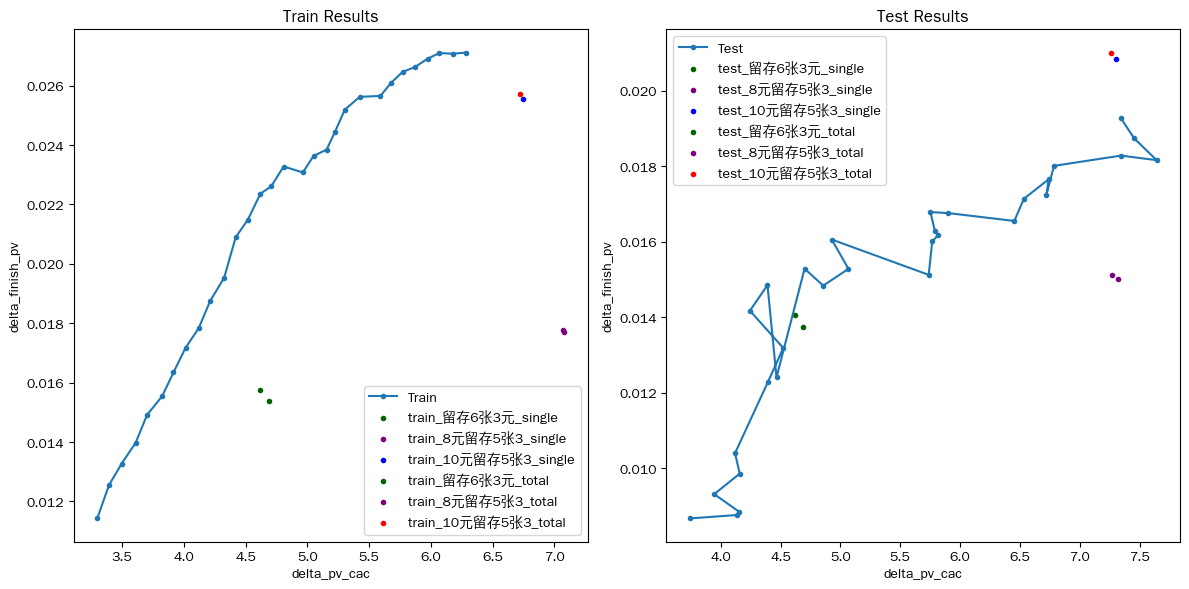


========== running feature_select_v5 | s1 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['left853_per', 'left63_per'], 10000), (['left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
7888,0.8,0.9,0.9,0.9,11244
7999,0.8,1.0,1.0,1.0,18398
8999,0.9,1.0,1.0,1.0,22922
9999,1.0,1.0,1.0,1.0,10387


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,48450
1,0.1,0.2,21838
2,0.1,0.3,10013
10,0.2,0.1,22261
11,0.2,0.2,33485
12,0.2,0.3,20930
21,0.3,0.2,21779
22,0.3,0.3,32810
23,0.3,0.4,16842
32,0.4,0.3,17628


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,13229
1,0.2,6578
2,0.3,2706
3,0.4,10996
4,0.5,4997
5,0.6,1909
6,0.7,762
7,0.8,401
8,0.9,276
9,1.0,49


[17  4  2  8 29  9 33  1 28 14 22 13 21 11 16 15 23 26 12 20 10  0 32 31
 19 30 18  7  5 25 27  6 24  3]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1482       49.0      104.0     425.001   
1              0   8元留存5张3   1455       37.0       79.0     321.804   
2              0      DS空白   6031       71.0      211.0       0.141   
3              0    留存6张3元   2276       56.0      154.0     313.728   
4              1  10元留存5张3   2329       98.0      293.0     958.558   
..           ...       ...    ...        ...        ...         ...   
131           32    留存6张3元   4049       98.0      288.0     497.265   
132           33  10元留存5张3   5321       25.0       65.0     201.372   
133           33   8元留存5张3   5216       27.0       98.0     175.406   
134           33      DS空白  23179      142.0      557.0      25.000   
135           33    留存6张3元   8187       45.0      159.0     187.638   

     delta_cvr  delta_cac  

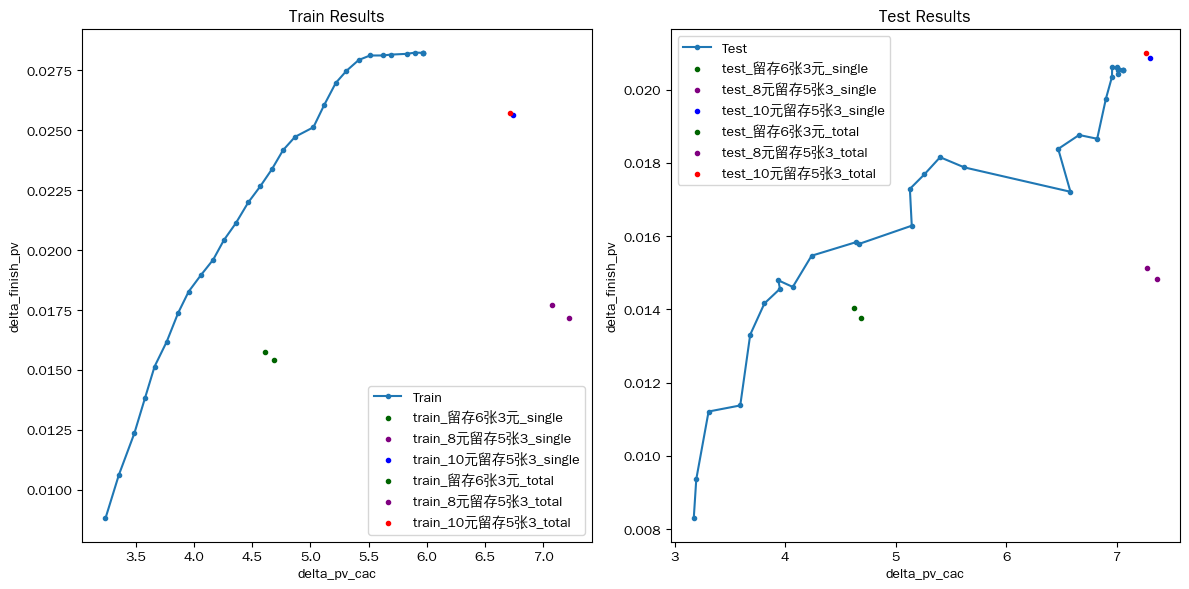


========== running feature_select_v5 | s2 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63', 'left65']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per', 'left65_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['coupon_prob_per', 'left853_per', 'left63_per'], 10000), (['left65_per', 'left853_per', 'left63_per'], 10000), (['left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
7888,0.8,0.9,0.9,0.9,11244
7999,0.8,1.0,1.0,1.0,18398
8999,0.9,1.0,1.0,1.0,22922
9999,1.0,1.0,1.0,1.0,10387


['coupon_prob_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,coupon_prob_per,left853_per,left63_per,counts
0,0.1,0.1,0.1,11784
11,0.1,0.2,0.2,10231
466,0.5,0.7,0.7,10194
688,0.7,0.9,0.9,10942
777,0.8,0.8,0.8,10048


['left65_per', 'left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


...

['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 3 ==============================


,left63_per,counts
0,0.1,34226
1,0.2,73449
2,0.3,68482
3,0.4,54696
4,0.5,57748
5,0.6,52783
6,0.7,44811
7,0.8,41351
8,0.9,33561



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
9,1.0,14204


[13  4  2 18 25 19 22  5  1  7 12 15 16 24 10 21 20  8 14  0 17 26 11 23
 27  6  9  3]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1482       49.0      104.0     425.001   
1              0   8元留存5张3   1455       37.0       79.0     321.804   
2              0      DS空白   6031       71.0      211.0       0.141   
3              0    留存6张3元   2276       56.0      154.0     313.728   
4              1  10元留存5张3   2329       98.0      293.0     958.558   
..           ...       ...    ...        ...        ...         ...   
107           26    留存6张3元   6775      187.0      449.0     729.417   
108           27  10元留存5张3   1885       88.0      238.0     842.639   
109           27   8元留存5张3   1965       64.0      200.0     494.828   
110           27      DS空白   7508      166.0      423.0      20.000   
111           27    留存6张3元   2846      108.0      262.0     493.698   

     delta_cvr  delta_cac  
0     0.035190   

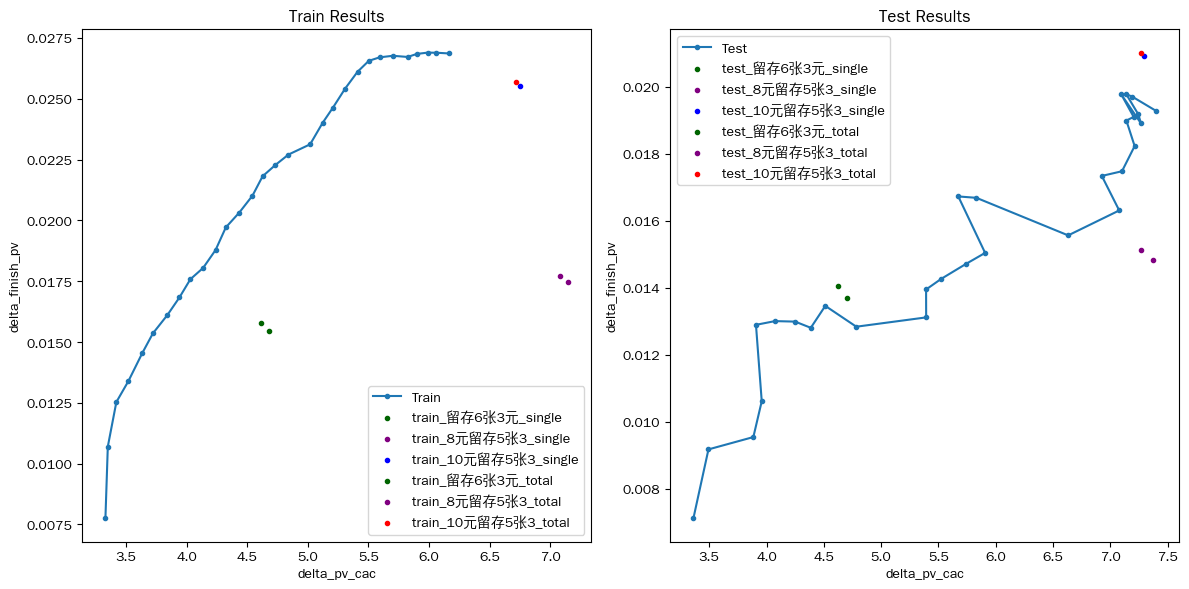


========== running feature_select_v5 | s3 ==========
columns: ['coupon_prob', 'left1053', 'left853', 'left63']
all_columns: ['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per']
stages: [(['coupon_prob_per', 'left1053_per', 'left853_per', 'left63_per'], 10000), (['left1053_per', 'left853_per'], 15000), (['left63_per'], 20000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-22']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '202

,coupon_prob_per,left1053_per,left853_per,left63_per,counts
7888,0.8,0.9,0.9,0.9,11244
7999,0.8,1.0,1.0,1.0,18398
8999,0.9,1.0,1.0,1.0,22922
9999,1.0,1.0,1.0,1.0,10387


['left1053_per', 'left853_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left1053_per,left853_per,counts
0,0.1,0.1,45522
1,0.1,0.2,20608
10,0.2,0.1,25723
11,0.2,0.2,27909
12,0.2,0.3,18682
21,0.3,0.2,24568
22,0.3,0.3,28345
32,0.4,0.3,21580
33,0.4,0.4,29943
34,0.4,0.5,16008


['left63_per'] 20000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left63_per,counts
2,0.3,20953



============================== Final Small Combinations ==============================
Small Combinations (<20000 samples):


,left63_per,counts
0,0.1,11308
1,0.2,16422
3,0.4,19329
4,0.5,13076
5,0.6,8654
6,0.7,13815
7,0.8,15176
8,0.9,16131
9,1.0,6490


[15  6  2  7  4 24  8  1 25 14 21 29 19  9 18 11 10 17 12 23 28  0  5 27
 26 22 20 16 13  3]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1482       49.0      104.0     425.001   
1              0   8元留存5张3   1455       37.0       79.0     321.804   
2              0      DS空白   6031       71.0      211.0       0.141   
3              0    留存6张3元   2276       56.0      154.0     313.728   
4              1  10元留存5张3   2329       98.0      293.0     958.558   
..           ...       ...    ...        ...        ...         ...   
115           28    留存6张3元   4049       13.0       46.0      43.686   
116           29  10元留存5张3  15260      276.0      793.0    2426.414   
117           29   8元留存5张3  15570      244.0      623.0    1489.991   
118           29      DS空白  65763      745.0     2062.0      55.867   
119           29    留存6张3元  23808      377.0      942.0    1360.698   

     delta_cvr  delta_cac  
0     0.035

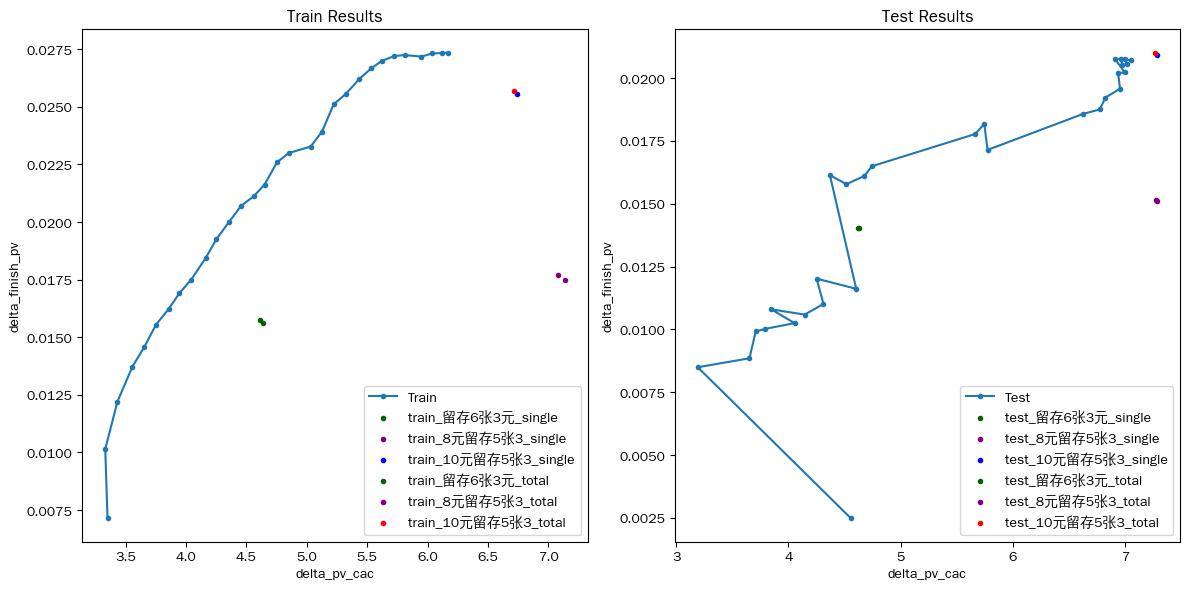


========== running feature_select_v5 | s4 ==========
columns: ['coupon_prob', 'left1053_minus_left853', 'left853_minus_left63', 'left63', 'left1053_minus_left63']
all_columns: ['coupon_prob_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per', 'left1053_minus_left63_per']
stages: [(['coupon_prob_per', 'left1053_minus_left853_per', 'left853_minus_left63_per', 'left63_per'], 10000), (['left1053_minus_left63_per', 'left63_per'], 15000), (['left853_minus_left63_per', 'left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12',

,left1053_minus_left63_per,left63_per,counts
9,0.1,1.0,19300
10,0.2,0.1,15007
20,0.3,0.1,18419
30,0.4,0.1,15141
31,0.4,0.2,15554
41,0.5,0.2,17459
42,0.5,0.3,16660
51,0.6,0.2,15600
52,0.6,0.3,16018
87,0.9,0.8,17915


['left853_minus_left63_per', 'left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================


,left853_minus_left63_per,left63_per,counts
5,0.1,0.6,16895
6,0.1,0.7,15597
13,0.2,0.4,16992
14,0.2,0.5,17989
23,0.3,0.4,17787
76,0.8,0.7,16231



============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left853_minus_left63_per,left63_per,counts
0,0.1,0.1,250
1,0.1,0.2,1410
2,0.1,0.3,3758
3,0.1,0.4,7252
4,0.1,0.5,13685
...,...,...,...
95,1.0,0.6,98
96,1.0,0.7,2056
97,1.0,0.8,3041
98,1.0,0.9,9138


[20 13 17  5 16 10 19  9  2 12  0  1  8  3 14  6 11  4 15 18  7]
rct_pred_data:     bucket_name  exp_name   in_uv  finish_uv  finish_pv  total_cost  \
0             0  10元留存5张3    2561      116.0      450.0    1401.403   
1             0   8元留存5张3    2562      114.0      442.0    1338.525   
2             0      DS空白   10379      150.0      643.0       0.000   
3             0    留存6张3元    3798      156.0      654.0    1147.956   
4             1  10元留存5张3    1939        6.0       20.0      28.049   
..          ...       ...     ...        ...        ...         ...   
79           19    留存6张3元    3303       12.0       50.0     114.015   
80           20  10元留存5张3   61828      813.0     2618.0    8709.591   
81           20   8元留存5张3   61361      691.0     1930.0    5845.001   
82           20      DS空白  264701     1685.0     5761.0     112.424   
83           20    留存6张3元   92965     1028.0     2889.0    5346.299   

    delta_cvr  delta_cac  
0    0.113761   4.810183  
1    0.110569

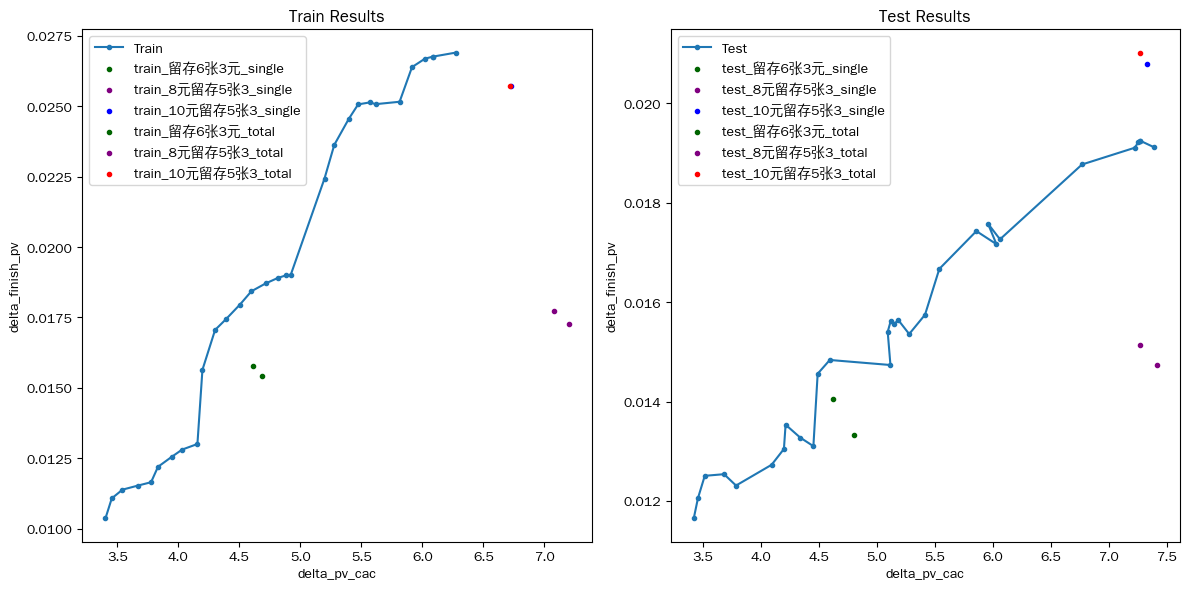


========== running feature_select_v5 | s5 ==========
columns: ['coupon_prob', 'left1053_minus_left63', 'left853_minus_left63', 'left63', 'left853']
all_columns: ['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per', 'left853_per']
stages: [(['coupon_prob_per', 'left1053_minus_left63_per', 'left853_minus_left63_per', 'left63_per'], 10000), (['left853_per', 'left63_per'], 10000), (['left63_per'], 15000)]
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-18']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-19']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-20']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['2026-07-21']
['2026-07-11', '2026-07-12', '2026-07-13', '2026-07-14', '2026-07-15', '2026-07-16', '2026-07-17']
['

,coupon_prob_per,left1053_minus_left63_per,left853_minus_left63_per,left63_per,counts
8999,0.9,1.0,1.0,1.0,10070


['left853_per', 'left63_per'] 10000
step1.....
step2.....
step3.....
step4.....

============================== Stage 1 ==============================


,left853_per,left63_per,counts
0,0.1,0.1,48450
1,0.1,0.2,21838
2,0.1,0.3,10013
10,0.2,0.1,22261
11,0.2,0.2,33485
12,0.2,0.3,20930
21,0.3,0.2,21779
22,0.3,0.3,32810
23,0.3,0.4,16842
32,0.4,0.3,17628


['left63_per'] 15000
step1.....
step2.....
step3.....
step4.....

============================== Stage 2 ==============================

No Large Combinations in this stage

============================== Final Small Combinations ==============================
Small Combinations (<15000 samples):


,left63_per,counts
0,0.1,13229
1,0.2,6578
2,0.3,2706
3,0.4,10996
4,0.5,4997
5,0.6,1909
6,0.7,762
7,0.8,401
8,0.9,276
9,1.0,49


[ 6  1  0 17 28 15 30 21 19 16 10 20  9 18 24  5 11 12  4  8 23 29  7 14
 25 22  2 27 13  3 26]
rct_pred_data:      bucket_name  exp_name  in_uv  finish_uv  finish_pv  total_cost  \
0              0  10元留存5张3   1250      186.0      521.0    1673.709   
1              0   8元留存5张3   1401      186.0      516.0    1515.784   
2              0      DS空白   5284      346.0      914.0       0.000   
3              0    留存6张3元   2135      262.0      680.0    1256.826   
4              1  10元留存5张3   6097       32.0      111.0     164.616   
..           ...       ...    ...        ...        ...         ...   
119           29    留存6张3元   2390       73.0      178.0     364.248   
120           30  10元留存5张3   5321       25.0       65.0     201.372   
121           30   8元留存5张3   5216       27.0       98.0     175.406   
122           30      DS空白  23179      142.0      557.0      25.000   
123           30    留存6张3元   8187       45.0      159.0     187.638   

     delta_cvr  delta_cac  
0     0.

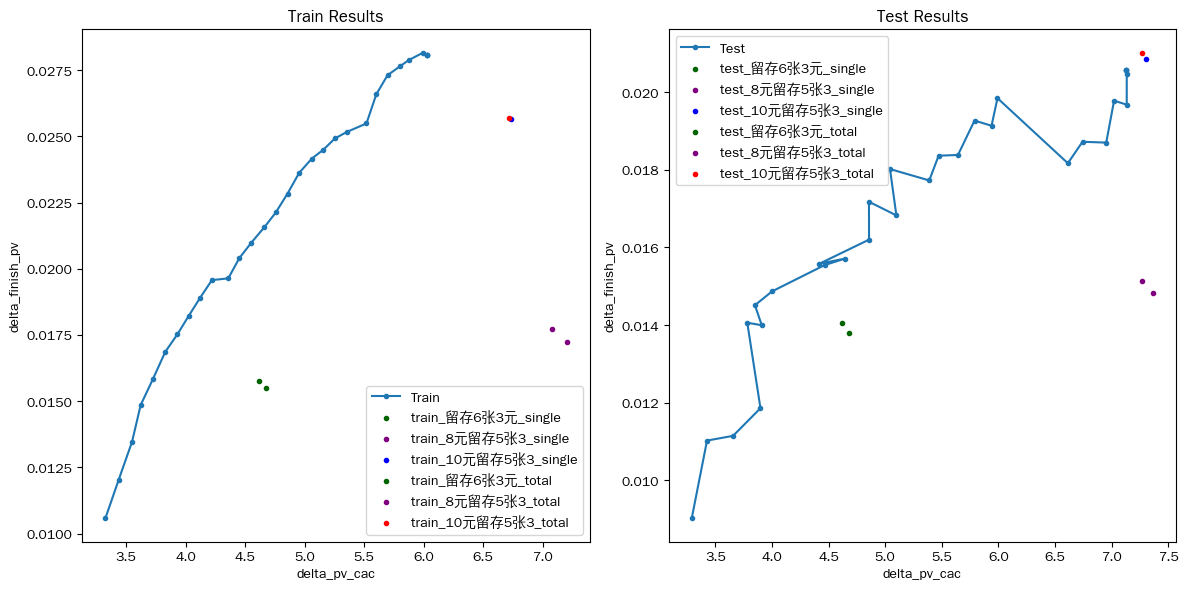

In [101]:


stage_results = {}

for scheme_name, data_df in scheme_dfs.items():
    for stage_name, stages in stage_configs.items():
        print(f'\n========== running {scheme_name} | {stage_name} ==========')

        all_columns = get_all_columns_from_stages(stages)
        columns = get_raw_columns_from_all_columns(all_columns)

        print('columns:', columns)
        print('all_columns:', all_columns)
        print('stages:', stages)

        quantile_thresholds, train_bucketing, val_bucketing = move_threshold_main(
            data_df.copy(),
            opt_group_name_list,
            columns,
            train_dates,
            val_dates
        )

        outputs = main_try(
            train_bucketing.copy(),
            val_bucketing.copy(),
            opt_group_name_list,
            control_name='DS空白',
            cost_list=cost_list,
            all_columns=all_columns,
            stages=stages,
            discount_para=discount_para,
            method=0,
            read_directly=False,
            show_tongbu=True,
            combinations=False,
            simulation_flag=True,
        )

        stage_results[(scheme_name, stage_name)] = {
            'scheme': scheme_name,
            'stage_name': stage_name,
            'columns': columns,
            'all_columns': all_columns,
            'stages': stages,
            'quantile_thresholds': quantile_thresholds,
            'train_df': outputs[0],
            'val_df': outputs[1],
            'bucket_mapping': outputs[2],
            'reverse_mapping': outputs[3],
            'processed_data': outputs[4],
            'next_processed_data': outputs[5],
            'discount_res_list': outputs[6],
            'discount_res_test_list': outputs[7],
            'train_list': outputs[8],
            'test_list': outputs[9],
            'tongbu_list': outputs[10],
            'tongbu_all_list': outputs[11],
        }

In [102]:

def build_stage_result_df(result_list, scheme_name, stage_name, data_type):
    df = pd.DataFrame(
        result_list,
        columns=[
            '约束cac',
            '实际增量cac',
            '实际增量cvr',
            '实际增量首单cvr',
            '留存频次',
        ]
    )
    df['scheme'] = scheme_name
    df['stage_name'] = stage_name
    df['data_type'] = data_type
    return df


summary_list = []

for (scheme_name, stage_name), res in stage_results.items():
    summary_list.append(build_stage_result_df(res['train_list'], scheme_name, stage_name, 'train'))
    summary_list.append(build_stage_result_df(res['test_list'], scheme_name, stage_name, 'test'))

stage_summary_df = pd.concat(summary_list, ignore_index=True)

stage_summary_df[
    ['scheme', 'stage_name', 'data_type', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
0,feature_select_v2,s1,train,3.5,3.345437,0.011013,0.003970,2.774122
1,feature_select_v2,s1,train,3.6,3.394589,0.012283,0.004435,2.769328
2,feature_select_v2,s1,train,3.7,3.488666,0.013351,0.004770,2.798752
3,feature_select_v2,s1,train,3.8,3.587985,0.014176,0.005157,2.748917
4,feature_select_v2,s1,train,3.9,3.690976,0.015114,0.005490,2.752824
...,...,...,...,...,...,...,...,...
595,feature_select_v5,s5,test,6.0,7.133149,0.019675,0.007263,2.708726
596,feature_select_v5,s5,test,6.1,7.133465,0.020455,0.007521,2.719514
597,feature_select_v5,s5,test,6.2,7.129360,0.020563,0.007586,2.710782
598,feature_select_v5,s5,test,6.3,7.129360,0.020563,0.007586,2.710782


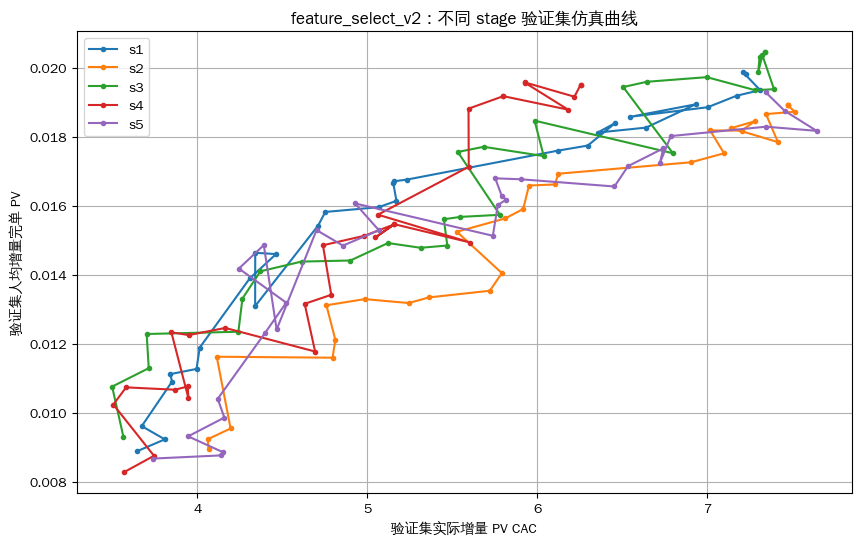

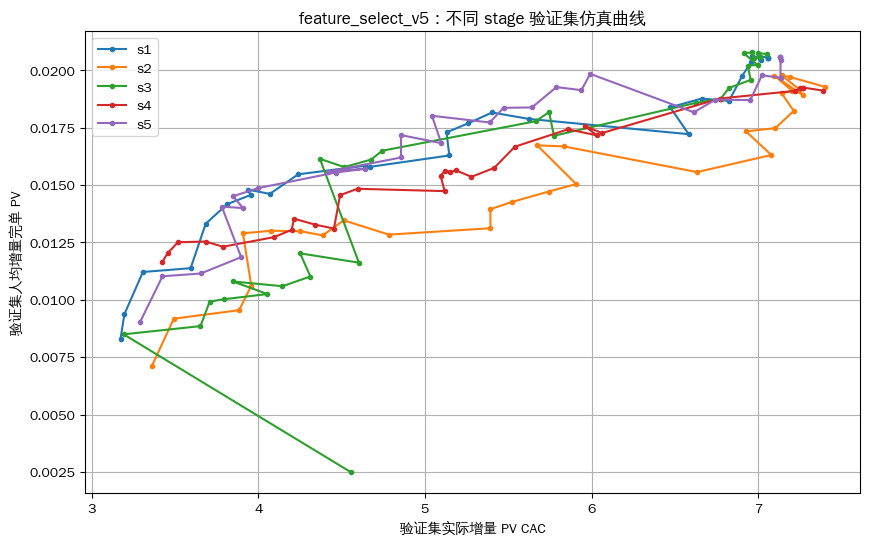

In [103]:
#7. 一个图对应一个方案，图里放不同 stage
for scheme_name in scheme_dfs.keys():
    plt.figure(figsize=(10, 6))

    for stage_name in stage_configs.keys():
        plot_df = stage_summary_df[
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['data_type'] == 'test')
        ].sort_values('约束cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=stage_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{scheme_name}：不同 stage 验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()
    

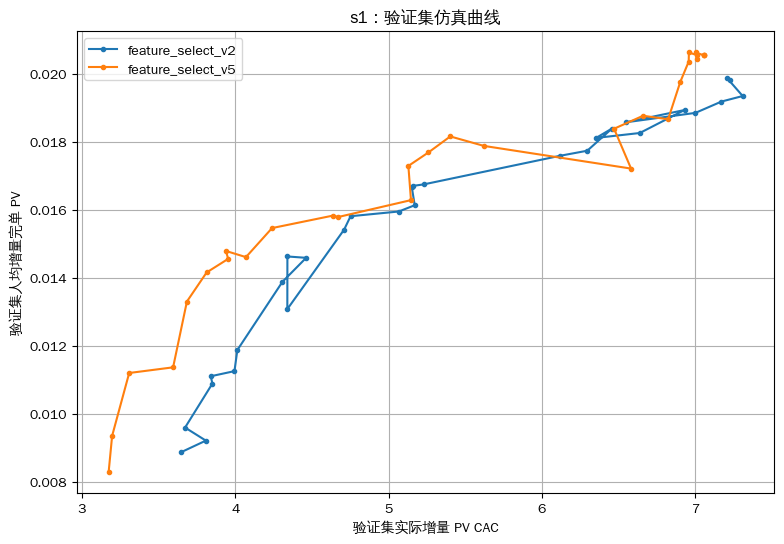

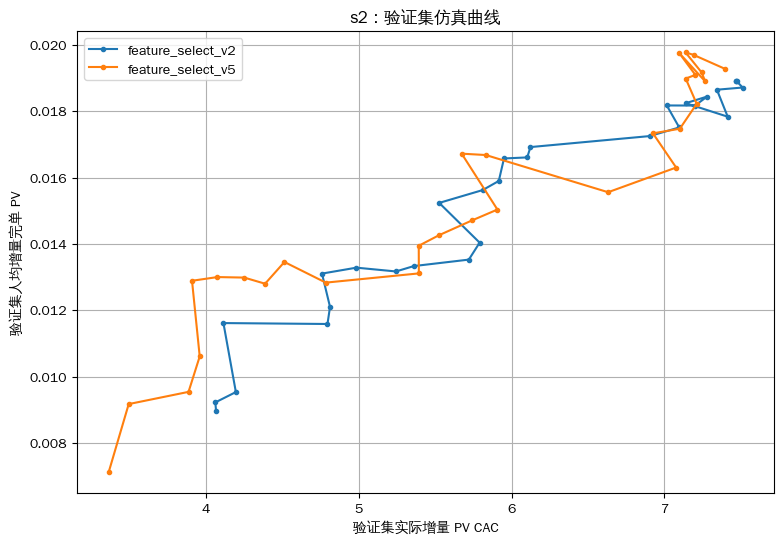

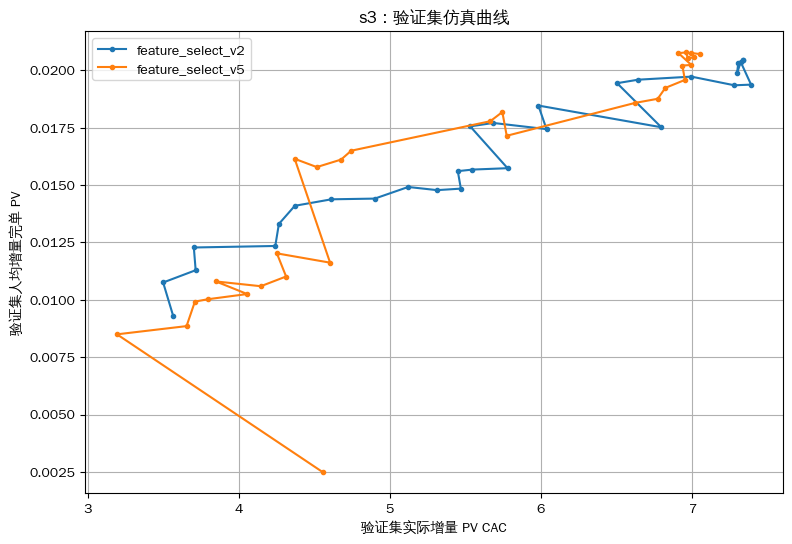

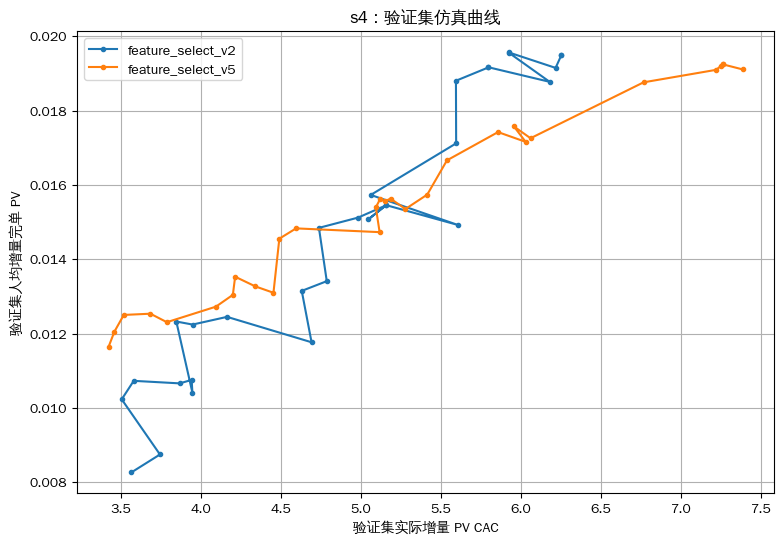

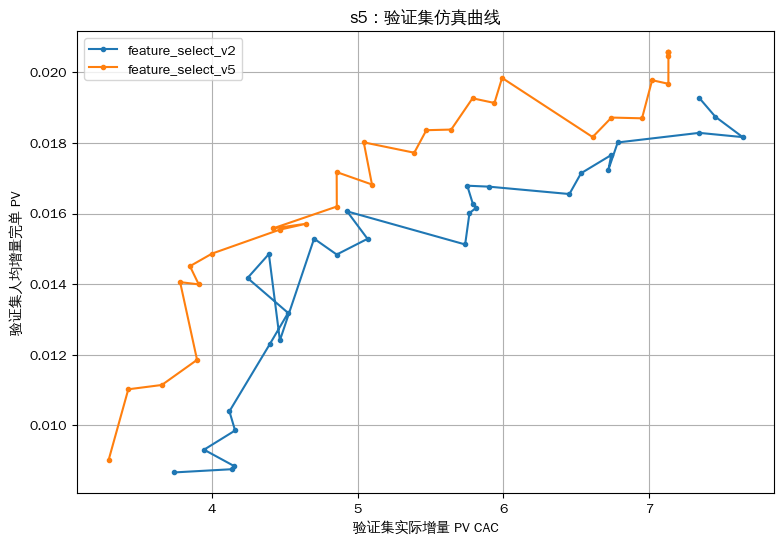

In [104]:
# 6. 一个图对应一个 stage，图里放三个特征方案


for stage_name in stage_configs.keys():
    plt.figure(figsize=(9, 6))

    for scheme_name in scheme_dfs.keys():
        plot_df = stage_summary_df[
            (stage_summary_df['stage_name'] == stage_name) &
            (stage_summary_df['scheme'] == scheme_name) &
            (stage_summary_df['data_type'] == 'test')
         ].sort_values('约束cac')
        # ].sort_values('实际增量cac')

        plt.plot(
            plot_df['实际增量cac'],
            plot_df['实际增量cvr'],
            marker='.',
            label=scheme_name
        )

    plt.xlabel('验证集实际增量 PV CAC')
    plt.ylabel('验证集人均增量完单 PV')
    plt.title(f'{stage_name}：验证集仿真曲线')
    plt.legend()
    plt.grid(True)
    plt.show()

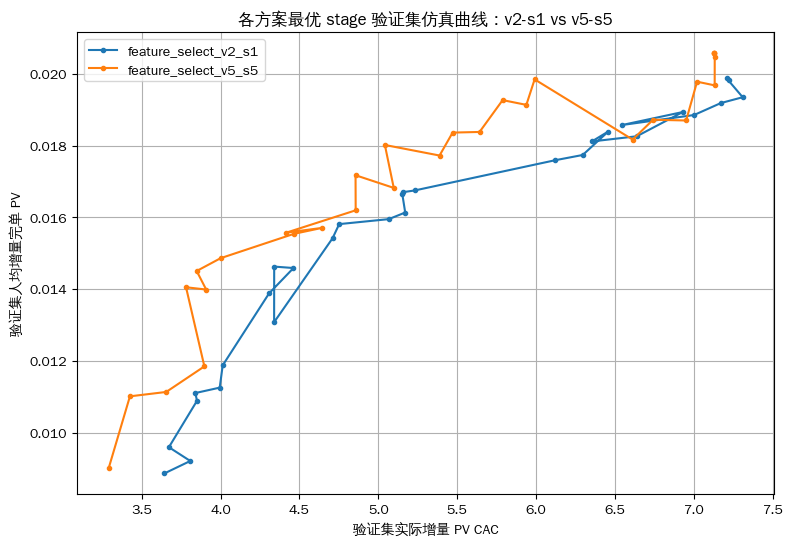

In [107]:
best_stage_map = {
    'feature_select_v2': 's1',
    'feature_select_v5': 's5',
}

plt.figure(figsize=(9, 6))

for scheme_name, stage_name in best_stage_map.items():
    plot_df = stage_summary_df[
        (stage_summary_df['scheme'] == scheme_name) &
        (stage_summary_df['stage_name'] == stage_name) &
        (stage_summary_df['data_type'] == 'test')
    # ].sort_values('实际增量cac')
    # 如果你想按约束 cac 连线，就换成：
      ].sort_values('约束cac')

    plt.plot(
        plot_df['实际增量cac'],
        plot_df['实际增量cvr'],
        marker='.',
        label=f'{scheme_name}_{stage_name}'
    )

plt.xlabel('验证集实际增量 PV CAC')
plt.ylabel('验证集人均增量完单 PV')
plt.title('各方案最优 stage 验证集仿真曲线：v2-s1 vs v5-s5')
plt.legend()
plt.grid(True)
plt.show()

In [108]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['scheme'] == 'feature_select_v5')&
        (stage_summary_df['stage_name'] == 's5') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

,scheme,stage_name,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
570,feature_select_v5,s5,3.5,3.289920,0.009018,0.003373,2.673808
571,feature_select_v5,s5,3.6,3.425148,0.011024,0.004094,2.692637
572,feature_select_v5,s5,3.7,3.655235,0.011145,0.004218,2.642238
573,feature_select_v5,s5,3.8,3.897248,0.011857,0.004696,2.524956
574,feature_select_v5,s5,3.9,3.780885,0.014058,0.005412,2.597562
575,feature_select_v5,s5,4.0,3.908643,0.013994,0.005406,2.588893
576,feature_select_v5,s5,4.1,3.848385,0.014510,0.005506,2.635319
577,feature_select_v5,s5,4.2,4.000517,0.014867,0.005630,2.640883
578,feature_select_v5,s5,4.3,4.463448,0.015542,0.005956,2.609312
579,feature_select_v5,s5,4.4,4.643171,0.015710,0.005984,2.625080


In [109]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['scheme'] == 'feature_select_v2')&
        (stage_summary_df['stage_name'] == 's1') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

,scheme,stage_name,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
30,feature_select_v2,s1,3.5,3.643569,0.008879,0.003344,2.655115
31,feature_select_v2,s1,3.6,3.807898,0.009225,0.003536,2.608731
32,feature_select_v2,s1,3.7,3.672201,0.009608,0.003507,2.739602
33,feature_select_v2,s1,3.8,3.850551,0.010900,0.004154,2.623654
34,feature_select_v2,s1,3.9,3.839739,0.011115,0.004198,2.647557
35,feature_select_v2,s1,4.0,3.994426,0.011265,0.004230,2.663257
36,feature_select_v2,s1,4.1,4.013440,0.011886,0.004389,2.708052
37,feature_select_v2,s1,4.2,4.307408,0.013888,0.005332,2.604630
38,feature_select_v2,s1,4.3,4.462267,0.014593,0.005546,2.631084
39,feature_select_v2,s1,4.4,4.339924,0.014633,0.005828,2.511015


In [34]:
# 每个约束cac下哪个方案最好
best_each_set_cac = (
    test_by_set_cac_df
    .sort_values(['约束cac', '实际增量cvr'], ascending=[True, False])
    .groupby('约束cac')
    .head(1) )

best_each_set_cac[
    ['约束cac', 'scheme', 'stage_name', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,scheme,stage_name,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
25,6.5,baseline,s1,6.488642,0.022206,0.007951,2.792948
26,6.6,baseline,s1,6.313836,0.023146,0.008118,2.851237
427,6.7,replace_order,s1,6.816640,0.022566,0.008182,2.757959
428,6.8,replace_order,s1,6.850040,0.023063,0.008405,2.743803
429,6.9,replace_order,s1,6.904631,0.023046,0.008481,2.717310
30,7.0,baseline,s1,6.939290,0.023263,0.008232,2.826032
431,7.1,replace_order,s1,6.960054,0.024809,0.008759,2.832218
432,7.2,replace_order,s1,7.098209,0.024703,0.008872,2.784351
433,7.3,replace_order,s1,7.042277,0.025060,0.008963,2.795894
34,7.4,baseline,s1,7.218402,0.025201,0.008876,2.839337


In [37]:
test_by_set_cac_df = (
    stage_summary_df[
        (stage_summary_df['stage_name'] == 's3') &
        (stage_summary_df['data_type'] == 'test')
    ]
    .sort_values(['约束cac', 'scheme'])
    [['scheme', 'stage_name', '约束cac', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']]
)

test_by_set_cac_df

# 每个约束cac下哪个方案最好
best_each_set_cac = (
    test_by_set_cac_df
    .sort_values(['约束cac', '实际增量cvr'], ascending=[True, False])
    .groupby('约束cac')
    .head(1)
)

best_each_set_cac[
    ['约束cac', 'scheme', 'stage_name', '实际增量cac', '实际增量cvr', '实际增量首单cvr', '留存频次']
]

,约束cac,scheme,stage_name,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
525,6.5,replace_order,s3,6.548206,0.021642,0.008222,2.632207
126,6.6,baseline,s3,6.629516,0.022240,0.008008,2.777392
127,6.7,baseline,s3,6.741640,0.022848,0.008185,2.791445
128,6.8,baseline,s3,6.948896,0.021958,0.007897,2.780478
129,6.9,baseline,s3,6.998205,0.022763,0.008171,2.785744
130,7.0,baseline,s3,7.258385,0.022633,0.008188,2.764054
531,7.1,replace_order,s3,7.089969,0.023041,0.008584,2.684029
132,7.2,baseline,s3,7.260061,0.023762,0.008605,2.761534
133,7.3,baseline,s3,7.324514,0.023853,0.008758,2.723396
134,7.4,baseline,s3,7.326597,0.024186,0.008856,2.730965


In [53]:
baseline_table
# baseline_table.to_excel('baseline_table.xlsx', index=False)

,scheme,stage_name,data_type,约束cac,实际增量cac,实际增量cvr,实际增量首单cvr,留存频次
25,baseline,s1,test,6.5,6.488642,0.022206,0.007951,2.792948
26,baseline,s1,test,6.6,6.313836,0.023146,0.008118,2.851237
27,baseline,s1,test,6.7,6.824765,0.019716,0.007156,2.755114
28,baseline,s1,test,6.8,6.953936,0.021024,0.007650,2.748336
29,baseline,s1,test,6.9,6.912476,0.022698,0.008113,2.797620
30,baseline,s1,test,7.0,6.939290,0.023263,0.008232,2.826032
31,baseline,s1,test,7.1,7.172724,0.023416,0.008408,2.784886
32,baseline,s1,test,7.2,7.387116,0.024012,0.008519,2.818618
33,baseline,s1,test,7.3,7.423570,0.024225,0.008693,2.786538
34,baseline,s1,test,7.4,7.218402,0.025201,0.008876,2.839337
